# NFIP Redacted Claims (v3), 2020–2025: Exploratory Data Analysis and Preprocessing

**DSC 411/511, Semester Project, Modules 1 and 2** · Venkat Repaka, Ritik Gaire

This notebook profiles the FEMA OpenFEMA *NFIP Redacted Claims v3* data before modeling. The order follows what the project brief grades:

| # | Section | Brief requirement it covers |
|---|---|---|
| 1 | Load the data and report full statistics | rows, columns, file size, date range |
| 2 | Classify every attribute by type and role | attribute-type table (nominal / ordinal / interval / ratio) |
| 3 | Disguised missing values (sentinels, placeholders) | data quality |
| 4 | Missing data: how much, where, and **why** (structural / MCAR / MAR / MNAR) | missing values per column, kind of missingness |
| 5 | Duplicates | duplicates |
| 6 | Which features to drop, and why | defend every preprocessing decision |
| 7 | Time split, then how each feature is imputed, with two validation experiments | at least 2 imputation strategies; no leakage |
| 8 | Outliers and noise | outliers and noise |
| 9 | Feature engineering | at least 2 engineered features |
| 10 | EDA charts, each matched to the attribute type it shows | at least 4 EDA plots |
| 11 | Encoding (nominal vs ordinal) and scaling | encoding and scaling |
| 12 | Shape before/after and the decision log | shape before and after the pipeline |

Feature selection (filter, embedded and wrapper methods, plus a leakage experiment) is in the companion notebook **`02_feature_selection.ipynb`**, which reads this notebook's saved outputs.

**Research questions this EDA supports** (from the proposal):

* **RQ1, Regression.** How much will FEMA pay on the building part of a claim (`amountPaidOnBuildingClaim`)?
* **RQ2, Classification.** Is a claim *high severity*, meaning in the top 20% of `buildingDamageAmount`?
* **RQ3, Clustering + PCA.** Do flood-zone, elevation, construction and geography features form distinct risk profiles?

Because of these targets, some columns are kept for EDA but **must never be predictors** (payments, recoveries, non-payment reasons). Section 2 labels them.

In [1]:
import warnings, json
from pathlib import Path
from decimal import Decimal
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm, ListedColormap
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

SEED = 42
YEARS = (2020, 2025)          # analysis window by yearOfLoss
TRAIN_MAX_YEAR = 2023         # time split: train = 2020–2023, test = 2024–2025 (as in nfip_claims/scripts)
FEMA_PUBLISHED_ROWS = 2_725_989   # record count on the OpenFEMA dataset page
rng = np.random.default_rng(SEED)

# ---- one consistent, colour-blind-checked palette for every chart --------------------
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, GRAY = "#0b0b0b", "#52514e", "#e4e3df", "#a3a29c"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=C), "font.size": 10,
})

# ---- paths ------------------------------------------------------------------------------
NB_DIR = Path.cwd()
PROJECT = NB_DIR.parent if NB_DIR.name == "notebooks" else NB_DIR
FIG_DIR = PROJECT / "notebooks" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT / "notebooks" / "outputs"; OUT_DIR.mkdir(parents=True, exist_ok=True)

BULK_URL = "https://www.fema.gov/about/reports-and-data/openfema/v3/NfipClaimsV3.parquet"
CANDIDATES = [PROJECT / "nfip_claims" / "raw" / "NfipClaimsV3_full.parquet",
              PROJECT.parent / "project" / "NfipClaimsV3.parquet"]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:                       # first run on a new machine: download the public file once
    import requests
    DATA_PATH = CANDIDATES[0]; DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    with requests.get(BULK_URL, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(DATA_PATH, "wb") as fh:
            for chunk in r.iter_content(1 << 20): fh.write(chunk)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def pct(x, d=1): return f"{100*x:.{d}f}%"
print("data file:", DATA_PATH)

data file: /Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet


## 1. Load the data and report full statistics

**Source.** FEMA, OpenFEMA dataset *FIMA NFIP Redacted Claims v3* ([dataset page](https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3)). U.S. government work, public domain; cite FEMA/OpenFEMA.
**Grain.** One row is one redacted claim record with its own `id`. It is not a policy, and it cannot be joined to a policy, because the policy number is withheld.
**Snapshot.** The file is refreshed about monthly and lags FEMA's system of record. Every total below is "as of `asOfDate`", so the most recent loss year is incomplete.

In [2]:
full = pd.read_parquet(DATA_PATH)
dol_full = pd.to_datetime(full["dateOfLoss"], errors="coerce")

stats_full = pd.Series({
    "file": DATA_PATH.name,
    "file size on disk (MB)": round(DATA_PATH.stat().st_size / 1e6, 1),
    "rows (national file)": f"{len(full):,}  (FEMA page lists {FEMA_PUBLISHED_ROWS:,}: {'match' if len(full) == FEMA_PUBLISHED_ROWS else 'MISMATCH'})",
    "columns": full.shape[1],
    "dateOfLoss range (national)": f"{dol_full.min().date()} → {dol_full.max().date()}",
    "asOfDate (snapshot)": ", ".join(str(x)[:10] for x in full["asOfDate"].unique()),
})
raw = full[full["yearOfLoss"].between(*YEARS)].reset_index(drop=True)
del full, dol_full
stats_full["yearOfLoss == year(dateOfLoss)"] = "all rows" if (pd.to_datetime(raw["dateOfLoss"]).dt.year == raw["yearOfLoss"]).all() else "MISMATCH"
stats_full["rows in analysis window"] = f"{len(raw):,}  (yearOfLoss {YEARS[0]}–{YEARS[1]})"
stats_full["in-memory size of window (MB)"] = round(raw.memory_usage(deep=True).sum() / 1e6, 1)
stats_full.to_frame("value")

,value
file,NfipClaimsV3.parquet
file size on disk (MB),163.8
rows (national file),"2,725,989 (FEMA page lists 2,725,989: match)"
columns,84
dateOfLoss range (national),1978-01-01 → 2026-09-07
asOfDate (snapshot),2026-09-08
yearOfLoss == year(dateOfLoss),all rows
rows in analysis window,"277,033 (yearOfLoss 2020–2025)"
in-memory size of window (MB),788.1


### 1.1 Fix storage types first

OpenFEMA's Parquet stores money and elevation as Python `Decimal` objects and dates as Python `date` objects. Both arrive as `object` dtype, so pandas would treat them as text. They are converted to `float64` and `datetime64` **before** any profiling. Otherwise `describe()`, correlations and missing-value checks would silently skip them.

In [3]:
def first_valid(s):
    i = s.first_valid_index()
    return None if i is None else s.loc[i]

DECIMAL_COLS = [c for c in raw.columns if raw[c].dtype == object and isinstance(first_valid(raw[c]), Decimal)]
DATE_COLS    = [c for c in raw.columns if raw[c].dtype == object and isinstance(first_valid(raw[c]), dt.date)]
for c in DECIMAL_COLS: raw[c] = raw[c].astype("float64")
LO, HI = dt.date(1800, 1, 1), dt.date(2030, 12, 31)
bad_dates = {}
for c in DATE_COLS:                       # out-of-range placeholders (e.g. year 0001 / 9999) cannot be valid
    ok = raw[c].map(lambda x: x is None or (LO <= x <= HI))
    bad_dates[c] = int((~ok).sum())
    raw[c] = pd.to_datetime(raw[c].where(ok), errors="coerce").astype("datetime64[ns]")
raw["asOfDate"] = raw["asOfDate"].dt.tz_localize(None)

print(f"Decimal -> float64 ({len(DECIMAL_COLS)}):", DECIMAL_COLS)
print(f"date    -> datetime ({len(DATE_COLS)}):", DATE_COLS)
print("out-of-range dates (before 1800 / after 2030) set to NaT:", {k: v for k, v in bad_dates.items() if v})
print("\nrows per yearOfLoss:"); print(raw["yearOfLoss"].value_counts().sort_index().to_string())

Decimal -> float64 (16): ['baseFloodElevation', 'lowestAdjacentGrade', 'lowestFloorElevation', 'amountPaidOnBuildingClaim', 'amountPaidOnContentsClaim', 'amountPaidOnIncreasedCostOfComplianceClaim', 'netBuildingPaymentAmount', 'netContentsPaymentAmount', 'netIccPaymentAmount', 'latitude', 'longitude', 'totalSalvageRecovery', 'totalBldgClaimPmtRecovery', 'totalContentsClaimPmtRecovery', 'totalIccClaimPmtRecovery', 'totalSubrogationRecovery']
date    -> datetime (6): ['dateOfLoss', 'originalConstructionDate', 'originalNBDate', 'openDate', 'mostRecentRecoveryDate', 'mostRecentPaymentDate']
out-of-range dates (before 1800 / after 2030) set to NaT: {'originalConstructionDate': 270, 'originalNBDate': 2}

rows per yearOfLoss:
yearOfLoss
2020     33185
2021     46699
2022     60262
2023     21690
2024    102054
2025     13143


## 2. Attribute types and roles

Every column is classified on two axes:

* **Measurement scale** (Stevens): *nominal* (labels only), *binary* (two-level nominal), *ordinal* (ordered labels), *interval* (differences matter, zero is arbitrary: dates, elevations, depths that can be negative), *ratio* (true zero: dollars, counts).
* **Role in the project.** This decides what may be used as a predictor:
  * `target`: what an RQ predicts.
  * `post-loss (adjuster)`: recorded during claim adjustment, after the flood. Usable for EDA and clustering. It is **leakage** for an early-triage model.
  * `outcome / leakage`: payments, recoveries, non-payment reasons. Never a predictor.
  * `pre-loss feature`: policy and building facts known before the flood.
  * `geography`, `event / time`, `identifier / metadata`.

In [4]:
A = {  # column: (scale, role)
 "id": ("nominal (identifier)", "identifier / metadata"), "asOfDate": ("interval (date)", "identifier / metadata"),
 "dateOfLoss": ("interval (date)", "event / time"), "yearOfLoss": ("interval (year)", "event / time"),
 "openDate": ("interval (date)", "event / time"), "floodEvent": ("nominal", "event / time"),
 "eventDesignationNumber": ("nominal", "event / time"), "ficoNumber": ("nominal", "event / time"),
 "amountPaidOnBuildingClaim": ("ratio ($)", "target"), "buildingDamageAmount": ("ratio ($)", "target"),
 "amountPaidOnContentsClaim": ("ratio ($)", "outcome / leakage"), "amountPaidOnIncreasedCostOfComplianceClaim": ("ratio ($)", "outcome / leakage"),
 "netBuildingPaymentAmount": ("ratio ($)", "outcome / leakage"), "netContentsPaymentAmount": ("ratio ($)", "outcome / leakage"),
 "netIccPaymentAmount": ("ratio ($)", "outcome / leakage"), "mostRecentPaymentDate": ("interval (date)", "outcome / leakage"),
 "mostRecentRecoveryDate": ("interval (date)", "outcome / leakage"), "nonPaymentReasonBuilding": ("nominal", "outcome / leakage"),
 "nonPaymentReasonContents": ("nominal", "outcome / leakage"), "totalSalvageRecovery": ("ratio ($)", "outcome / leakage"),
 "totalBldgClaimPmtRecovery": ("ratio ($)", "outcome / leakage"), "totalContentsClaimPmtRecovery": ("ratio ($)", "outcome / leakage"),
 "totalIccClaimPmtRecovery": ("ratio ($)", "outcome / leakage"), "totalSubrogationRecovery": ("ratio ($)", "outcome / leakage"),
 "contentsDamageAmount": ("ratio ($)", "post-loss (adjuster)"), "buildingPropertyValue": ("ratio ($)", "post-loss (adjuster)"),
 "contentsPropertyValue": ("ratio ($)", "post-loss (adjuster)"), "buildingReplacementCost": ("ratio ($)", "post-loss (adjuster)"),
 "contentsReplacementCost": ("ratio ($)", "post-loss (adjuster)"), "waterDepth": ("interval (inches)", "post-loss (adjuster)"),
 "interiorWaterDepth": ("interval (inches)", "post-loss (adjuster)"), "exteriorWaterDepth": ("interval (inches)", "post-loss (adjuster)"),
 "floodWaterDuration": ("ratio (hours)", "post-loss (adjuster)"), "floodCharacteristicsIndicator": ("nominal", "post-loss (adjuster)"),
 "causeOfDamage": ("nominal", "post-loss (adjuster)"), "replacementCostBasis": ("binary", "post-loss (adjuster)"),
 "policyCount": ("ratio (count)", "pre-loss feature"), "numberOfUnits": ("ratio (count)", "pre-loss feature"),
 "totalBuildingInsuranceCoverage": ("ratio ($)", "pre-loss feature"), "totalContentsInsuranceCoverage": ("ratio ($)", "pre-loss feature"),
 "iccCoverage": ("ratio ($)", "pre-loss feature"), "buildingDeductibleCode": ("ordinal (code → $)", "pre-loss feature"),
 "contentsDeductibleCode": ("ordinal (code → $)", "pre-loss feature"), "crsClassCode": ("ordinal (1 best … 10 none)", "pre-loss feature"),
 "numberOfFloorsInTheInsuredBuilding": ("ordinal codes 1–3, nominal 4–6", "pre-loss feature"),
 "ratedFloodZone": ("nominal", "pre-loss feature"), "floodZoneCurrent": ("nominal", "pre-loss feature"),
 "rateMethod": ("nominal", "pre-loss feature"), "occupancyType": ("nominal", "pre-loss feature"),
 "foundationType": ("nominal", "pre-loss feature"), "basementEnclosureCrawlspaceType": ("nominal", "pre-loss feature"),
 "locationOfContents": ("nominal", "pre-loss feature"), "obstructionType": ("nominal", "pre-loss feature"),
 "buildingDescriptionCode": ("nominal", "pre-loss feature"), "condominiumCoverageTypeCode": ("nominal", "pre-loss feature"),
 "elevationCertificateIndicator": ("nominal", "pre-loss feature"), "disasterAssistanceCoverageRequired": ("nominal", "pre-loss feature"),
 "elevationDifference": ("interval (ft)", "pre-loss feature"), "baseFloodElevation": ("interval (ft, datum)", "pre-loss feature"),
 "lowestFloorElevation": ("interval (ft, datum)", "pre-loss feature"), "lowestAdjacentGrade": ("interval (ft, datum)", "pre-loss feature"),
 "originalConstructionDate": ("interval (date)", "pre-loss feature"), "originalNBDate": ("interval (date)", "pre-loss feature"),
 "state": ("nominal", "geography"), "reportedCity": ("nominal", "geography"), "reportedZipCode": ("nominal", "geography"),
 "countyCode": ("nominal", "geography"), "censusGeoid": ("nominal", "geography"),
 "latitude": ("interval (deg, 0.1 precision)", "geography"), "longitude": ("interval (deg, 0.1 precision)", "geography"),
 "nfipRatedCommunityNumber": ("nominal", "geography"), "nfipCommunityNumberCurrent": ("nominal", "geography"),
 "nfipCommunityName": ("nominal", "geography"),
}
for c in raw.columns:                                     # all remaining columns are boolean policy flags
    A.setdefault(c, ("binary", "pre-loss feature"))
assert set(A) == set(raw.columns), set(A) ^ set(raw.columns)

attr = pd.DataFrame({
    "scale": {c: A[c][0] for c in raw.columns},
    "role": {c: A[c][1] for c in raw.columns},
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
})
attr["scale_group"] = attr["scale"].str.split(" ").str[0]
DICT_PATH = PROJECT / "nfip_claims" / "column_dictionary.csv"      # FEMA field descriptions (OpenFEMA data dictionary)
if DICT_PATH.exists():
    attr["FEMA description"] = pd.read_csv(DICT_PATH).set_index("column")["description"].reindex(attr.index)
display(pd.crosstab(attr["role"], attr["scale_group"], margins=True, margins_name="total"))
attr.sort_values(["role", "scale_group"])

scale_group,binary,interval,nominal,ordinal,ratio,total
role,,,,,,
event / time,0,3,3,0,0,6
geography,0,2,8,0,0,10
identifier / metadata,0,1,1,0,0,2
outcome / leakage,0,2,2,0,10,14
post-loss (adjuster),1,3,2,0,6,12
pre-loss feature,11,6,12,4,5,38
target,0,0,0,0,2,2
total,12,17,28,4,23,84


,scale,role,dtype,n_unique,scale_group,FEMA description
dateOfLoss,interval (date),event / time,datetime64[ns],2176,interval,"Date on which water first entered the insured building. When time is not specified in the field, it will default to ..."
yearOfLoss,interval (year),event / time,int16,6,interval,Year in which the flood loss occurred
openDate,interval (date),event / time,datetime64[ns],2279,interval,Date the claim was opened in the system.
eventDesignationNumber,nominal,event / time,object,67,nominal,The Event Designation Number (EDN) is a unique identifier established for a catastrophe flood event. NOTE: EDN has r...
ficoNumber,nominal,event / time,float64,0,nominal,Number assigned at the time of a significant flooding event to uniquely identify each affected state. A public bulle...
...,...,...,...,...,...,...
totalContentsInsuranceCoverage,ratio ($),pre-loss feature,float64,1175,ratio,Total Insurance Amount in whole dollars on the Contents
iccCoverage,ratio ($),pre-loss feature,float64,1,ratio,Amount of Increased Cost of Compliance (ICC) coverage for building in whole dollars. NOTE: ICC coverage is the cover...
numberOfUnits,ratio (count),pre-loss feature,float64,340,ratio,The number of residential and nonresidential units covered by the Condominium Master Policy
amountPaidOnBuildingClaim,ratio ($),target,float64,195669,ratio,"Dollar amount paid on the building claim. In some instances, a negative amount may appear which occurs when a check ..."


The `FEMA description` column comes from the OpenFEMA field dictionary (saved by the project scripts in `nfip_claims/column_dictionary.csv`), so every column's source and meaning is documented.

**Takeaway.** The table has all four Stevens scales plus binary flags. Encoding and distance choices will therefore matter (Section 11). It also shows that **only about half of the 84 columns are legitimate predictors**. The rest are targets, payment or recovery outcomes, adjuster measurements taken after the flood, or keys.

## 3. Disguised missing values: look before you count

`df.isna()` only finds *explicit* blanks. A value that **means "unknown" but is stored as a number** is more dangerous, because it enters every mean and correlation as if it were real. Each rule below was checked against the column's distribution or FEMA's field definition before being applied:

| Pattern | Evidence | Treatment |
|---|---|---|
| `waterDepth == 99` | A spike of ~12.5k rows at exactly 99", while 98" and 100" are rare (chart below). A data-entry "unknown" code. | → NaN |
| `interior/exteriorWaterDepth ≥ 999` | 999 / 9600 inches (80–800 ft) are physically impossible for a building flood | → NaN |
| elevation fields `|x| ≥ 9000`; `elevationDifference` `|x| ≥ 500` | 9990 / 9999 placeholders in BFE / floor / grade elevations; a lowest floor 500+ ft from its BFE is impossible (values like −9980, 987) | → NaN |
| `contentsPropertyValue < 0` | a `-1` code | → NaN |
| `buildingPropertyValue` or `buildingReplacementCost == 0` while building coverage > 0 | An insured building cannot have $0 value. The zero means "not recorded". | → NaN |
| `buildingDamageAmount` / `contentsDamageAmount == 1` | 2.4k claims with "$1 of damage" have a **median building payment of ~$47k**. The $1 is a placeholder, not an assessment. | → NaN |
| `reportedCity == "Currently Unavailable"` | FEMA documents the city field as currently unavailable (100% of rows) | the whole column is missing |
| `foundationType == "0"` | Code 0 is not in FEMA's documented code list | → "unknown" |
| dates on `1900-01-01`, or before 1800 / after 2030 | Placeholder or impossible dates (e.g. year 1069) | → NaT |

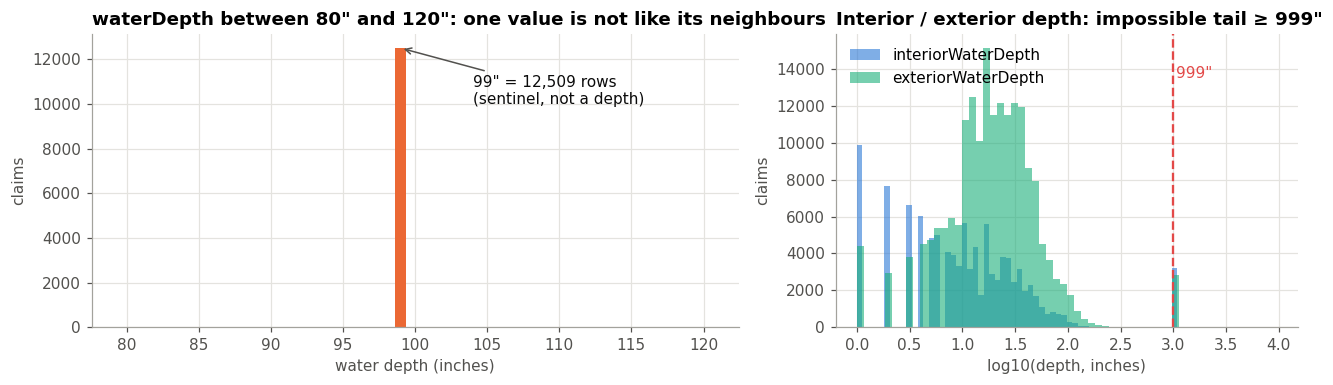

In [5]:
wd = raw["waterDepth"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
vc = wd[(wd >= 80) & (wd <= 120)].value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=[C[1] if v == 99 else C[0] for v in vc.index], width=0.8)
ax[0].annotate(f"99\" = {int(vc.get(99, 0)):,} rows\n(sentinel, not a depth)", xy=(99, vc.get(99, 0)),
               xytext=(104, vc.get(99, 0) * 0.8), color=INK, arrowprops=dict(arrowstyle="->", color=INK2))
ax[0].set(title="waterDepth between 80\" and 120\": one value is not like its neighbours",
          xlabel="water depth (inches)", ylabel="claims")
for col, colr in [("interiorWaterDepth", C[0]), ("exteriorWaterDepth", C[2])]:
    s = raw[col].dropna()
    ax[1].hist(np.log10(s[s > 0]), bins=60, alpha=0.6, color=colr, label=col)
ax[1].axvline(np.log10(999), color=C[7], ls="--", lw=1.5); ax[1].text(np.log10(999) * 1.01, ax[1].get_ylim()[1] * 0.85, "999\"", color=C[7])
ax[1].set(title="Interior / exterior depth: impossible tail ≥ 999\"", xlabel="log10(depth, inches)", ylabel="claims"); ax[1].legend()
plt.tight_layout(); savefig("03_sentinels"); plt.show()

In [6]:
print("net building payment on rows where buildingDamageAmount == 1:")
print(raw.loc[raw["buildingDamageAmount"] == 1, "netBuildingPaymentAmount"].describe().round(0).to_string())
df = raw.copy()
bcov = df["totalBuildingInsuranceCoverage"] > 0
rules = [
    ("waterDepth", df["waterDepth"] == 99, "== 99 sentinel"),
    ("interiorWaterDepth", df["interiorWaterDepth"] >= 999, ">= 999 sentinel / impossible"),
    ("exteriorWaterDepth", df["exteriorWaterDepth"] >= 999, ">= 999 sentinel / impossible"),
    ("elevationDifference", df["elevationDifference"].abs() >= 500, "|x| >= 500 ft (e.g. -9980, 987): impossible for a floor vs BFE"),
    ("baseFloodElevation", df["baseFloodElevation"].abs() >= 9000, "|x| >= 9000 placeholder"),
    ("lowestFloorElevation", df["lowestFloorElevation"].abs() >= 9000, "|x| >= 9000 placeholder"),
    ("lowestAdjacentGrade", df["lowestAdjacentGrade"].abs() >= 9000, "|x| >= 9000 placeholder"),
    ("buildingPropertyValue", (df["buildingPropertyValue"] == 0) & bcov, "0 with building coverage > 0"),
    ("buildingReplacementCost", (df["buildingReplacementCost"] == 0) & bcov, "0 with building coverage > 0"),
    ("contentsPropertyValue", df["contentsPropertyValue"] < 0, "negative value (-1 code)"),
    ("buildingDamageAmount", df["buildingDamageAmount"] == 1, "$1 placeholder (median payment on these rows ≈ $47k)"),
    ("contentsDamageAmount", df["contentsDamageAmount"] == 1, "$1 placeholder"),
    ("reportedCity", df["reportedCity"].eq("Currently Unavailable"), "'Currently Unavailable'"),
    ("originalConstructionDate", df["originalConstructionDate"].eq("1900-01-01"), "1900-01-01 placeholder date"),
    ("mostRecentPaymentDate", df["mostRecentPaymentDate"].eq("1900-01-01"), "1900-01-01 placeholder date"),
]
log = []
for col, mask, why in rules:
    log.append({"column": col, "rule": why, "rows recoded to NaN": int(mask.sum()), "% of rows": round(100 * mask.mean(), 2)})
    df.loc[mask, col] = np.nan
df.loc[df["foundationType"] == "0", "foundationType"] = np.nan
log.append({"column": "foundationType", "rule": "undocumented code '0'", "rows recoded to NaN": int(raw["foundationType"].eq("0").sum()),
            "% of rows": round(100 * raw["foundationType"].eq("0").mean(), 2)})
sentinel_log = pd.DataFrame(log)
sentinel_log

net building payment on rows where buildingDamageAmount == 1:
count       2376.0
mean       73100.0
std        95220.0
min      -201668.0
25%        10565.0
50%        47174.0
75%       110224.0
max      2649133.0


,column,rule,rows recoded to NaN,% of rows
0,waterDepth,== 99 sentinel,12509,4.52
1,interiorWaterDepth,>= 999 sentinel / impossible,3190,1.15
2,exteriorWaterDepth,>= 999 sentinel / impossible,2912,1.05
3,elevationDifference,"|x| >= 500 ft (e.g. -9980, 987): impossible for a floor vs BFE",13,0.00
4,baseFloodElevation,|x| >= 9000 placeholder,968,0.35
5,lowestFloorElevation,|x| >= 9000 placeholder,139,0.05
6,lowestAdjacentGrade,|x| >= 9000 placeholder,42,0.02
7,buildingPropertyValue,0 with building coverage > 0,26773,9.66
8,buildingReplacementCost,0 with building coverage > 0,26343,9.51
9,contentsPropertyValue,negative value (-1 code),1,0.00


**Takeaway.** About **27k building-value/replacement-cost zeros**, **12.5k water-depth sentinels** and **2.4k "$1" damage amounts** look like real numbers. Without this step they would make "$0 house value" the most common value and pull the depth mean up by about 5 inches. From here on, `df` is the recoded frame and `raw` stays untouched for comparison.

## 4. Missing data

### 4.1 How much is missing, column by column
Two counts are shown: **explicit** (NaN in the file) and **true** (after the disguised values in Section 3 are recoded).

In [7]:
miss = pd.DataFrame({
    "explicit_n": raw.isna().sum(),
    "explicit_%": (raw.isna().mean() * 100).round(2),
    "true_n": df.isna().sum(),
    "true_%": (df.isna().mean() * 100).round(2),
    "role": attr["role"], "scale": attr["scale"],
})
miss = miss.sort_values("true_%", ascending=False)
print(f"columns with any missing (true): {(miss['true_n'] > 0).sum()} of {df.shape[1]}")
print(f"cells missing overall: {pct(df.isna().values.mean())}   |   rows with no missing value at all: {(~df.isna().any(axis=1)).sum():,}")
miss[miss["true_n"] > 0]

columns with any missing (true): 59 of 84


cells missing overall: 26.2%   |   rows with no missing value at all: 0


,explicit_n,explicit_%,true_n,true_%,role,scale
ficoNumber,277033,100.00,277033,100.00,event / time,nominal
floodCharacteristicsIndicator,277033,100.00,277033,100.00,post-loss (adjuster),nominal
reportedCity,0,0.00,277033,100.00,geography,nominal
mostRecentRecoveryDate,276630,99.85,276630,99.85,outcome / leakage,interval (date)
totalSubrogationRecovery,276630,99.85,276630,99.85,outcome / leakage,ratio ($)
totalIccClaimPmtRecovery,276630,99.85,276630,99.85,outcome / leakage,ratio ($)
totalContentsClaimPmtRecovery,276630,99.85,276630,99.85,outcome / leakage,ratio ($)
totalSalvageRecovery,276630,99.85,276630,99.85,outcome / leakage,ratio ($)
totalBldgClaimPmtRecovery,276630,99.85,276630,99.85,outcome / leakage,ratio ($)
floodWaterDuration,261438,94.37,261438,94.37,post-loss (adjuster),ratio (hours)


No row is complete. Listwise deletion (`dropna()`) would delete the whole dataset, so **deletion is not an option**. Each column has to be handled on its own merits.

### 4.2 Missingness has structure: matrix and nullity correlation
The left panel is a missingness matrix for a random sample of 3,000 claims sorted by date of loss (dark = missing). The right panel shows correlations between the *missing indicators*. A value near 1 means two columns are blank on the same rows, so they share one cause.

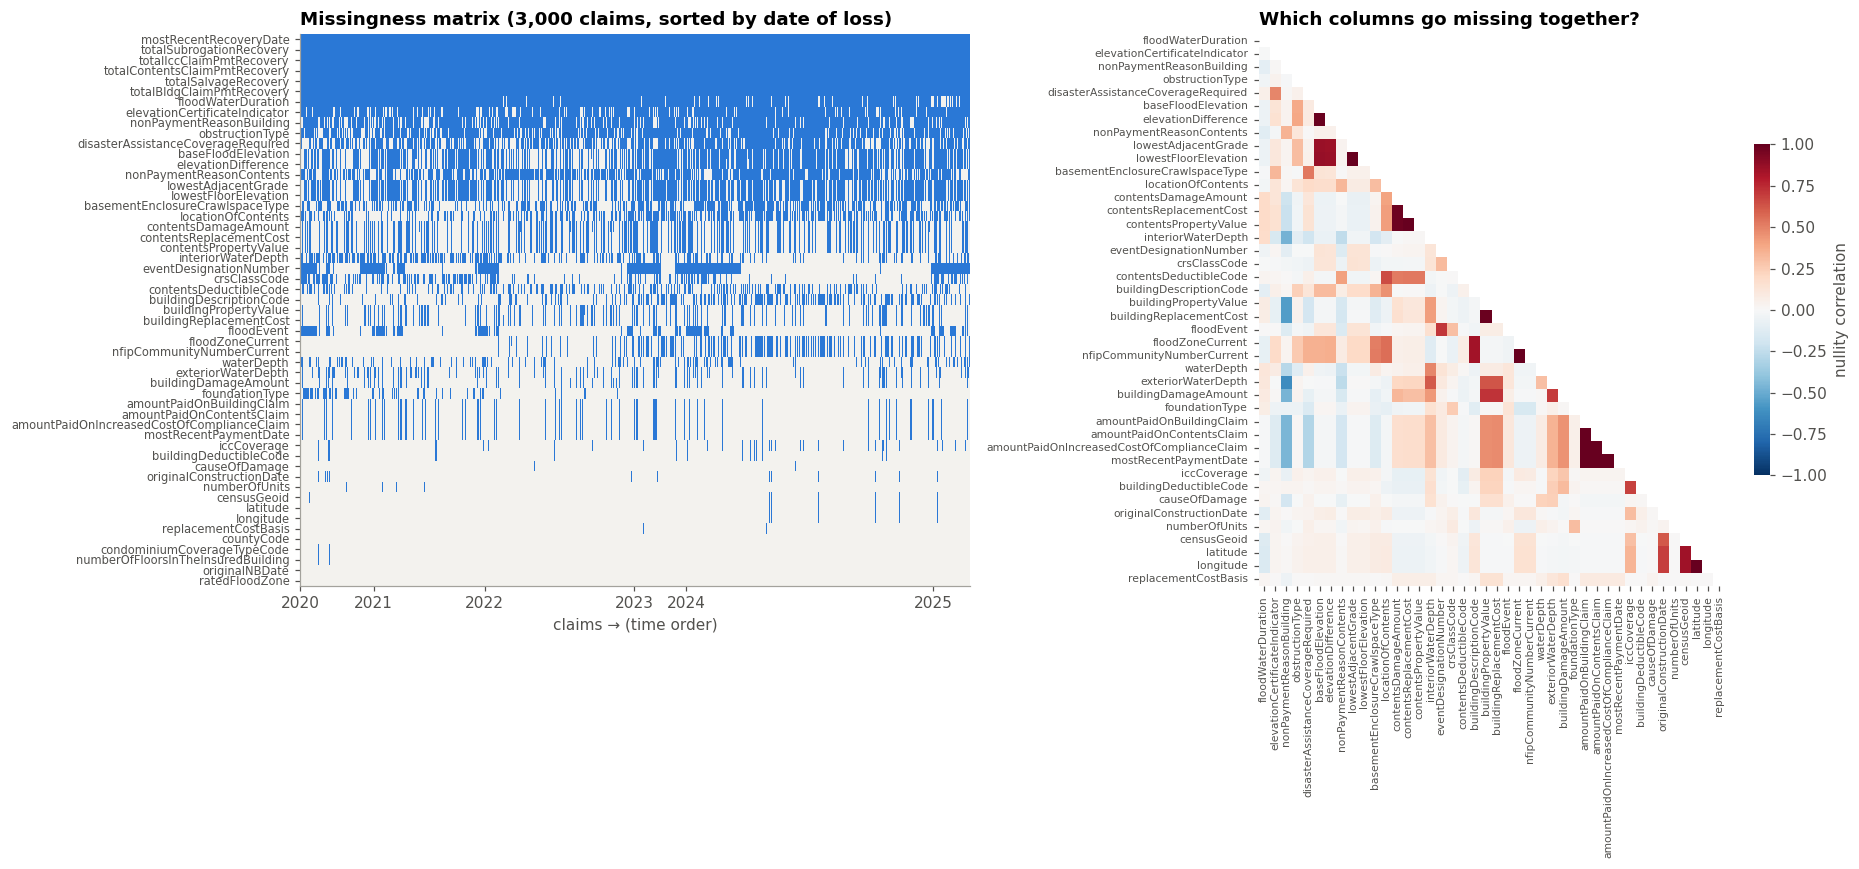

nullity corr
amountPaidOnContentsClaim                  amountPaidOnBuildingClaim                       1.000000
amountPaidOnIncreasedCostOfComplianceClaim amountPaidOnBuildingClaim                       1.000000
                                           amountPaidOnContentsClaim                       1.000000
longitude                                  latitude                                        1.000000
contentsPropertyValue                      contentsReplacementCost                         0.999985
mostRecentPaymentDate                      amountPaidOnBuildingClaim                       0.999950
                                           amountPaidOnContentsClaim                       0.999950
                                           amountPaidOnIncreasedCostOfComplianceClaim      0.999950
nfipCommunityNumberCurrent                 floodZoneCurrent                                0.998892
lowestFloorElevation                       lowestAdjacentGrade                             0.993088
buildingReplacementCost                    buildingPropertyValue                           0.989912
elevationDifference                        baseFloodElevation                              0.987230
contentsReplacementCost                    contentsDamageAmount                            0.977844
contentsPropertyValue                      contentsDamageAmount                            0.977844

In [8]:
mcols = miss.index[(miss["true_%"] > 0) & (miss["true_%"] < 100)].tolist()
samp = df.sample(3000, random_state=SEED).sort_values("dateOfLoss")
fig, ax = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1.15, 1]})
ax[0].imshow(samp[mcols].isna().T.values, aspect="auto", interpolation="nearest",
             cmap=ListedColormap(["#f3f2ee", C[0]]))
ax[0].set_yticks(range(len(mcols))); ax[0].set_yticklabels(mcols, fontsize=7.5)
years = samp["dateOfLoss"].dt.year.values
ticks = [np.argmax(years == y) for y in sorted(set(years))]
ax[0].set_xticks(ticks); ax[0].set_xticklabels(sorted(set(years))); ax[0].grid(False)
ax[0].set(title="Missingness matrix (3,000 claims, sorted by date of loss)", xlabel="claims → (time order)")

nc = [c for c in mcols if 0.5 < miss.loc[c, "true_%"] < 99.5]
ncorr = df[nc].isna().astype(int).corr()
mask = np.triu(np.ones_like(ncorr, dtype=bool))
sns.heatmap(ncorr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax[1], cbar_kws={"shrink": 0.6, "label": "nullity correlation"},
            xticklabels=True, yticklabels=True)
ax[1].tick_params(labelsize=7); ax[1].set_title("Which columns go missing together?"); ax[1].grid(False)
plt.tight_layout(); savefig("04_missing_matrix_nullity_corr"); plt.show()

# list the near-perfect co-missing blocks
pairs = ncorr.where(~mask).stack().loc[lambda s: s > 0.9].sort_values(ascending=False)
pairs.rename("nullity corr").to_frame().head(25)

The heatmap shows **co-missing blocks**. A block is one reporting event, not many independent gaps:

* **Adjuster valuation block** (`buildingDamageAmount`, `buildingPropertyValue`, `buildingReplacementCost`): blank together, because no adjuster valuation was recorded.
* **Contents block** (`contentsDamageAmount`, `contentsPropertyValue`, `contentsReplacementCost`, `contentsDeductibleCode`): mostly policies with **no contents coverage** (proved in 4.4).
* **Payment block** (`amountPaidOn*`, `mostRecentPaymentDate`): claims **closed without payment**.
* **Elevation Certificate block** (`elevationDifference`, `baseFloodElevation`, `lowestFloorElevation`, `lowestAdjacentGrade`): no Elevation Certificate data was reported.
* **Recovery block** (`total*Recovery`, `mostRecentRecoveryDate`): no money was ever recovered.
* `floodZoneCurrent` ↔ `nfipCommunityNumberCurrent`: no current-map lookup for the community.

### 4.3 Missingness changes over time and with the rating system → not MCAR
If values were Missing Completely At Random, the missing rate would be flat across years and across policy types. The two charts below show it is neither. The second chart splits claims by rating system: FEMA phased in **Risk Rating 2.0** (`rateMethod = "RE"`) from October 2021, and the two systems record different fields.

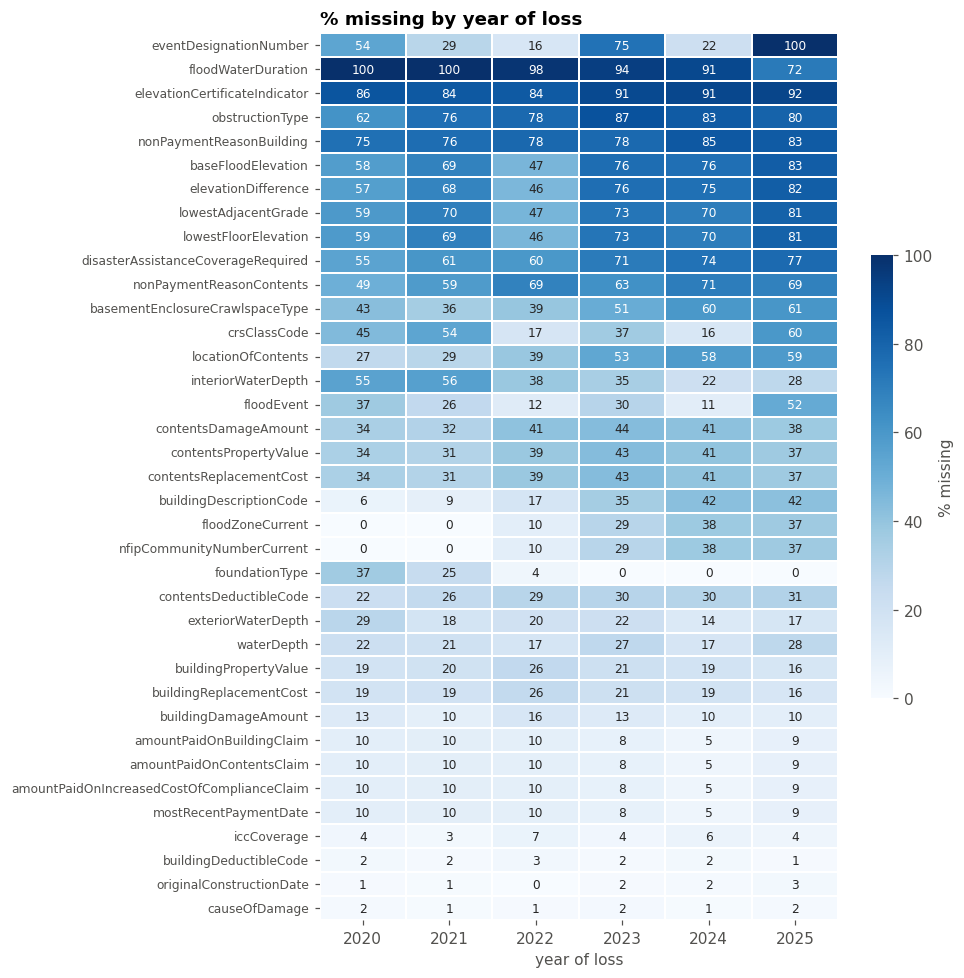

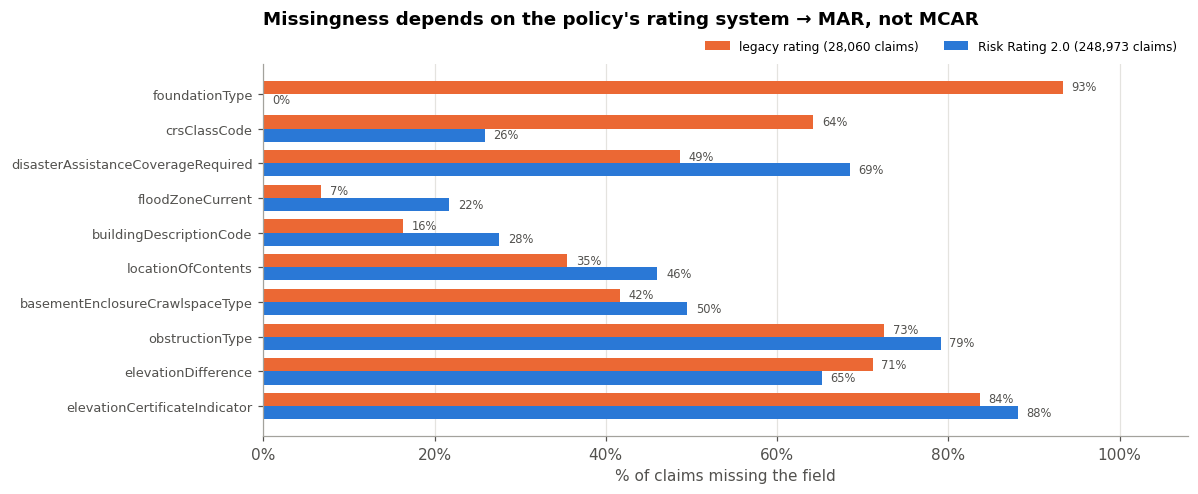

In [9]:
show = [c for c in mcols if 1 < miss.loc[c, "true_%"] < 99]
by_year = df.groupby("yearOfLoss")[show].apply(lambda g: g.isna().mean() * 100).T
by_year = by_year.loc[by_year.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(by_year, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% missing", "shrink": 0.5},
            linewidths=1, linecolor="white", annot_kws={"size": 8}, ax=ax)
ax.set(title="% missing by year of loss", xlabel="year of loss", ylabel=""); ax.tick_params(axis="y", labelsize=8); ax.grid(False)
plt.tight_layout(); savefig("04_missing_by_year"); plt.show()

rr2_cols = ["foundationType", "crsClassCode", "disasterAssistanceCoverageRequired", "floodZoneCurrent", "buildingDescriptionCode",
            "locationOfContents", "basementEnclosureCrawlspaceType", "elevationDifference", "obstructionType", "elevationCertificateIndicator"]
is_re = df["rateMethod"].eq("RE").map({True: "Risk Rating 2.0 (RE)", False: "legacy rating"})
mr = df[rr2_cols].isna().groupby(is_re).mean().T
mr = mr.loc[(mr["legacy rating"] - mr["Risk Rating 2.0 (RE)"]).abs().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(mr)); h = 0.38
ax.barh(y - h/2, mr["legacy rating"], h, color=C[1], label=f"legacy rating ({(is_re == 'legacy rating').sum():,} claims)")
ax.barh(y + h/2, mr["Risk Rating 2.0 (RE)"], h, color=C[0], label=f"Risk Rating 2.0 ({(is_re != 'legacy rating').sum():,} claims)")
for yi, (a, b) in zip(y, zip(mr["legacy rating"], mr["Risk Rating 2.0 (RE)"])):
    ax.text(a + 0.01, yi - h/2, f"{a:.0%}", va="center", fontsize=7.5, color=INK2); ax.text(b + 0.01, yi + h/2, f"{b:.0%}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(mr.index, fontsize=8.5); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1.08)
ax.set(title="Missingness depends on the policy's rating system → MAR, not MCAR", xlabel="% of claims missing the field")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2, fontsize=8); ax.set_title("Missingness depends on the policy's rating system → MAR, not MCAR", loc="left", pad=26)
plt.tight_layout(); savefig("04_missing_by_rating_method"); plt.show()

**Reading the two charts.**
* `foundationType` is missing (code 0) on **93% of legacy-rated claims and 0% of RR2 claims**. That is MAR in its clearest form: the legacy forms did not collect it. It also explains why its missing rate falls to 0 after 2022 in the year heatmap.
* `crsClassCode` is missing far more often on legacy policies (64% vs 26%), and it swings year to year with *which communities* a storm hit. `floodZoneCurrent` and `buildingDescriptionCode` go the other way, missing more often under RR2.
* The **Elevation Certificate block** is missing on most claims under *both* systems (65–88%). It is not driven by the rating change, but by whether an Elevation Certificate was ever filed for the building. That depends on observed policy attributes (coverage, zone), so it is labeled MAR.
* `eventDesignationNumber` / `floodEvent` follow the storm calendar (100% missing in 2025, when no event had been designated yet), which is structural.

### 4.4 Structural missingness: the blank is the *correct* value
Before calling anything MCAR, MAR or MNAR, remove the blanks that are **not applicable by design** (Little & Rubin's categories apply only to values that *exist but were not recorded*). Each rule below is tested with a cross-tab. The "% explained" column is the share of that column's blanks the rule accounts for.

In [10]:
net_b, net_c = df["netBuildingPaymentAmount"], df["netContentsPaymentAmount"]
no_cont = df["totalContentsInsuranceCoverage"] == 0
checks = [
    ("amountPaidOnBuildingClaim", net_b.eq(0), "claim closed without payment (net building payment = 0)"),
    ("amountPaidOnContentsClaim", net_c.eq(0) | no_cont, "no contents payment / no contents coverage"),
    ("mostRecentPaymentDate", net_b.eq(0) & net_c.eq(0), "no payment at all → no payment date"),
    ("contentsDamageAmount", no_cont, "policy has no contents coverage"),
    ("buildingDeductibleCode", df["totalBuildingInsuranceCoverage"].eq(0), "contents-only policy: no building coverage → no building deductible"),
    ("iccCoverage", df["totalBuildingInsuranceCoverage"].eq(0), "contents-only policy: ICC is a building coverage"),
    ("contentsDeductibleCode", no_cont, "policy has no contents coverage"),
    ("locationOfContents", no_cont, "policy has no contents coverage"),
    ("obstructionType", ~df["elevatedBuildingIndicator"], "building is not elevated (field only defined for elevated)"),
    ("nonPaymentReasonBuilding", net_b.gt(0), "building WAS paid → no non-payment reason"),
    ("nonPaymentReasonContents", net_c.gt(0) | no_cont, "contents paid or not covered"),
    ("floodEvent", df["eventDesignationNumber"].isna(), "no catastrophe event designated"),
    ("floodZoneCurrent", df["nfipCommunityNumberCurrent"].isna(), "no current community/map lookup"),
    ("totalBldgClaimPmtRecovery", df["mostRecentRecoveryDate"].isna(), "no recovery ever happened"),
]
rows = []
for col, cond, why in checks:
    m = df[col].isna()
    rows.append({"column": col, "explanation": why, "missing": int(m.sum()),
                 "explained by rule": int((m & cond).sum()), "% explained": round(100 * (m & cond).sum() / max(m.sum(), 1), 1),
                 "rule true but value present (often an explicit 0)": int((~m & cond).sum())})
structural = pd.DataFrame(rows).sort_values("% explained", ascending=False)
structural

,column,explanation,missing,explained by rule,% explained,rule true but value present (often an explicit 0)
0,amountPaidOnBuildingClaim,claim closed without payment (net building payment = 0),21744,21744,100.0,42384
1,amountPaidOnContentsClaim,no contents payment / no contents coverage,21744,21744,100.0,166098
2,mostRecentPaymentDate,no payment at all → no payment date,21746,21746,100.0,35485
6,contentsDeductibleCode,policy has no contents coverage,78928,78920,100.0,2224
11,floodEvent,no catastrophe event designated,56474,56474,100.0,36387
13,totalBldgClaimPmtRecovery,no recovery ever happened,276630,276630,100.0,0
12,floodZoneCurrent,no current community/map lookup,55968,55869,99.8,0
8,obstructionType,building is not elevated (field only defined for elevated),217295,215959,99.4,3952
9,nonPaymentReasonBuilding,building WAS paid → no non-payment reason,222102,212253,95.6,614
4,buildingDeductibleCode,contents-only policy: no building coverage → no building deductible,6774,6456,95.3,62


**Reading the table**

* A **100% explained** row means the blank is fully structural. Example: every NaN in `amountPaidOnBuildingClaim` is a claim whose net payment is 0. That NaN *means $0*. Filling it with a mean would invent payments that never happened.
* A **partially explained** row (for example `contentsDamageAmount`, about 59%) splits into two parts. One part is structural ("no contents coverage" → the true value is 0). The remainder is genuine non-response (coverage existed, but no adjuster figure). These two parts need **different treatments**.
* `buildingDeductibleCode` is a hidden structural case. About 95% of its blanks are **contents-only policies**, which have no building deductible to report.
* The last column is a sanity check. For payment fields it is large only because many closed-without-payment claims carry an explicit `0` instead of a blank, which agrees with the rule.

### 4.5 Is the rest MCAR? Test whether missingness predicts an observed variable
If a column were **MCAR**, claims with and without a value would look alike on every other variable. Each partly-missing column is checked against a fully observed outcome (**was the building paid?**) and a fully observed policy fact (**building coverage**). With 277k rows, every p-value is tiny, so the **effect sizes** are what matter: the gap in paid-rate (percentage points) and Cramér's V.

column,% missing,paid rate | missing,paid rate | observed,gap (pp),Cramér V (missing × paid),chi² p,KS stat (coverage),KS p
amountPaidOnBuildingClaim,7.850000,0.0%,83.4%,-83.4,0.532,0.0e+00,0.022,1.3e-08
buildingDamageAmount,11.890000,9.9%,85.9%,-76.0,0.583,0.0e+00,0.157,0.0e+00
exteriorWaterDepth,18.610000,15.1%,91.0%,-75.9,0.700,0.0e+00,0.103,0.0e+00
buildingDeductibleCode,2.450000,4.0%,78.7%,-74.6,0.273,0.0e+00,0.953,0.0e+00
buildingReplacementCost,20.540000,22.8%,90.8%,-68.0,0.651,0.0e+00,0.089,4.0e-315
buildingPropertyValue,20.700000,23.4%,90.8%,-67.4,0.647,0.0e+00,0.089,1.7e-310
causeOfDamage,1.290000,12.0%,77.7%,-65.6,0.176,0.0e+00,0.023,5.1e-02
replacementCostBasis,0.590000,20.8%,77.2%,-56.4,0.102,0.0e+00,0.051,4.0e-04
iccCoverage,5.080000,23.4%,79.7%,-56.3,0.293,0.0e+00,0.723,0.0e+00
interiorWaterDepth,36.420000,48.1%,93.3%,-45.2,0.516,0.0e+00,0.087,0.0e+00


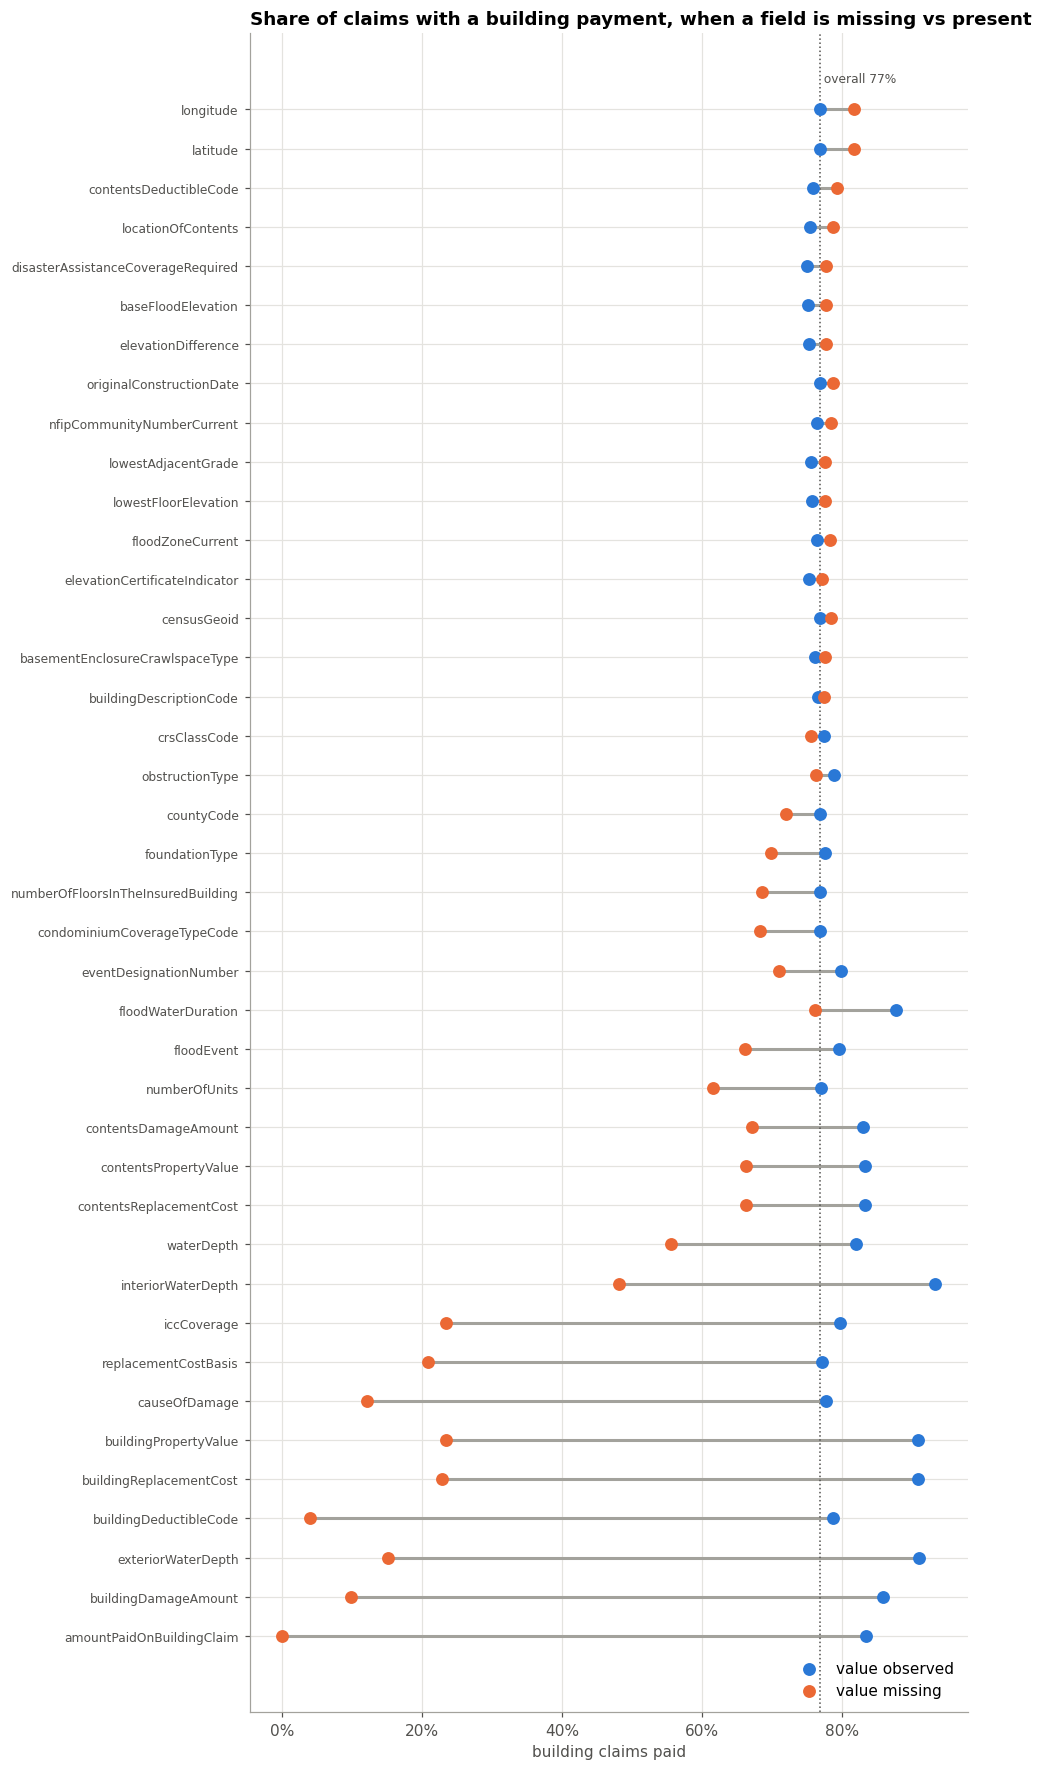

In [11]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), stats.chi2_contingency(ct, correction=False)[1]

is_paid = net_b.gt(0)
cov_log = np.log1p(df["totalBuildingInsuranceCoverage"])
test_cols = [c for c in miss.index if 0.1 <= miss.loc[c, "true_%"] <= 95 and A[c][1] != "outcome / leakage"]
res = []
for c in test_cols:
    m = df[c].isna()
    v, p = cramers_v(m, is_paid)
    ks = stats.ks_2samp(cov_log[m], cov_log[~m])
    res.append({"column": c, "% missing": miss.loc[c, "true_%"],
                "paid rate | missing": is_paid[m].mean(), "paid rate | observed": is_paid[~m].mean(),
                "gap (pp)": 100 * (is_paid[m].mean() - is_paid[~m].mean()),
                "Cramér V (missing × paid)": v, "chi² p": p, "KS stat (coverage)": ks.statistic, "KS p": ks.pvalue})
mcar = pd.DataFrame(res).sort_values("gap (pp)")
fmt = {"paid rate | missing": "{:.1%}", "paid rate | observed": "{:.1%}", "gap (pp)": "{:+.1f}",
       "Cramér V (missing × paid)": "{:.3f}", "chi² p": "{:.1e}", "KS stat (coverage)": "{:.3f}", "KS p": "{:.1e}"}
display(mcar.style.format(fmt).background_gradient(subset=["gap (pp)"], cmap="RdBu", vmin=-40, vmax=40).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 0.38 * len(mcar) + 1))
y = np.arange(len(mcar))
ax.hlines(y, mcar["paid rate | observed"], mcar["paid rate | missing"], color=GRAY, lw=2)
ax.scatter(mcar["paid rate | observed"], y, color=C[0], s=55, zorder=3, label="value observed")
ax.scatter(mcar["paid rate | missing"], y, color=C[1], s=55, zorder=3, label="value missing")
ax.axvline(is_paid.mean(), color=INK2, ls=":", lw=1); ax.text(is_paid.mean(), len(mcar) - 0.3, f" overall {is_paid.mean():.0%}", fontsize=8, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(mcar["column"], fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="Share of claims with a building payment, when a field is missing vs present", xlabel="building claims paid")
ax.legend(loc="lower right"); plt.tight_layout(); savefig("04_mcar_test_paid_rate"); plt.show()

**Reading the test.** Under MCAR, a column's two dots would sit on top of each other and the KS statistic would be near 0. The columns fall into three groups:

1. **Huge outcome gaps (tens of points).** Building damage, value and replacement cost, the water depths, cause of damage, ICC coverage, building deductible. When these are blank, the claim was usually **closed without payment or without a full inspection**. The blank tells you about the outcome, so MCAR is clearly rejected. These columns need a **missing-indicator flag**.
2. **Small outcome gap (≈ 2 points) but large KS on coverage.** The Elevation Certificate block, `crsClassCode`, basement type, building description. Missingness hardly relates to *payment*, but it does relate to *which policy form and rating system* wrote the policy (4.3). That is **MAR**: explained by observed policy attributes.
3. **Tiny gaps on both tests.** A handful of < 1% columns where MCAR is plausible. A simple mode or median fill is harmless there.

An observed table can reject MCAR. It **cannot** tell MAR from MNAR, because that would require the values we do not have. The labels in 4.6 are therefore arguments from the data-generating process (who records the field, and when), backed by the evidence above.

### 4.6 Missingness mechanism for every column with missing data

In [12]:
MECH = {
 # column: (mechanism, evidence)
 "ficoNumber": ("Discontinued field", "100% blank: FICO replaced by Event Designation Number in 2020"),
 "floodCharacteristicsIndicator": ("Discontinued field", "100% blank in 2020-2025"),
 "reportedCity": ("Redacted (privacy)", "every value is 'Currently Unavailable'"),
 "mostRecentRecoveryDate": ("Structural", "no recovery happened (identical block with total*Recovery)"),
 "totalSalvageRecovery": ("Structural", "no recovery happened"), "totalBldgClaimPmtRecovery": ("Structural", "no recovery happened"),
 "totalContentsClaimPmtRecovery": ("Structural", "no recovery happened"), "totalIccClaimPmtRecovery": ("Structural", "no recovery happened"),
 "totalSubrogationRecovery": ("Structural", "no recovery happened"),
 "floodWaterDuration": ("MNAR (likely)", "rarely measured; recorded mainly when water stayed long enough to matter"),
 "elevationCertificateIndicator": ("MAR", "FEMA: blank = 'not reported'; 84-88% blank under both rating systems"),
 "obstructionType": ("Structural + MAR", "99% of blanks are non-elevated buildings (not applicable)"),
 "nonPaymentReasonBuilding": ("Structural", "96% of blanks are paid claims (no reason needed)"),
 "disasterAssistanceCoverageRequired": ("MAR (rating system)", "69% blank on RR2 vs 49% legacy; 99% of observed values are 0"),
 "baseFloodElevation": ("MAR", "Elevation Certificate block (no EC filed); depends on coverage, KS ≈ 0.15; EC no longer required under RR2"),
 "elevationDifference": ("MAR", "Elevation Certificate block (no EC filed); depends on coverage, KS ≈ 0.15"),
 "lowestAdjacentGrade": ("MAR", "Elevation Certificate block (no EC filed); depends on coverage, KS ≈ 0.15"),
 "lowestFloorElevation": ("MAR", "Elevation Certificate block (no EC filed); depends on coverage, KS ≈ 0.15"),
 "nonPaymentReasonContents": ("Structural", "contents paid or not covered"),
 "basementEnclosureCrawlspaceType": ("MAR", "differs by rating method, foundation and year"),
 "locationOfContents": ("Structural + MAR", "about 63% of blanks are policies without contents coverage"),
 "contentsDamageAmount": ("Structural + MNAR", "about 59% no contents coverage; rest = adjuster did not record (paid rate differs)"),
 "contentsPropertyValue": ("Structural + MNAR", "same block as contentsDamageAmount"),
 "contentsReplacementCost": ("Structural + MNAR", "same block as contentsDamageAmount"),
 "interiorWaterDepth": ("MNAR (likely)", "not measured when no water entered or no inspection"),
 "eventDesignationNumber": ("Structural", "no catastrophe event designated"),
 "crsClassCode": ("MAR (rating system)", "64% missing on legacy-rated vs 26% on RR2 claims; recoverable from community (Section 7)"),
 "contentsDeductibleCode": ("Structural", "no contents coverage → no contents deductible"),
 "buildingDescriptionCode": ("MAR", "varies by rating method"),
 "floodEvent": ("Structural", "no named event, the claim is a local flood"),
 "floodZoneCurrent": ("Structural / MAR", "no current-map lookup (co-missing with nfipCommunityNumberCurrent)"),
 "nfipCommunityNumberCurrent": ("Structural / MAR", "no current-map lookup"),
 "waterDepth": ("MNAR (likely)", "includes 99 sentinel; missing depth ↔ lower paid rate"),
 "exteriorWaterDepth": ("MNAR (likely)", "missing when no site measurement"),
 "buildingDamageAmount": ("MNAR (likely)", "adjuster valuation block + $1 placeholders; paid rate 3% when blank; never impute (RQ2 target)"),
 "buildingPropertyValue": ("MNAR (likely)", "adjuster valuation block + recoded zeros"),
 "buildingReplacementCost": ("MNAR (likely)", "adjuster valuation block + recoded zeros"),
 "amountPaidOnBuildingClaim": ("Structural", "100% of blanks = closed without payment → 0"),
 "amountPaidOnContentsClaim": ("Structural", "closed without payment → 0"),
 "amountPaidOnIncreasedCostOfComplianceClaim": ("Structural", "closed without payment → 0"),
 "mostRecentPaymentDate": ("Structural", "no payment → no date"),
 "iccCoverage": ("Structural + MAR", "46% contents-only policies; rest by policy form; constant 30,000 when present"),
 "buildingDeductibleCode": ("Structural", "95% of blanks are contents-only policies (no building deductible)"),
 "numberOfUnits": ("MCAR-plausible", "1%, small gap"),
 "censusGeoid": ("MCAR-plausible", "<1%, geocoding failure"),
 "originalConstructionDate": ("MAR", "1.2% incl. 1900-01-01 placeholders; differs by coverage (KS 0.6)"),
 "latitude": ("MCAR-plausible", "<1%, geocoding failure"), "longitude": ("MCAR-plausible", "<1%, geocoding failure"),
 "replacementCostBasis": ("MAR", "0.6%; paid rate much lower when blank"),
 "countyCode": ("MCAR-plausible", "<0.2%"), "condominiumCoverageTypeCode": ("MCAR-plausible", "0.1%"),
 "numberOfFloorsInTheInsuredBuilding": ("MCAR-plausible", "0.1%"), "causeOfDamage": ("MAR", "1.3%, closed-without-inspection claims"),
 "foundationType": ("MAR (rating system)", "code 0 on 93% of legacy-rated claims, 0% of RR2 claims"),
 "ratedFloodZone": ("MCAR-plausible", "0.02%"), "originalNBDate": ("MCAR-plausible", "0.02%"),
}
mech = miss[miss["true_n"] > 0][["true_n", "true_%", "role"]].copy()
mech["mechanism"] = [MECH.get(c, ("MCAR-plausible", "tiny share"))[0] for c in mech.index]
mech["evidence"] = [MECH.get(c, ("", "tiny share"))[1] for c in mech.index]
mech

,true_n,true_%,role,mechanism,evidence
ficoNumber,277033,100.00,event / time,Discontinued field,100% blank: FICO replaced by Event Designation Number in 2020
floodCharacteristicsIndicator,277033,100.00,post-loss (adjuster),Discontinued field,100% blank in 2020-2025
reportedCity,277033,100.00,geography,Redacted (privacy),every value is 'Currently Unavailable'
mostRecentRecoveryDate,276630,99.85,outcome / leakage,Structural,no recovery happened (identical block with total*Recovery)
totalSubrogationRecovery,276630,99.85,outcome / leakage,Structural,no recovery happened
totalIccClaimPmtRecovery,276630,99.85,outcome / leakage,Structural,no recovery happened
totalContentsClaimPmtRecovery,276630,99.85,outcome / leakage,Structural,no recovery happened
totalSalvageRecovery,276630,99.85,outcome / leakage,Structural,no recovery happened
totalBldgClaimPmtRecovery,276630,99.85,outcome / leakage,Structural,no recovery happened
floodWaterDuration,261438,94.37,post-loss (adjuster),MNAR (likely),rarely measured; recorded mainly when water stayed long enough to matter


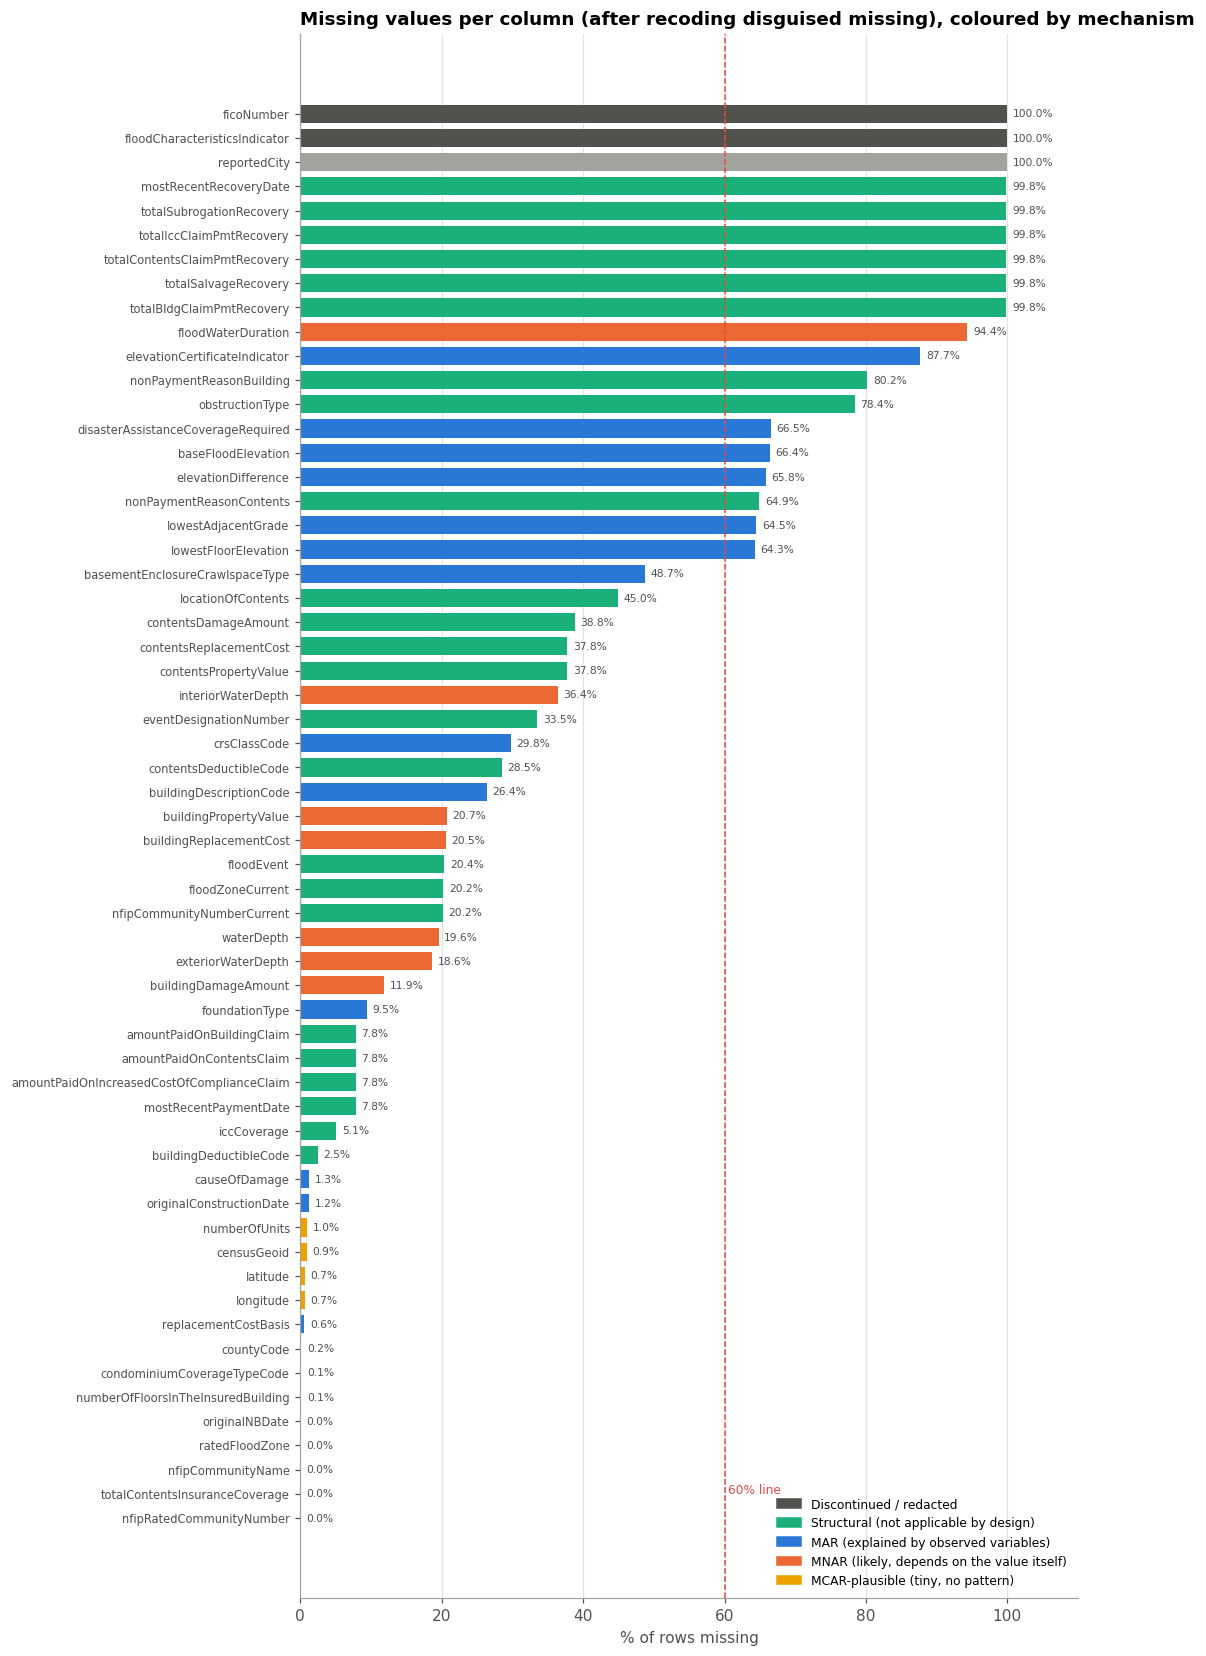

In [13]:
MECH_COLOR = {"Discontinued field": "#52514e", "Redacted (privacy)": "#a3a29c", "Structural": C[2],
              "Structural + MAR": C[2], "Structural + MNAR": C[2], "Structural / MAR": C[2],
              "MAR": C[0], "MAR (rating system)": C[0], "MNAR (likely)": C[1], "MCAR-plausible": C[3]}
legend_groups = {"Discontinued / redacted": "#52514e", "Structural (not applicable by design)": C[2],
                 "MAR (explained by observed variables)": C[0], "MNAR (likely, depends on the value itself)": C[1],
                 "MCAR-plausible (tiny, no pattern)": C[3]}
p = mech.sort_values("true_%")
fig, ax = plt.subplots(figsize=(10, 0.24 * len(p) + 1))
ax.barh(p.index, p["true_%"], color=[MECH_COLOR[m] for m in p["mechanism"]], height=0.75)
for i, (v, n) in enumerate(zip(p["true_%"], p["true_n"])):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=7, color=INK2)
ax.axvline(60, color=C[7], ls="--", lw=1); ax.text(60.5, 1, "60% line", color=C[7], fontsize=8)
ax.set_xlim(0, 110); ax.tick_params(axis="y", labelsize=7.5)
ax.set(title="Missing values per column (after recoding disguised missing), coloured by mechanism", xlabel="% of rows missing"); ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in legend_groups.items()], loc="lower right", fontsize=8)
plt.tight_layout(); savefig("04_missing_by_mechanism"); plt.show()

## 5. Duplicates

Three checks, from strictest to loosest:

1. **Duplicate `id`.** The primary key must be unique.
2. **Exact duplicate rows.** Every column is equal.
3. **Duplicates on every column *except* `id`.** These are identical records that only received different surrogate keys.

In [14]:
dup_id = raw["id"].duplicated().sum()
dup_full = raw.duplicated().sum()
cols_no_id = [c for c in raw.columns if c != "id"]
dmask_all = raw.duplicated(subset=cols_no_id, keep=False)
dmask_extra = raw.duplicated(subset=cols_no_id, keep="first")
grp_sizes = raw[dmask_all].groupby(cols_no_id, dropna=False).size()

dup_summary = pd.Series({
    "duplicate id values": dup_id,
    "exact duplicate rows (all 84 columns)": dup_full,
    "rows involved in duplicate groups (all columns except id)": int(dmask_all.sum()),
    "duplicate groups": len(grp_sizes),
    "extra copies (rows that would be removed)": int(dmask_extra.sum()),
    "extra copies as % of rows": pct(dmask_extra.mean(), 2),
}).to_frame("count"); display(dup_summary)

d = raw[dmask_all]
compare = pd.DataFrame({
    "duplicates": [d["netBuildingPaymentAmount"].eq(0).mean(), (d["state"] == "FL").mean(), d["floodEvent"].notna().mean(),
                   d["policyCount"].gt(1).mean(), (d["occupancyType"].isin([15, 16, 13])).mean()],
    "all claims": [raw["netBuildingPaymentAmount"].eq(0).mean(), (raw["state"] == "FL").mean(), raw["floodEvent"].notna().mean(),
                   raw["policyCount"].gt(1).mean(), (raw["occupancyType"].isin([15, 16, 13])).mean()]},
    index=["building payment = $0", "state = FL", "named flood event", "policyCount > 1 (condo / multi-unit)", "condo / multi-unit occupancy"])
display(compare.style.format("{:.1%}"))
print("group size distribution:"); print(grp_sizes.value_counts().sort_index().to_string())

,count
duplicate id values,0
exact duplicate rows (all 84 columns),0
rows involved in duplicate groups (all columns except id),694
duplicate groups,241
extra copies (rows that would be removed),453
extra copies as % of rows,0.16%


,duplicates,all claims
building payment = $0,91.1%,23.1%
state = FL,77.8%,55.1%
named flood event,93.2%,79.6%
policyCount > 1 (condo / multi-unit),27.8%,4.6%
condo / multi-unit occupancy,67.9%,10.2%


group size distribution:
2     158
3      45
4      13
5      11
6       2
7       4
8       1
9       2
11      1
12      1
14      1
16      1
17      1


In [15]:
# Look at one duplicate group side by side: which fields are identical?
g0 = raw[dmask_all].sort_values(cols_no_id[:5]).groupby(cols_no_id, dropna=False).head(10)
first_key = tuple(g0.iloc[0][cols_no_id])
example = raw[(raw[cols_no_id].fillna(-999) == pd.Series(first_key, index=cols_no_id).fillna(-999)).all(axis=1)]
example[["id", "dateOfLoss", "state", "countyCode", "censusGeoid", "originalConstructionDate", "originalNBDate",
         "totalBuildingInsuranceCoverage", "policyCount", "occupancyType", "netBuildingPaymentAmount", "floodEvent"]].T

,5684,63243,79707,100691,102268,104023,108690,132957,134071,138576,180582,186051,193867,215296,249963,255586
id,5504556,6070454,6233305,6440643,6455616,6473471,6519326,6758284,6769019,6812050,7228488,7283298,7359945,7495480,7910404,7964666
dateOfLoss,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00,2021-08-29 00:00:00
state,LA,LA,LA,LA,LA,LA,LA,LA,LA,LA,LA,LA,LA,LA,LA,LA
countyCode,22051,22051,22051,22051,22051,22051,22051,22051,22051,22051,22051,22051,22051,22051,22051,22051
censusGeoid,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012,220510275012
originalConstructionDate,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00,1989-01-01 00:00:00
originalNBDate,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00,2012-01-30 00:00:00
totalBuildingInsuranceCoverage,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0,250000.0
policyCount,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
occupancyType,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0


**Decision: drop the extra copies (keep the first) and keep a log of how many were removed.**

* The copies match on **all 83 non-key fields**. That includes the census block group, the original construction date, the policy's original new-business date, the coverage amounts, the deductibles and every adjuster figure. Two *different* buildings matching on all of these is not credible, even after FEMA's location rounding.
* They are mostly **$0 claims, often multi-unit or condo policies**. That fits a claim keyed twice (for example, reopened or re-entered), not distinct losses.
* They are 0.16% of rows, so the decision cannot move any distribution. Keeping them would put identical rows in both the train and test folds, which is a small form of **leakage**.
* What we give up: if some copies were real separate claims (for example, two units in one building), claim counts are understated by at most 453.

Near-duplicates (same building and date, different payment) are **kept**. They can be legitimate separate claims, such as building and contents on separate records, or units in one condo association.

In [16]:
n_before = len(df)
df = df.loc[~dmask_extra.values].reset_index(drop=True)
raw_dedup_ids = set(df["id"])
print(f"rows: {n_before:,} → {len(df):,}  (removed {n_before - len(df):,} exact copies; ids remain unique: {df['id'].is_unique})")

rows: 277,033 → 276,580  (removed 453 exact copies; ids remain unique: True)


## 6. Which features can be dropped, and why

Each drop has to be defensible. Seven screening rules are applied in order, and each column is dropped for its **first** failing rule.

| Rule | Why it disqualifies a column |
|---|---|
| R1 Empty or redacted (100% missing) | Carries no information |
| R2 Constant or near-constant (top value ≥ 99.5%) | Zero or negligible variance; models can't learn from it, and one-hot columns would be almost all zeros |
| R3 > 90% missing and not structural | Imputing would invent > 90% of the column |
| R4 Identifier or very high cardinality with no meaning as a feature | Memorises rows instead of generalising |
| R5 Redundant | Duplicates the information of a kept column (exact or near-exact) |
| R6 Leakage (outcome after the claim) | Would not exist when the model is used, so it inflates accuracy |
| R7 High-missing + location proxy | Too sparse, and the absolute elevation (datum-dependent) mainly encodes *where*, which geography already covers |

**Leakage columns are not deleted from disk.** They stay in the EDA frame for charts and targets, and are excluded from the feature list.

In [17]:
n_rows = len(df)
top_share = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
screen = pd.DataFrame({"% missing": (df.isna().mean() * 100).round(2), "n_unique": df.nunique(),
                       "top value share": (top_share * 100).round(2), "role": attr["role"]})
near_const = screen[(screen["top value share"] >= 99.5) & (screen["% missing"] < 99.5)].sort_values("top value share", ascending=False)
print("Near-constant columns (top value ≥ 99.5% of rows):")
display(near_const)

# redundancy evidence
pf = pd.crosstab(df["preFirmIndicator"], df["postFIRMConstructionIndicator"])
print("preFirmIndicator × postFIRMConstructionIndicator (not complements → ambiguous):"); display(pf)
agree = (df["ratedFloodZone"] == df["floodZoneCurrent"])[df["floodZoneCurrent"].notna()].mean()
yr_same = (df["dateOfLoss"].dt.year == df["yearOfLoss"]).mean()
ev = df[["floodEvent", "eventDesignationNumber"]].dropna()
ev_map = ev.groupby("eventDesignationNumber")["floodEvent"].nunique().le(1).mean()
rho_net = df[["amountPaidOnBuildingClaim", "netBuildingPaymentAmount"]].corr(method="spearman").iloc[0, 1]
rho_val = df[["buildingPropertyValue", "buildingReplacementCost"]].corr(method="spearman").iloc[0, 1]
comm = df.groupby("nfipRatedCommunityNumber")["nfipCommunityName"].nunique().le(1).mean()
pd.Series({
    "year(dateOfLoss) == yearOfLoss": pct(yr_same, 2),
    "ratedFloodZone == floodZoneCurrent (where both present)": pct(agree),
    "each event number maps to one floodEvent name": pct(ev_map),
    "Spearman(amountPaidOnBuildingClaim, netBuildingPaymentAmount)": round(rho_net, 4),
    "Spearman(buildingPropertyValue, buildingReplacementCost)": round(rho_val, 4),
    "each community number has a single community name": pct(comm),
}).to_frame("evidence")

Near-constant columns (top value ≥ 99.5% of rows):


,% missing,n_unique,top value share,role
asOfDate,0.0,1,100.00,identifier / metadata
floodproofedIndicator,0.0,2,100.00,pre-loss feature
agricultureStructureIndicator,0.0,2,99.97,pre-loss feature
stateOwnedIndicator,0.0,2,99.97,pre-loss feature
houseWorship,0.0,2,99.89,pre-loss feature
netIccPaymentAmount,0.0,450,99.62,outcome / leakage


preFirmIndicator × postFIRMConstructionIndicator (not complements → ambiguous):


postFIRMConstructionIndicator,False,True
preFirmIndicator,,
False,118228,91136
True,66996,220


,evidence
year(dateOfLoss) == yearOfLoss,100.00%
ratedFloodZone == floodZoneCurrent (where both present),93.0%
each event number maps to one floodEvent name,100.0%
"Spearman(amountPaidOnBuildingClaim, netBuildingPaymentAmount)",0.9997
"Spearman(buildingPropertyValue, buildingReplacementCost)",0.9482
each community number has a single community name,100.0%


41 columns dropped from the feature set, 43 kept.


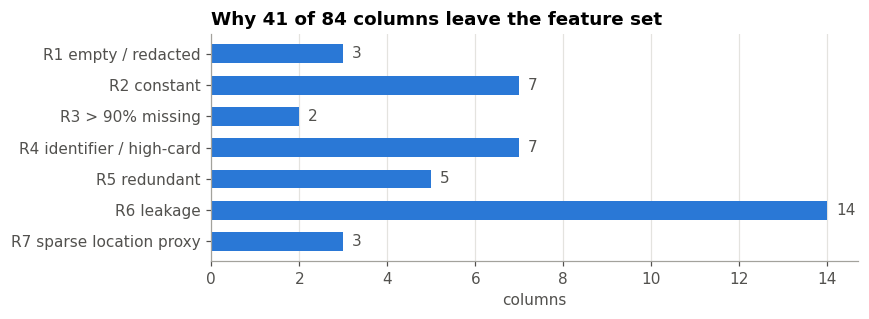

,column,rule,reason,% missing,top value share %
0,ficoNumber,R1 empty,100% missing (replaced by eventDesignationNumber in 2020),100.00,100.00
1,floodCharacteristicsIndicator,R1 empty,100% missing,100.00,100.00
2,reportedCity,R1 empty,redacted: every value 'Currently Unavailable',100.00,100.00
3,asOfDate,R2 constant,single snapshot timestamp,0.00,100.00
4,iccCoverage,R2 constant,"30,000 on every non-missing row",5.08,94.92
5,floodproofedIndicator,R2 near-constant,≥ 99.5% False,0.00,100.00
6,agricultureStructureIndicator,R2 near-constant,≥ 99.5% False,0.00,99.97
7,stateOwnedIndicator,R2 near-constant,≥ 99.5% False,0.00,99.97
8,houseWorship,R2 near-constant,≥ 99.5% False,0.00,99.89
9,disasterAssistanceCoverageRequired,R2 near-constant,66.5% missing and 99% of the rest are 0,66.52,66.52


In [18]:
DROP = {
 # R1 empty / redacted
 "ficoNumber": ("R1 empty", "100% missing (replaced by eventDesignationNumber in 2020)"),
 "floodCharacteristicsIndicator": ("R1 empty", "100% missing"),
 "reportedCity": ("R1 empty", "redacted: every value 'Currently Unavailable'"),
 # R2 constant / near-constant
 "asOfDate": ("R2 constant", "single snapshot timestamp"),
 "iccCoverage": ("R2 constant", "30,000 on every non-missing row"),
 "floodproofedIndicator": ("R2 near-constant", "≥ 99.5% False"),
 "agricultureStructureIndicator": ("R2 near-constant", "≥ 99.5% False"),
 "stateOwnedIndicator": ("R2 near-constant", "≥ 99.5% False"),
 "houseWorship": ("R2 near-constant", "≥ 99.5% False"),
 "disasterAssistanceCoverageRequired": ("R2 near-constant", "66.5% missing and 99% of the rest are 0"),
 # R3 sparse
 "floodWaterDuration": ("R3 sparse", "94% missing, not structural"),
 "elevationCertificateIndicator": ("R3 sparse", "88% missing; kept only as a 'code reported' flag"),
 # R4 identifiers / high cardinality
 "id": ("R4 identifier", "row key (kept aside for traceability)"),
 "nfipCommunityName": ("R4 high-cardinality text", "6.8k free-text names; same information as community number"),
 "nfipRatedCommunityNumber": ("R4 high-cardinality", "7.9k levels; used only to look up CRS class (Section 7)"),
 "nfipCommunityNumberCurrent": ("R4 high-cardinality", "7.3k levels, 20% missing"),
 "reportedZipCode": ("R4 high-cardinality", "11.9k levels; quasi-identifier"),
 "censusGeoid": ("R4 high-cardinality", "39.6k block groups; join key for Census data, not a feature"),
 "countyCode": ("R4 high-cardinality", "2.2k levels; used for lat/lon imputation; frequency-encode if needed"),
 # R5 redundant
 "yearOfLoss": ("R5 redundant", "100% equal to year(dateOfLoss); kept only as a grouping key"),
 "eventDesignationNumber": ("R5 redundant", "code for floodEvent; replaced by is_named_event flag"),
 "floodZoneCurrent": ("R5 redundant", "agrees with ratedFloodZone on most rows; 20% missing; the rated zone is what priced the policy"),
 "preFirmIndicator": ("R5 redundant/ambiguous", "not the complement of postFIRMConstructionIndicator; building age carries it"),
 "contentsReplacementCost": ("R5 redundant", "near-duplicate of contentsPropertyValue; 38% missing"),
 # R6 leakage (kept in EDA frame, excluded from features)
 "netBuildingPaymentAmount": ("R6 leakage", "= RQ1 target minus recoveries"),
 "netContentsPaymentAmount": ("R6 leakage", "post-outcome payment"),
 "netIccPaymentAmount": ("R6 leakage", "post-outcome payment"),
 "amountPaidOnContentsClaim": ("R6 leakage", "post-outcome payment"),
 "amountPaidOnIncreasedCostOfComplianceClaim": ("R6 leakage", "post-outcome payment"),
 "mostRecentPaymentDate": ("R6 leakage", "exists only if paid"),
 "nonPaymentReasonBuilding": ("R6 leakage", "exists only if NOT paid"),
 "nonPaymentReasonContents": ("R6 leakage", "exists only if NOT paid"),
 "mostRecentRecoveryDate": ("R6 leakage", "99.9% missing, post-outcome"),
 "totalSalvageRecovery": ("R6 leakage", "99.9% missing, post-outcome"),
 "totalBldgClaimPmtRecovery": ("R6 leakage", "99.9% missing, post-outcome"),
 "totalContentsClaimPmtRecovery": ("R6 leakage", "99.9% missing, post-outcome"),
 "totalIccClaimPmtRecovery": ("R6 leakage", "99.9% missing, post-outcome"),
 "totalSubrogationRecovery": ("R6 leakage", "99.9% missing, post-outcome"),
 # R7 high-missing elevation (absolute) → location proxies
 "baseFloodElevation": ("R7 sparse + location proxy", "66% missing; feet above datum mainly encodes place"),
 "lowestFloorElevation": ("R7 sparse + location proxy", "64% missing; same"),
 "lowestAdjacentGrade": ("R7 sparse + location proxy", "64% missing; same"),
}
drop_tbl = pd.DataFrame([{"column": c, "rule": r, "reason": why, "% missing": screen.loc[c, "% missing"],
                          "top value share %": screen.loc[c, "top value share"]} for c, (r, why) in DROP.items()])
print(f"{len(DROP)} columns dropped from the feature set, {df.shape[1] - len(DROP)} kept.")

fig, ax = plt.subplots(figsize=(8, 3))
rc = drop_tbl["rule"].str.extract(r"^(R\d)")[0].value_counts().sort_index()
labels = {"R1": "R1 empty / redacted", "R2": "R2 constant", "R3": "R3 > 90% missing", "R4": "R4 identifier / high-card",
          "R5": "R5 redundant", "R6": "R6 leakage", "R7": "R7 sparse location proxy"}
ax.barh([labels[i] for i in rc.index][::-1], rc.values[::-1], color=C[0], height=0.6)
for i, v in enumerate(rc.values[::-1]): ax.text(v + 0.2, i, str(v), va="center", color=INK2)
ax.set(title=f"Why {len(DROP)} of 84 columns leave the feature set", xlabel="columns"); ax.grid(axis="y", visible=False)
plt.tight_layout(); savefig("06_drop_reasons"); plt.show()
drop_tbl

**Columns deliberately *kept* although they look weak:**

* `elevationDifference` (66% missing). It is the most direct pre-loss flood-risk number (lowest floor relative to BFE), and it is relative, so it is not a location proxy. It is kept with a `has_elevation_data` flag. For RQ3 it can be used on the subset with Elevation Certificate data.
* `buildingDamageAmount`, `buildingPropertyValue`, `buildingReplacementCost`, `waterDepth`. These are post-loss and leak for RQ1 and RQ2, but they are needed to *define* RQ2's target and to profile clusters in RQ3.
* `smallBusinessIndicatorBuilding`, `nonProfitIndicator` (about 97–99% False). These sit below the 99.5% cut and mark small but distinct insured groups.

## 7. How each feature is imputed

### 7.0 Split first, then fit every statistic on the training years only
An imputation statistic (a median, a mode, a group mean, a KNN reference set) is a small model. If it is computed on all rows, the **2024–25 test years leak into the training features**: the fills for 2020–23 would contain information from Helene and Milton. So the split is fixed *before* any fill:

* **Train = loss years 2020–2023** and **test = 2024–2025**, a time-based split, as in the project scripts. The test years are dominated by two storms the model has never seen, which is the honest scenario for FEMA.
* Every median, mode, group statistic, lookup table, imputer and threshold below is **fit on train rows only** and then applied to all rows.

In [19]:
TRAIN = (df["yearOfLoss"] <= TRAIN_MAX_YEAR).values
print(f"train (≤ {TRAIN_MAX_YEAR}): {TRAIN.sum():,} rows  |  test ({TRAIN_MAX_YEAR + 1}–{YEARS[1]}): {(~TRAIN).sum():,} rows  "
      f"({(~TRAIN).mean():.0%} of claims)")

def train_stat(frame, col, how="median"):
    s = frame.loc[TRAIN, col].dropna()
    return s.mode().iloc[0] if how == "mode" else s.agg(how)

def fill_hierarchical(frame, col, levels, how="median"):
    # fill NaN from train-only group statistics, most specific group first, then a train-only global value
    s = frame[col].copy()
    for by in levels:
        st = frame.loc[TRAIN].groupby(by)[col].agg(how)
        key = pd.MultiIndex.from_frame(frame[by]) if len(by) > 1 else frame[by[0]]
        s = s.fillna(pd.Series(st.reindex(key).values, index=frame.index))
    return s.fillna(train_stat(frame, col, how))

train (≤ 2023): 161,546 rows  |  test (2024–2025): 115,034 rows  (42% of claims)


### 7.1 The strategy depends on the mechanism
| Mechanism | Strategy used | Columns | Why not the "default" mean fill |
|---|---|---|---|
| Structural, true value is 0 | **Constant 0** | `amountPaidOn*`, contents damage/value where no contents coverage | The blank *means* $0; a mean would invent payments |
| Structural, not applicable | **Explicit level** `not_applicable` / `no_*_cov` | `obstructionType` on non-elevated buildings, deductibles without that coverage | The value does not exist; no number is "right" |
| MAR / MNAR categorical | **Explicit level** `unknown` | basement type, contents location, building description, cause of damage, foundation code 0 | Mode imputation would put 49% of rows in the modal class and erase the signal that the paid-rate gap revealed |
| Deterministic from another column | **Lookup** (train-year table) | `crsClassCode` from the same NFIP community (CRS class is a community attribute: one value per community) | Uses a true value, not an estimate |
| Tiny, MCAR-plausible categorical | **Mode** (train) | condo coverage type, replacement-cost basis, number of floors, rated flood zone | < 1% of rows; any choice is harmless |
| Tiny, MCAR-plausible numeric | **Median** (train) | `numberOfUnits`, contents coverage | Skewed, so median not mean |
| Spatial | **Hierarchical group median** (county → state, train) | `latitude`, `longitude` | Location is best predicted by the county it lies in |
| MNAR numeric adjuster block | **Method chosen per column by the joint-masking experiment (7.3)** + missing flag | water depths, building value, replacement cost | These go missing *together*, so the method must work when its neighbours are missing too |
| Target | **Never imputed** | `buildingDamageAmount` (RQ2 label) | Imputing a label invents the answer. Rows without it are excluded from RQ2 |

### 7.2 Experiment 1: one column hidden at a time (water depth)
The true value of a missing cell is unknowable, so the method is tested on cells whose value **is** known. A random 20% of observed `waterDepth` values from the **training years** is hidden, each method fills them, and the fills are compared to the hidden truth. Two criteria are used: **accuracy** (MAE) and **distribution distortion** (KS statistic and variance ratio, since mean/median fills collapse the variance).

,MAE (inches),KS distance to true dist.,variance ratio (fill / true)
model-based (gradient boosting),1.925,0.376,0.011
group median (event × state),1.952,0.239,0.008
group median (state × zone),1.955,0.236,0.009
median,2.026,0.490,0.000
mean,2.212,0.756,0.000
"iterative (MICE, linear)",2.326,0.395,0.031
KNN (k=15),2.439,0.342,0.193


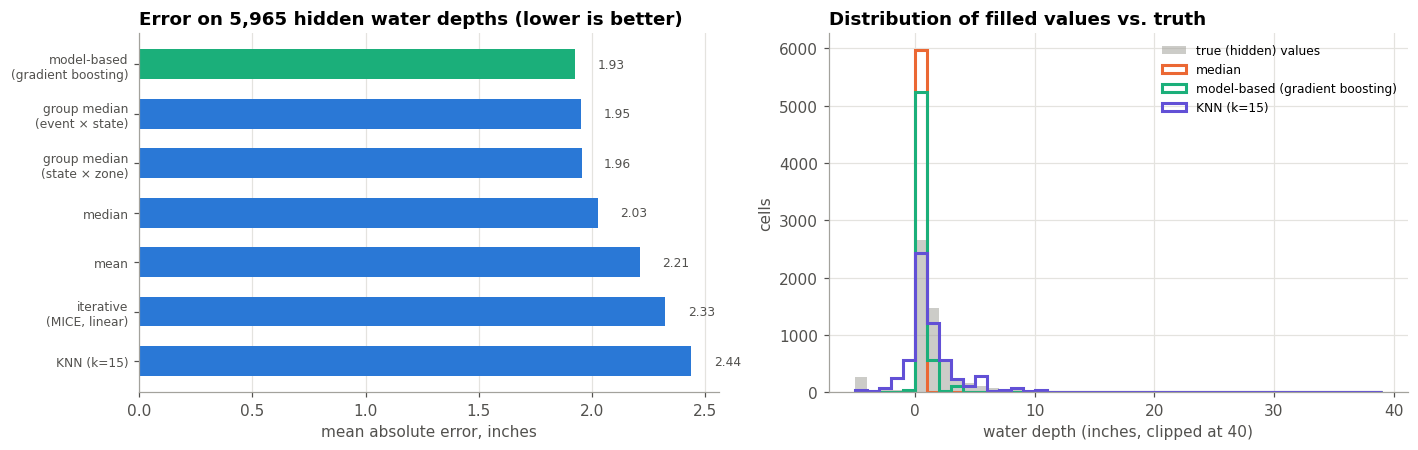

In [20]:
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor

exp = df[TRAIN & df["waterDepth"].notna().values].sample(30000, random_state=SEED).copy()
exp["zone_fam"] = exp["ratedFloodZone"].fillna("?").str.upper().str.replace(r"^(A\d+)$", "AE", regex=True).str[:2]
exp["elev"] = exp["elevatedBuildingIndicator"].astype(int)
exp["lcov"] = np.log1p(exp["totalBuildingInsuranceCoverage"])
exp["month"] = exp["dateOfLoss"].dt.month
exp["year"] = exp["dateOfLoss"].dt.year
exp["lat"] = exp["latitude"].fillna(exp["latitude"].median()); exp["lon"] = exp["longitude"].fillna(exp["longitude"].median())
exp["ev"] = exp["floodEvent"].fillna("none")
hide = rng.random(len(exp)) < 0.20
truth = exp.loc[hide, "waterDepth"].values
train_part = exp.loc[~hide]

fills = {}
fills["mean"] = np.full(hide.sum(), train_part["waterDepth"].mean())
fills["median"] = np.full(hide.sum(), train_part["waterDepth"].median())
g1 = train_part.groupby(["state", "zone_fam"])["waterDepth"].median()
fills["group median\n(state × zone)"] = pd.Series(list(zip(exp.loc[hide, "state"], exp.loc[hide, "zone_fam"]))).map(g1).fillna(train_part["waterDepth"].median()).values
g2 = train_part.groupby(["ev", "state"])["waterDepth"].median()
fills["group median\n(event × state)"] = pd.Series(list(zip(exp.loc[hide, "ev"], exp.loc[hide, "state"]))).map(g2).fillna(
    pd.Series(fills["group median\n(state × zone)"])).values
feat = ["lat", "lon", "lcov", "elev", "month", "year"]
X = exp[feat + ["waterDepth"]].copy(); X.loc[hide, "waterDepth"] = np.nan
mu, sd = X[feat].mean(), X[feat].std()
Xs = X.copy(); Xs[feat] = (X[feat] - mu) / sd
fills["KNN (k=15)"] = KNNImputer(n_neighbors=15).fit_transform(Xs)[hide, -1]
fills["iterative\n(MICE, linear)"] = IterativeImputer(random_state=SEED, max_iter=10).fit_transform(Xs)[hide, -1]
hgb = HistGradientBoostingRegressor(random_state=SEED, loss="absolute_error").fit(train_part[feat], train_part["waterDepth"])
fills["model-based\n(gradient boosting)"] = hgb.predict(exp.loc[hide, feat])

score = pd.DataFrame({k: {"MAE (inches)": np.mean(np.abs(v - truth)),
                          "KS distance to true dist.": stats.ks_2samp(v, truth).statistic,
                          "variance ratio (fill / true)": np.var(v) / np.var(truth)} for k, v in fills.items()}).T
score = score.sort_values("MAE (inches)")
display(score.style.format("{:.3f}").background_gradient(subset=["MAE (inches)"], cmap="Blues_r"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
names = score.index.tolist()
ax[0].barh(names[::-1], score["MAE (inches)"].values[::-1], color=[C[2] if n == names[0] else C[0] for n in names[::-1]], height=0.6)
for i, v in enumerate(score["MAE (inches)"].values[::-1]): ax[0].text(v + 0.1, i, f"{v:.2f}", va="center", fontsize=8, color=INK2)
ax[0].set(title=f"Error on {hide.sum():,} hidden water depths (lower is better)", xlabel="mean absolute error, inches"); ax[0].tick_params(axis="y", labelsize=8)
ax[0].grid(axis="y", visible=False)
bins = np.arange(-5, 40, 1)
ax[1].hist(np.clip(truth, -5, 39), bins=bins, color=GRAY, alpha=0.55, label="true (hidden) values")
for n, colr in [("median", C[1]), (names[0], C[2]), ("KNN (k=15)", C[6])]:
    ax[1].hist(np.clip(fills[n], -5, 39), bins=bins, histtype="step", lw=2, color=colr, label=n.replace("\n", " "))
ax[1].set(title="Distribution of filled values vs. truth", xlabel="water depth (inches, clipped at 40)", ylabel="cells"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("07_imputation_experiment"); plt.show()

**Reading experiment 1 (honestly).**

* The MAE differences are **small**: about 2.4 inches for the best methods vs 2.5 for a plain median. Most recorded depths are 0–3 inches, and pre-loss features say little about how deep the water got in one particular house.
* The **mean** is worse than the median, because the long tail pulls it up. **KNN** has the worst MAE but the most realistic spread. **MICE (linear)** is worse than the median, because the relationship is not linear.
* **No method recovers the true spread.** Every variance ratio is far below 1. Imputed depths are therefore "typical" depths, not real ones.

This experiment is the *easy* case: only one column is hidden, and every other predictor is present. In the real data that is rarely true.

### 7.3 Experiment 2: hide the whole adjuster block at once (joint masking)
Section 4.2 showed that building value, replacement cost and the three water depths go **missing together** (no adjuster record). An imputer that relies on the *other* block columns, such as KNN or MICE, looks good when only one cell is hidden but has nothing to lean on in reality. So the realistic test hides **all five block columns for the same 10% of rows**, using fully observed training-year claims, and compares four methods. The score is **RMSE ÷ SD of the truth**: 1.0 means "no better than guessing the mean", below 1 is skill.

,global median,group median (event × state),KNN (k=10),iterative (BayesianRidge)
log_bpv,1.006,0.989,0.581,0.692
log_brc,1.009,0.988,0.569,0.684
waterDepth,1.001,1.024,0.993,0.977
interiorWaterDepth,1.011,1.001,0.991,0.979
exteriorWaterDepth,1.049,0.981,0.886,0.941


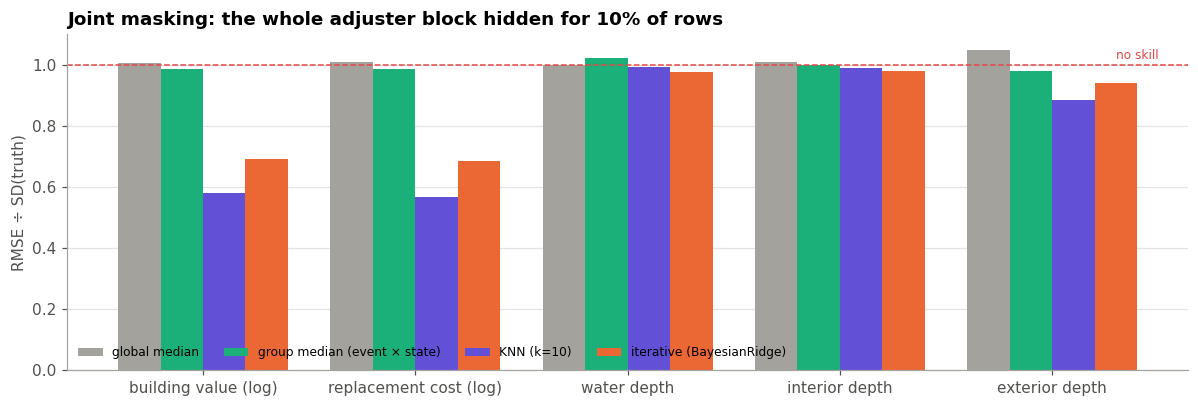

chosen per column: {'log_bpv': 'KNN (k=10)', 'log_brc': 'KNN (k=10)', 'waterDepth': 'iterative (BayesianRidge)', 'interiorWaterDepth': 'iterative (BayesianRidge)', 'exteriorWaterDepth': 'KNN (k=10)'}


In [21]:
BLOCK = ["log_bpv", "log_brc", "waterDepth", "interiorWaterDepth", "exteriorWaterDepth"]
PRED = ["log_bcov", "log_ccov", "log_pcount", "nobldg_", "latitude", "longitude", "is_rr2_", "elev_", "postfirm_", "msin", "mcos"]

def block_frame(frame):
    out = pd.DataFrame(index=frame.index)
    out["log_bpv"] = np.log1p(frame["buildingPropertyValue"]); out["log_brc"] = np.log1p(frame["buildingReplacementCost"])
    for c_ in ["waterDepth", "interiorWaterDepth", "exteriorWaterDepth"]: out[c_] = frame[c_]
    out["log_bcov"] = np.log1p(frame["totalBuildingInsuranceCoverage"]); out["log_ccov"] = np.log1p(frame["totalContentsInsuranceCoverage"].fillna(0))
    out["log_pcount"] = np.log1p(frame["policyCount"]); out["nobldg_"] = frame["totalBuildingInsuranceCoverage"].eq(0).astype(float)
    out["latitude"] = frame["latitude"]; out["longitude"] = frame["longitude"]
    out["is_rr2_"] = frame["rateMethod"].eq("RE").astype(float); out["elev_"] = frame["elevatedBuildingIndicator"].astype(float)
    out["postfirm_"] = frame["postFIRMConstructionIndicator"].astype(float)
    m_ = frame["dateOfLoss"].dt.month; out["msin"] = np.sin(2 * np.pi * m_ / 12); out["mcos"] = np.cos(2 * np.pi * m_ / 12)
    return out

Bdf = block_frame(df)
full_obs = Bdf[TRAIN & Bdf.notna().all(axis=1).values].sample(20000, random_state=SEED)
grp_key = df.loc[full_obs.index, ["floodEvent", "state"]].fillna("none")
mask_rows = rng.random(len(full_obs)) < 0.10
Xm = full_obs.copy(); Xm.loc[mask_rows, BLOCK] = np.nan
truth_blk = full_obs.loc[mask_rows, BLOCK]

res = {}
res["global median"] = pd.DataFrame({c_: np.full(mask_rows.sum(), Xm[c_].median()) for c_ in BLOCK}, index=truth_blk.index)
gm = pd.concat([grp_key, Xm[BLOCK]], axis=1)[~mask_rows].groupby(["floodEvent", "state"])[BLOCK].median()
key = pd.MultiIndex.from_frame(grp_key[mask_rows])
res["group median (event × state)"] = pd.DataFrame(gm.reindex(key).values, columns=BLOCK, index=truth_blk.index).fillna(Xm[BLOCK].median())
sc_ = StandardScaler().fit(Xm); Z = pd.DataFrame(sc_.transform(Xm), columns=Xm.columns, index=Xm.index)
knn_out = pd.DataFrame(KNNImputer(n_neighbors=10).fit_transform(Z), columns=Xm.columns, index=Xm.index) * sc_.scale_ + sc_.mean_
res["KNN (k=10)"] = knn_out.loc[mask_rows, BLOCK]
it_out = pd.DataFrame(IterativeImputer(estimator=BayesianRidge(), max_iter=8, random_state=SEED, initial_strategy="median").fit_transform(Xm),
                      columns=Xm.columns, index=Xm.index)
res["iterative (BayesianRidge)"] = it_out.loc[mask_rows, BLOCK]

joint = pd.DataFrame({m_: {c_: np.sqrt(np.mean((r_[c_] - truth_blk[c_]) ** 2)) / truth_blk[c_].std() for c_ in BLOCK} for m_, r_ in res.items()})
best_joint = joint.idxmin(axis=1)
display(joint.style.format("{:.3f}").highlight_min(axis=1, props="font-weight:bold; background-color:#d6e8fb"))

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(BLOCK)); w = 0.2
for i, (m_, colr) in enumerate(zip(joint.columns, [GRAY, C[2], C[6], C[1]])):
    ax.bar(x + (i - 1.5) * w, joint[m_], w, color=colr, label=m_)
ax.axhline(1, color=C[7], ls="--", lw=1); ax.text(len(BLOCK) - 0.5, 1.01, "no skill", color=C[7], fontsize=8, ha="right", va="bottom")
ax.set_xticks(x); ax.set_xticklabels(["building value (log)", "replacement cost (log)", "water depth", "interior depth", "exterior depth"])
ax.set(title="Joint masking: the whole adjuster block hidden for 10% of rows", ylabel="RMSE ÷ SD(truth)"); ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, ncol=4, loc="lower left"); plt.tight_layout(); savefig("07_joint_masking"); plt.show()
print("chosen per column:", best_joint.to_dict())

**Reading experiment 2.** The block splits in two:
* **Building value and replacement cost are predictable.** KNN cuts the error to about 0.58 of the SD, because coverage, policy count and location (pre-loss facts that are never missing) say a lot about how valuable a building is. Group medians barely beat a global median (≈ 0.99). **KNN is applied** to these two.
* **Water depths are essentially unpredictable** from pre-loss facts. Every method scores 0.89–1.02, so it is no better than guessing the typical depth. MICE (≈ 0.98) and KNN (≈ 0.89 for exterior depth) win narrowly and are applied, but the honest conclusion is that **an imputed depth is a placeholder**. Models must rely on the `_missing` flag, and RQ3 should use measured depths only.

The winner per column is applied in 7.4. Every filled column keeps a `_missing` flag, because missingness predicts the outcome (4.5).

### 7.4 Apply the imputation plan (fit on train years, applied to all rows)

In [22]:
clean = df.copy()
imp_log = []
def logi(col, strategy, n, why):
    imp_log.append({"column": col, "strategy": strategy, "cells filled": int(n), "why": why})

no_cont = clean["totalContentsInsuranceCoverage"].fillna(0) == 0
no_bldg = clean["totalBuildingInsuranceCoverage"] == 0

# --- Structural zeros -------------------------------------------------------------------
for c, netc in [("amountPaidOnBuildingClaim", "netBuildingPaymentAmount"), ("amountPaidOnContentsClaim", "netContentsPaymentAmount"),
                ("amountPaidOnIncreasedCostOfComplianceClaim", "netIccPaymentAmount")]:
    m = clean[c].isna() & clean[netc].eq(0)
    clean.loc[m, c] = 0.0; logi(c, "structural 0", m.sum(), "closed without payment (net payment = 0)")
for c in ["contentsDamageAmount", "contentsPropertyValue"]:
    m = clean[c].isna() & no_cont
    clean[f"{c}_missing"] = (clean[c].isna() & ~no_cont).astype("int8")
    clean.loc[m, c] = 0.0; logi(c, "structural 0 (+ flag for the rest)", m.sum(), "policy has no contents coverage")

# --- Explicit levels for categoricals ---------------------------------------------------
m = clean["obstructionType"].isna() & ~clean["elevatedBuildingIndicator"]
clean["obstructionType"] = clean["obstructionType"].astype("Int64").astype("string")
clean.loc[m, "obstructionType"] = "not_applicable"; logi("obstructionType", "level 'not_applicable'", m.sum(), "building not elevated")
m2 = clean["obstructionType"].isna(); clean.loc[m2, "obstructionType"] = "unknown"; logi("obstructionType", "level 'unknown'", m2.sum(), "elevated, type not reported")

clean["contentsDeductibleCode"] = clean["contentsDeductibleCode"].astype("string")
m = clean["contentsDeductibleCode"].isna() & no_cont
clean.loc[m, "contentsDeductibleCode"] = "no_contents_cov"; logi("contentsDeductibleCode", "level 'no_contents_cov'", m.sum(), "no contents coverage")
clean["buildingDeductibleCode"] = clean["buildingDeductibleCode"].astype("string")
m = clean["buildingDeductibleCode"].isna() & no_bldg
clean.loc[m, "buildingDeductibleCode"] = "no_building_cov"; logi("buildingDeductibleCode", "level 'no_building_cov'", m.sum(), "contents-only policy")
for c in ["contentsDeductibleCode", "buildingDeductibleCode", "basementEnclosureCrawlspaceType", "locationOfContents",
          "buildingDescriptionCode", "causeOfDamage", "foundationType"]:
    s = clean[c]
    if s.dtype.kind == "f": s = s.astype("Int64")
    s = s.astype("string"); n = s.isna().sum()
    clean[c] = s.fillna("unknown"); logi(c, "level 'unknown'", n, "MAR/MNAR categorical; missingness is informative")
n = clean["floodEvent"].isna().sum()
clean["floodEvent"] = clean["floodEvent"].fillna("no_named_event"); logi("floodEvent", "level 'no_named_event'", n, "structural: no designated catastrophe")

# --- Deterministic lookup: CRS class is a community attribute (table built from train years) ----
crs_by_comm = clean[TRAIN].dropna(subset=["crsClassCode"]).groupby("nfipRatedCommunityNumber")["crsClassCode"].agg(lambda s: s.mode().iloc[0])
before = clean["crsClassCode"].isna().sum()
clean["crsClassCode"] = clean["crsClassCode"].fillna(clean["nfipRatedCommunityNumber"].map(crs_by_comm))
logi("crsClassCode", "lookup: same NFIP community's class (train-year table)", before - clean["crsClassCode"].isna().sum(),
     "every community with data has exactly one CRS class")
clean["crs_unknown"] = clean["crsClassCode"].isna().astype("int8")   # remaining unknowns keep a flag
n = clean["crsClassCode"].isna().sum()
clean["crsClassCode"] = fill_hierarchical(clean, "crsClassCode", [["state"]])
logi("crsClassCode", "train median by state + crs_unknown flag", n, "community has no CRS record at all")

# --- Mode for tiny categoricals (train mode) ---------------------------------------------
for c in ["condominiumCoverageTypeCode", "replacementCostBasis", "numberOfFloorsInTheInsuredBuilding", "ratedFloodZone"]:
    n = clean[c].isna().sum(); clean[c] = clean[c].fillna(train_stat(clean, c, "mode")); logi(c, "mode (train)", n, "< 1% missing, MCAR-plausible")
n = clean["state"].isna().sum(); clean["state"] = clean["state"].fillna("UNK"); logi("state", "level 'UNK'", n, "1 blank state")

# --- Median for tiny skewed numerics (train median) --------------------------------------
for col in ["numberOfUnits", "totalContentsInsuranceCoverage"]:
    n = clean[col].isna().sum(); clean[col] = clean[col].fillna(train_stat(clean, col))
    logi(col, "median (train)", n, "≤ 1% missing, right-skewed")

# --- Spatial hierarchical fill (train medians) -------------------------------------------
for c in ["latitude", "longitude"]:
    n = clean[c].isna().sum()
    clean[c] = fill_hierarchical(clean, c, [["countyCode"], ["state"]])
    logi(c, "train median county → state → global", n, "location is best predicted by its county")

# --- Adjuster block: method per column from the joint-masking experiment ------------------
src = {"log_bpv": "buildingPropertyValue", "log_brc": "buildingReplacementCost",
       "waterDepth": "waterDepth", "interiorWaterDepth": "interiorWaterDepth", "exteriorWaterDepth": "exteriorWaterDepth"}
for col in src.values(): clean[f"{col}_missing"] = clean[col].isna().astype("int8")
for col in ["buildingPropertyValue", "buildingReplacementCost"]:      # contents-only policies: no building insured → structural 0
    m = clean[col].isna() & no_bldg
    clean.loc[m, col] = 0.0; logi(col, "structural 0", m.sum(), "contents-only policy: no insured building to value (observed rows of this kind are 0)")
B_all = block_frame(clean)
fit_rows = B_all[TRAIN].sample(40000, random_state=SEED)
need = B_all[BLOCK].isna().any(axis=1)
filled = {}
if (best_joint == "iterative (BayesianRidge)").any():
    it = IterativeImputer(estimator=BayesianRidge(), max_iter=8, random_state=SEED, initial_strategy="median",
                          min_value=fit_rows.min().values, max_value=fit_rows.max().values).fit(fit_rows)
    filled["iterative (BayesianRidge)"] = pd.DataFrame(it.transform(B_all[need]), columns=B_all.columns, index=B_all.index[need])
if (best_joint == "KNN (k=10)").any():
    fr = fit_rows.fillna(fit_rows.median()); sk = StandardScaler().fit(fr)
    knn = KNNImputer(n_neighbors=10).fit(pd.DataFrame(sk.transform(fit_rows), columns=fit_rows.columns))
    Zn = pd.DataFrame(sk.transform(B_all[need]), columns=B_all.columns, index=B_all.index[need])
    parts = [pd.DataFrame(knn.transform(Zn.iloc[i:i + 20000]), columns=B_all.columns, index=Zn.index[i:i + 20000]) for i in range(0, len(Zn), 20000)]
    filled["KNN (k=10)"] = pd.concat(parts) * sk.scale_ + sk.mean_
for bc, col in src.items():
    miss_ = clean[col].isna(); n = miss_.sum()
    method = best_joint[bc]
    if method in filled:
        vals = filled[method].loc[miss_[miss_].index, bc]
        if bc.startswith("log_"): vals = np.expm1(vals)
        clean.loc[miss_, col] = vals.values
    else:   # group median (event × state) or global median, both from train rows
        levels = [["floodEvent", "state"], ["state"]] if method.startswith("group") else []
        clean[col] = fill_hierarchical(clean, col, levels)
    logi(col, f"{method} (chosen by joint masking) + flag", n, "MNAR-likely block; flag keeps the 'not measured' signal")
B_after = block_frame(clean)

# --- Not imputed ---------------------------------------------------------------------------
clean["has_elevation_data"] = clean["elevationDifference"].notna().astype("int8")
logi("elevationDifference", "NOT imputed; has_elevation_data flag", 0, "66% missing: use on the EC subset only")
logi("buildingDamageAmount", "NOT imputed (RQ2 target)", 0, "never impute a label; rows excluded from RQ2")
logi("contentsDamageAmount / contentsPropertyValue", "remaining NaN left + *_missing flag", 0,
     "coverage existed but no adjuster figure (MNAR); post-loss, EDA only")

imp_log = pd.DataFrame(imp_log)
imp_log

,column,strategy,cells filled,why
0,amountPaidOnBuildingClaim,structural 0,21568,closed without payment (net payment = 0)
1,amountPaidOnContentsClaim,structural 0,21568,closed without payment (net payment = 0)
2,amountPaidOnIncreasedCostOfComplianceClaim,structural 0,21568,closed without payment (net payment = 0)
3,contentsDamageAmount,structural 0 (+ flag for the rest),62210,policy has no contents coverage
4,contentsPropertyValue,structural 0 (+ flag for the rest),61757,policy has no contents coverage
5,obstructionType,level 'not_applicable',215578,building not elevated
6,obstructionType,level 'unknown',1336,"elevated, type not reported"
7,contentsDeductibleCode,level 'no_contents_cov',78604,no contents coverage
8,buildingDeductibleCode,level 'no_building_cov',6435,contents-only policy
9,contentsDeductibleCode,level 'unknown',7,MAR/MNAR categorical; missingness is informative


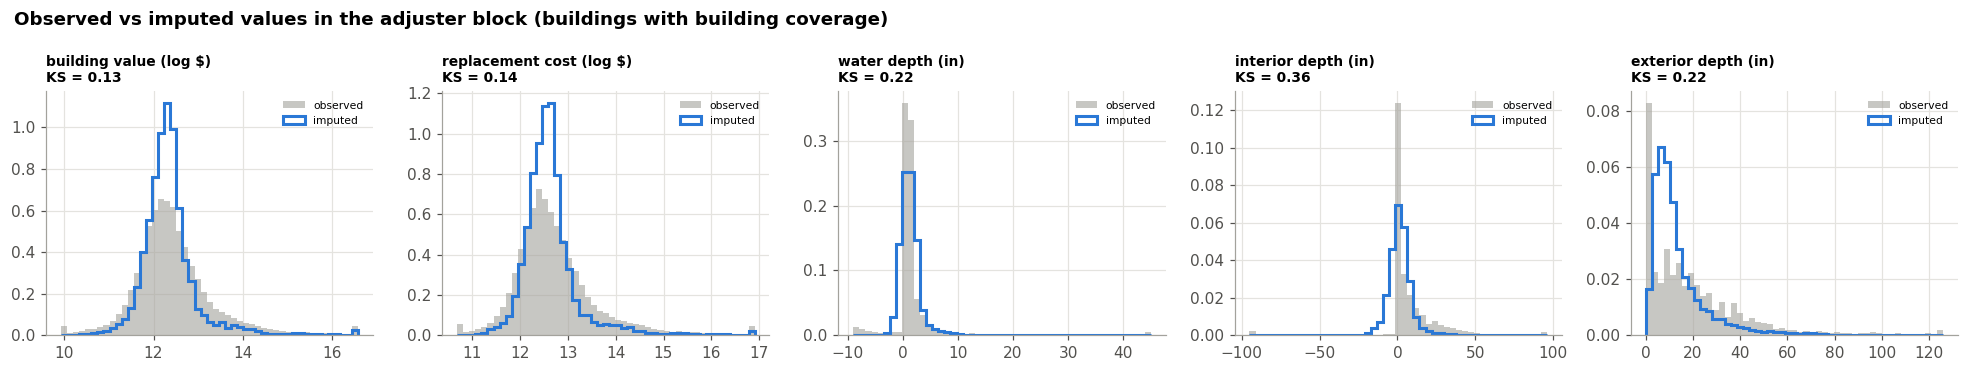

,method,n imputed,median observed,median imputed,SD observed,SD imputed,KS
column,,,,,,,
buildingPropertyValue,KNN (k=10),51749,12.325,12.289,0.970,0.671,0.132
buildingReplacementCost,KNN (k=10),51319,12.585,12.562,0.932,0.642,0.136
waterDepth,iterative (BayesianRidge),53034,1.000,1.026,7.734,1.884,0.221
interiorWaterDepth,iterative (BayesianRidge),94625,2.000,1.333,23.756,7.971,0.358
exteriorWaterDepth,KNN (k=10),45948,14.000,9.900,24.505,12.397,0.215


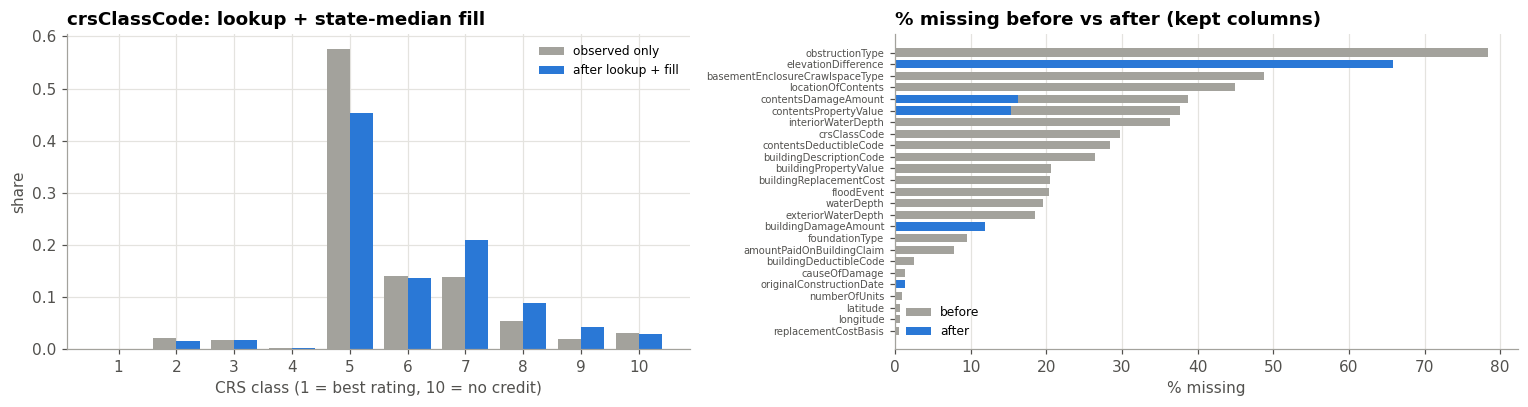

In [23]:
# Before/after: did the imputation distort the distributions? Observed vs imputed values, with a KS statistic per column
ks_rows = []
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
labels = {"log_bpv": "building value (log $)", "log_brc": "replacement cost (log $)", "waterDepth": "water depth (in)",
          "interiorWaterDepth": "interior depth (in)", "exteriorWaterDepth": "exterior depth (in)"}
for ax, bc in zip(axes, BLOCK):
    miss_ = Bdf[bc].isna() & ~no_bldg.values; obs = Bdf.loc[Bdf[bc].notna() & ~no_bldg.values, bc]; imp_v = B_after.loc[miss_, bc]
    lo, hi = obs.quantile([0.005, 0.995])
    ks = stats.ks_2samp(obs, imp_v)
    ks_rows.append({"column": src[bc], "method": best_joint[bc], "n imputed": int(miss_.sum()), "median observed": obs.median(),
                    "median imputed": imp_v.median(), "SD observed": obs.std(), "SD imputed": imp_v.std(), "KS": ks.statistic})
    bins = np.linspace(lo, hi, 50)
    ax.hist(obs.clip(lo, hi), bins=bins, density=True, color=GRAY, alpha=0.6, label="observed")
    ax.hist(imp_v.clip(lo, hi), bins=bins, density=True, histtype="step", lw=2, color=C[0], label="imputed")
    ax.set_title(f"{labels[bc]}\nKS = {ks.statistic:.2f}", fontsize=9); ax.legend(fontsize=7)
fig.suptitle("Observed vs imputed values in the adjuster block (buildings with building coverage)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig("07_imputed_vs_observed"); plt.show()
display(pd.DataFrame(ks_rows).set_index("column").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
a = df["crsClassCode"].value_counts(normalize=True).sort_index(); b = clean["crsClassCode"].round().value_counts(normalize=True).sort_index()
x = np.arange(1, 11); w = 0.4
axes[0].bar(x - w/2, a.reindex(x, fill_value=0), w, color=GRAY, label="observed only")
axes[0].bar(x + w/2, b.reindex(x, fill_value=0), w, color=C[0], label="after lookup + fill")
axes[0].set(title="crsClassCode: lookup + state-median fill", xlabel="CRS class (1 = best rating, 10 = no credit)", ylabel="share"); axes[0].set_xticks(x)
axes[0].legend(fontsize=8)
after = clean.isna().mean().mul(100); before = df.isna().mean().mul(100)
kept = [c for c in before.index if c not in DROP]
top = before[kept][before[kept] > 0].sort_values(ascending=False).head(25).index
axes[1].barh(top[::-1], before[top][::-1], color=GRAY, height=0.7, label="before")
axes[1].barh(top[::-1], after[top][::-1], color=C[0], height=0.7, label="after")
axes[1].tick_params(axis="y", labelsize=6.5); axes[1].legend(fontsize=8)
axes[1].set(title="% missing before vs after (kept columns)", xlabel="% missing"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); savefig("07_imputation_before_after"); plt.show()

**What the before/after shows.** Imputed values stay inside the observed range, but their spread is narrower than the observed one, as experiment 1 predicted. They are "typical" values, which is why every filled column keeps its `_missing` flag and why RQ3 should cluster on measured values only. The KS column quantifies the gap per column. The CRS lookup restores true classes. The remaining state-median fill moves some mass between classes, so `crs_unknown` should stay in every model that uses CRS. In the right panel, everything still missing among *kept* columns is deliberate: elevation difference (sparse, not imputed), contents figures with coverage but no adjuster record, and the RQ2 label.

## 8. Outliers and noise

Two kinds of unusual value are separated:

* **Noise / invalid values**: impossible by definition (negative payments, a building built after it flooded, an opening date before the loss). These are **fixed** (set to NaN or capped), with counts logged.
* **Negative water depths** look like noise but are kept: those claims are paid *more* often than claims at depth 0 (printed below the table). The depth is measured relative to the lowest floor, so water below it is real information.
* **Genuine extremes**: real but rare (a $10M commercial claim). These are **kept**, because they are the claims FEMA cares most about. Their influence is handled with a **log transform** and, for scale-sensitive models only, **winsorising** at the 99.9th percentile.

### 8.0 Profile of every numeric column
Before deciding what is an outlier, every numeric column is profiled: range, percentiles, skew, how many values are negative or zero, and how many fall outside 3 × IQR.

In [24]:
num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and df[c].dtype != bool and df[c].notna().any() and c != "id"]
prof_rows = []
for c in num_cols:
    s = df[c].dropna(); q = s.quantile([.01, .25, .5, .75, .99]); iqr = q[.75] - q[.25]
    prof_rows.append({"column": c, "n": len(s), "min": s.min(), "p01": q[.01], "median": q[.5], "mean": s.mean(), "p99": q[.99], "max": s.max(),
                      "skew": stats.skew(s) if s.nunique() > 1 else 0, "n_negative": int((s < 0).sum()), "n_zero": int((s == 0).sum()),
                      "outside 3×IQR": int(((s < q[.25] - 3 * iqr) | (s > q[.75] + 3 * iqr)).sum()) if iqr > 0 else 0})
num_profile = pd.DataFrame(prof_rows).set_index("column").sort_values("skew", key=abs, ascending=False)
num_profile.to_csv(OUT_DIR / "numeric_profile.csv")
num_profile.style.format({k: "{:,.1f}" for k in ["min", "p01", "median", "mean", "p99", "max"]} | {"skew": "{:.1f}", "n": "{:,}", "n_negative": "{:,}",
                                                                                                    "n_zero": "{:,}", "outside 3×IQR": "{:,}"})

,n,min,p01,median,mean,p99,max,skew,n_negative,n_zero,outside 3×IQR
column,,,,,,,,,,,
numberOfUnits,"273,862",0.0,0.0,1.0,2.9,41.0,"34,970.0",461.7,0,"14,556",0
contentsReplacementCost,"172,336",-1.0,0.0,0.0,"16,938.0","219,948.9","100,000,000.0",254.9,1,"147,917",0
netIccPaymentAmount,"276,580",0.0,0.0,0.0,86.8,0.0,"900,000.0",217.1,0,"275,535",0
amountPaidOnIncreasedCostOfComplianceClaim,"255,012",0.0,0.0,0.0,94.2,0.0,"900,000.0",208.4,0,"253,967",0
contentsPropertyValue,"172,336",0.0,0.0,"40,000.0","109,990.0","916,784.0","250,000,000.0",126.7,0,"66,029","6,862"
buildingDamageAmount,"243,861",0.0,0.0,"27,746.0","68,738.3","525,304.6","52,840,990.0",95.4,0,"25,001","4,707"
buildingReplacementCost,"220,030",0.0,"44,728.0","290,992.0","922,084.7","11,054,046.4","1,673,931,037.0",95.3,0,"1,072","16,572"
contentsDamageAmount,"169,405",0.0,0.0,"2,258.0","18,918.6","130,570.3","16,741,290.0",57.2,0,"66,411","7,781"
buildingPropertyValue,"219,600",0.0,"20,817.0","224,288.0","664,637.5","8,270,426.2","526,308,898.0",45.8,0,"1,074","16,208"


### 8.1 Skew makes the textbook outlier rules misleading

In [25]:
money = ["amountPaidOnBuildingClaim", "buildingDamageAmount", "buildingPropertyValue", "totalBuildingInsuranceCoverage",
         "contentsDamageAmount", "totalContentsInsuranceCoverage", "policyCount", "waterDepth"]
def iqr_out(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean()
rows = []
for c in money:
    s = clean[c].dropna(); s = s[s >= 0]; ls = np.log1p(s)
    rows.append({"column": c, "skew (raw)": stats.skew(s), "skew (log1p)": stats.skew(ls),
                 "IQR outliers raw": iqr_out(s), "IQR outliers log": iqr_out(ls),
                 "|z|>3 raw": (np.abs(stats.zscore(s)) > 3).mean(), "|z|>3 log": (np.abs(stats.zscore(ls)) > 3).mean(),
                 "max": s.max(), "p99.9": s.quantile(.999)})
out_tbl = pd.DataFrame(rows).set_index("column")
out_tbl.style.format({"skew (raw)": "{:.1f}", "skew (log1p)": "{:.2f}", "IQR outliers raw": "{:.1%}", "IQR outliers log": "{:.1%}",
                      "|z|>3 raw": "{:.2%}", "|z|>3 log": "{:.2%}", "max": "{:,.0f}", "p99.9": "{:,.0f}"})

,skew (raw),skew (log1p),IQR outliers raw,IQR outliers log,|z|>3 raw,|z|>3 log,max,p99.9
column,,,,,,,,
amountPaidOnBuildingClaim,18.5,-1.00,5.8%,23.0%,1.06%,0.00%,"10,741,477","1,742,828"
buildingDamageAmount,95.4,-1.87,5.6%,10.4%,0.50%,0.00%,"52,840,990","1,853,091"
buildingPropertyValue,49.7,-4.43,11.0%,9.6%,0.54%,2.32%,"526,308,898","44,982,650"
totalBuildingInsuranceCoverage,38.4,-4.77,16.4%,21.8%,0.70%,2.37%,"272,500,000","28,855,250"
contentsDamageAmount,66.6,0.36,14.0%,0.0%,0.19%,0.00%,"16,741,290","605,205"
totalContentsInsuranceCoverage,3.6,-0.84,1.4%,0.0%,1.45%,0.00%,"500,000","500,000"
policyCount,35.3,6.52,4.6%,4.6%,0.72%,2.52%,"1,090",125
waterDepth,17.7,1.36,6.8%,2.3%,1.57%,1.81%,800,83


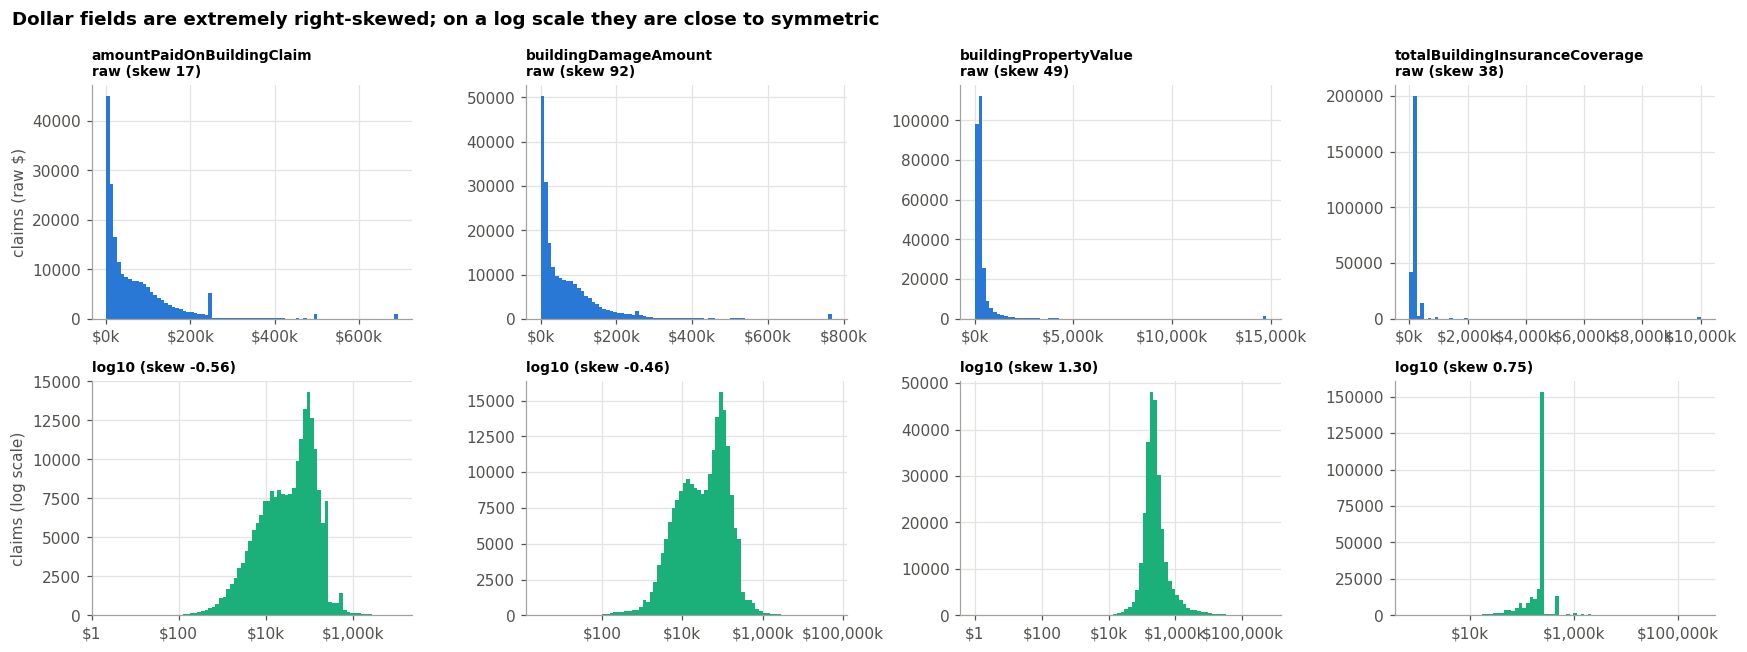

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes[0], ["amountPaidOnBuildingClaim", "buildingDamageAmount", "buildingPropertyValue", "totalBuildingInsuranceCoverage"]):
    s = clean[c]; s = s[s > 0]
    ax.hist(s.clip(upper=s.quantile(.995)), bins=80, color=C[0]); ax.set_title(f"{c}\nraw (skew {stats.skew(s):.0f})", fontsize=9)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:,.0f}k"))
for ax, c in zip(axes[1], ["amountPaidOnBuildingClaim", "buildingDamageAmount", "buildingPropertyValue", "totalBuildingInsuranceCoverage"]):
    s = clean[c]; s = s[s > 0]
    ax.hist(np.log10(s), bins=80, color=C[2]); ax.set_title(f"log10 (skew {stats.skew(np.log10(s)):.2f})", fontsize=9)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${10**v:,.0f}" if v < 4 else f"${10**v/1e3:,.0f}k"))
axes[0, 0].set_ylabel("claims (raw $)"); axes[1, 0].set_ylabel("claims (log scale)")
fig.suptitle("Dollar fields are extremely right-skewed; on a log scale they are close to symmetric", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig("08_skew_log_transform"); plt.show()

On raw dollars, the IQR rule flags about 10% of claims as "outliers". That is a property of the skew, not of bad data. After `log1p`, skew drops to about 0 and only a small share is flagged. **Conclusion: transform, don't delete.**

### 8.2 Domain validity rules (noise)

In [27]:
c = clean
age_days = (c["dateOfLoss"] - c["originalConstructionDate"]).dt.days
noise_rules = {
    "negative building payment (reissued/uncashed check)": c["amountPaidOnBuildingClaim"] < 0,
    "building payment > building coverage + $1": c["amountPaidOnBuildingClaim"] > c["totalBuildingInsuranceCoverage"] + 1,
    "construction date after date of loss": age_days < 0,
    "construction date before 1850": c["originalConstructionDate"] < "1850-01-01",
    "policy start (originalNBDate) after loss": c["originalNBDate"] > c["dateOfLoss"],
    "policy start before 1968 (NFIP did not exist)": c["originalNBDate"] < "1968-01-01",
    "claim opened before the loss": c["openDate"] < c["dateOfLoss"],
    "claim opened > 365 days after loss": (c["openDate"] - c["dateOfLoss"]).dt.days > 365,
    "building damage > building value (ACV)": c["buildingDamageAmount"] > c["buildingPropertyValue"] * 1.0001,
    "single-family coverage above $250k statutory limit": (c["occupancyType"].isin([1, 11])) & (c["totalBuildingInsuranceCoverage"] > 250_000),
    "water depth < 0 (below lowest floor)": df["waterDepth"] < 0,
    "last payment date before the claim was opened": c["mostRecentPaymentDate"] < c["openDate"],
    "net building payment > building damage": c["netBuildingPaymentAmount"] > c["buildingDamageAmount"] + 1,
    "ZIP code not 5 characters": c["reportedZipCode"].astype(str).str.len() != 5,
    "blank state": raw.loc[~dmask_extra.values, "state"].fillna("").str.strip().eq("").values,
}
noise = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in noise_rules.items()},
                      "% rows": {k: round(100 * v.mean(), 3) for k, v in noise_rules.items()}})
noise["treatment"] = ["clip to 0 in target", "keep + flag (limits/ICC adjustments)", "→ NaN, then impute age", "→ NaN, then impute age",
                      "→ NaN (tenure unknown)", "→ NaN (tenure unknown)", "→ NaN (lag unknown)", "cap lag at 365", "keep + flag (ACV vs RC basis)",
                      "check passed: none found" if noise_rules["single-family coverage above $250k statutory limit"].sum() == 0 else "keep + flag",
                      "keep: valid, depth is relative to lowest floor (evidence below)",
                      "keep (payment-date field is leakage, not a feature)", "keep + flag (RC-basis settlements can exceed ACV damage)",
                      "keep (ZIP is not a feature)", "→ 'UNK'"]
display(noise)
wd_raw = df["waterDepth"]; paid_ = df["netBuildingPaymentAmount"].gt(0)
print("Why negative water depths are kept: share of claims with a building payment")
print(pd.Series({"depth < 0": paid_[wd_raw < 0].mean(), "depth = 0": paid_[wd_raw == 0].mean(),
                 "depth > 0": paid_[wd_raw > 0].mean(), "depth missing": paid_[wd_raw.isna()].mean()}).map("{:.0%}".format).to_string())

,rows,% rows,treatment
negative building payment (reissued/uncashed check),35,0.013,clip to 0 in target
building payment > building coverage + $1,665,0.240,keep + flag (limits/ICC adjustments)
construction date after date of loss,90,0.033,"→ NaN, then impute age"
construction date before 1850,125,0.045,"→ NaN, then impute age"
policy start (originalNBDate) after loss,6339,2.292,→ NaN (tenure unknown)
policy start before 1968 (NFIP did not exist),30,0.011,→ NaN (tenure unknown)
claim opened before the loss,56,0.020,→ NaN (lag unknown)
claim opened > 365 days after loss,994,0.359,cap lag at 365
building damage > building value (ACV),2053,0.742,keep + flag (ACV vs RC basis)
single-family coverage above $250k statutory limit,0,0.000,check passed: none found


Why negative water depths are kept: share of claims with a building payment
depth < 0        87%
depth = 0        66%
depth > 0        93%
depth missing    56%


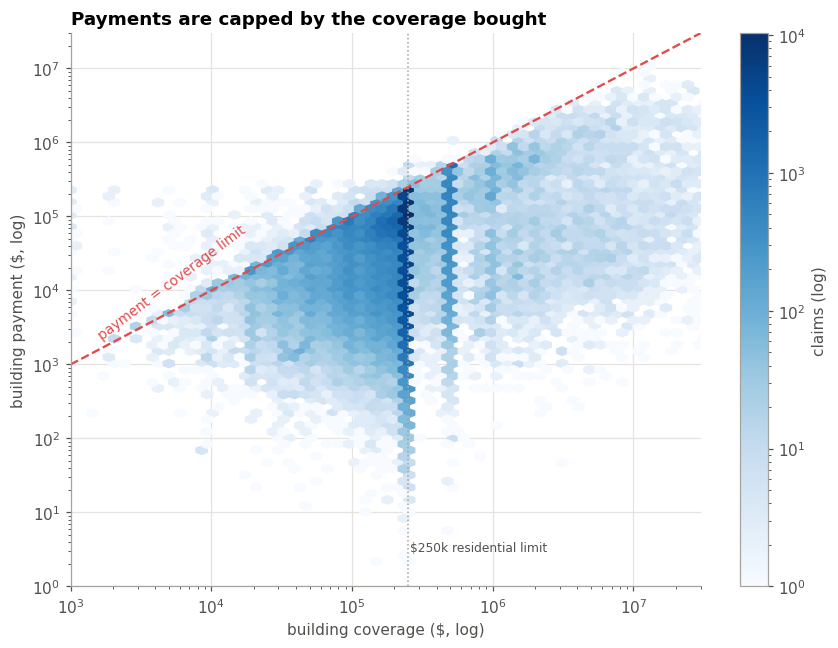

points above the line (noise flag): 665 (0.24%)


In [28]:
# Apply the noise fixes
clean["amountPaidOnBuildingClaim"] = clean["amountPaidOnBuildingClaim"].clip(lower=0)
clean.loc[(age_days < 0) | (clean["originalConstructionDate"] < "1850-01-01"), "originalConstructionDate"] = pd.NaT
clean.loc[(clean["originalNBDate"] > clean["dateOfLoss"]) | (clean["originalNBDate"] < "1968-01-01"), "originalNBDate"] = pd.NaT
clean["net_payment_exceeds_damage"] = noise_rules["net building payment > building damage"].astype("int8")
clean["paid_exceeds_coverage"] = noise_rules["building payment > building coverage + $1"].astype("int8")
clean["damage_exceeds_value"] = noise_rules["building damage > building value (ACV)"].astype("int8")

fig, ax = plt.subplots(figsize=(8, 6))
s = clean[(clean["amountPaidOnBuildingClaim"] > 0) & (clean["totalBuildingInsuranceCoverage"] > 0)]
hb = ax.hexbin(s["totalBuildingInsuranceCoverage"], s["amountPaidOnBuildingClaim"], gridsize=70, xscale="log", yscale="log",
               bins="log", cmap="Blues", mincnt=1)
lim = [1e3, 3e7]; ax.plot(lim, lim, color=C[7], lw=1.5, ls="--"); ax.text(1.5e3, 2.2e3, "payment = coverage limit", color=C[7], rotation=37, fontsize=9)
ax.set(xlim=lim, ylim=[1, 3e7], title="Payments are capped by the coverage bought", xlabel="building coverage ($, log)", ylabel="building payment ($, log)")
ax.axvline(250_000, color=GRAY, ls=":", lw=1); ax.text(260_000, 3, "$250k residential limit", color=INK2, fontsize=8)
plt.colorbar(hb, ax=ax, label="claims (log)"); plt.tight_layout(); savefig("08_coverage_vs_payment"); plt.show()
print(f"points above the line (noise flag): {clean['paid_exceeds_coverage'].sum():,} ({pct(clean['paid_exceeds_coverage'].mean(), 2)})")

The payment ≤ coverage ceiling is a **hard business rule**, and the cloud stays under the red line. The dense vertical stripe at **$250k** is the residential statutory limit. Many claims pile up right at their limit, so **coverage sets the ceiling for RQ1**, and some claims are "censored" at the limit (the true loss was larger). The few points above the line (665) are flagged, not deleted. They include **68 paid building claims on policies with $0 building coverage**, which is impossible by definition. The feature-selection notebook shows how such a handful of rows can capture a huge linear coefficient.

## 9. Feature engineering

Every new feature uses only information available **at claim time**, unless it is marked *(post-loss)*. Fill values and thresholds are fit on the **training years**.

| New feature | Formula | Domain reason |
|---|---|---|
| `building_age` | (dateOfLoss − originalConstructionDate) in years | Older buildings predate floodplain codes and modern materials |
| `construction_date_jan1` | construction date is 1 January | About half the dates are year-only placeholders, so age is less precise there |
| `bldg_age_invalid_or_missing`, `tenure_invalid_or_missing` | date missing or invalid before the fill | Keeps the "we don't know" signal after imputation |
| `policy_tenure_years` | (dateOfLoss − originalNBDate) | Long-tenured policies are often grandfathered / older risk |
| `report_lag_days` | openDate − dateOfLoss, capped at 365 | Late reporting hints at minor or contested losses |
| `flood_zone_family` | 52 zone codes → A / AE / AH / AO / A99 / V / X / D | FEMA's own risk families; A1–A30 are legacy AE |
| `rating_group` | rateMethod → RR2.0 / manual / PRP / group / pre-FIRM elevated / specific / other | 15 rate codes, most of them rare |
| `is_rr2` | rateMethod == "RE" | Rating regime; explains missing fields (Section 4.3) |
| `bldg_deductible_usd`, `cont_deductible_usd` | deductible code → dollars ($0 when that coverage does not exist) | Ordinal codes become their real amounts |
| `no_building_cov`, `no_contents_cov` | coverage == 0 | Contents-only / building-only policies behave differently |
| `is_named_event`, `flood_event_grp` | designated catastrophe; top 12 events + other | Catastrophe claims differ. The event name is a *grouping key* for CV, not a feature |
| `loss_month_sin`, `loss_month_cos`, `loss_dow` | cyclic month; day of week | Hurricane season; weekday effects in reporting |
| `has_elevation_data`, `*_missing` flags | 1 if the field was recorded | Missingness is informative (Section 4.5) |
| `log_*`, `*_w` | log1p of money and counts, winsorised at the train 99.9th percentile; depths winsorised at train p1/p99.5 | Removes skew and tames the tail (Section 8) for linear models and PCA |
| `coverage_to_value`, `damage_to_value_ratio` *(post-loss)* | coverage ÷ replacement cost; damage ÷ property value | Under-insurance; how much of the building was lost |
| `cause_group` *(post-loss)* | causeOfDamage → rainfall / tidal / river / expedited / other | Grouped adjuster code for EDA and RQ3 profiling |
| `log_paid_building` | log1p(amountPaidOnBuildingClaim) | RQ1 target on a symmetric scale |
| `high_severity` | buildingDamageAmount ≥ train 80th percentile | RQ2 label (top 20%, as proposed) |

In [29]:
c = clean
oc = c["originalConstructionDate"]
c["construction_date_jan1"] = ((oc.dt.month == 1) & (oc.dt.day == 1)).astype("int8")
c["bldg_age_invalid_or_missing"] = oc.isna().astype("int8")
c["tenure_invalid_or_missing"] = c["originalNBDate"].isna().astype("int8")
occ_map = {1: 11, 2: 12, 3: 13, 4: 18, 6: 18}
occ_lbl = {11: "single family", 12: "2–4 units", 13: "5+ units", 14: "mobile home", 15: "condo association",
           16: "unit in multi-unit bldg", 17: "non-res mobile", 18: "non-residential", 19: "non-res unit"}
c["occupancy"] = c["occupancyType"].replace(occ_map).map(occ_lbl).fillna("other")
c["building_age"] = (c["dateOfLoss"] - oc).dt.days / 365.25
c["building_age"] = fill_hierarchical(c, "building_age", [["state", "occupancy"], ["occupancy"]])
c["policy_tenure_years"] = (c["dateOfLoss"] - c["originalNBDate"]).dt.days / 365.25
c["policy_tenure_years"] = fill_hierarchical(c, "policy_tenure_years", [["state", "occupancy"]])
lag = (c["openDate"] - c["dateOfLoss"]).dt.days
c["report_lag_days"] = lag.where(lag >= 0).clip(upper=365)
c["report_lag_days"] = c["report_lag_days"].fillna(train_stat(c, "report_lag_days"))

def zone_family(z):
    z = str(z).strip().upper()
    if z in ("X", "B", "C"): return "X (moderate/low)"
    if z.startswith("V"): return "V (coastal high hazard)"
    if z in ("AH", "AHB"): return "AH (ponding)"
    if z in ("AO", "AOB"): return "AO (sheet flow)"
    if z == "A99": return "A99 (levee in progress)"
    if z == "A": return "A (no BFE)"
    if z == "AE" or (z.startswith("A") and z[1:].isdigit()): return "AE (BFE known)"
    if z == "D": return "D (undetermined)"
    return "other"
c["flood_zone_family"] = c["ratedFloodZone"].map(zone_family)
RG = {"RE": "RR2.0", "1": "manual", "7": "PRP", "P": "PRP", "Q": "PRP", "G": "group (GFIP)", "B": "pre-FIRM elevated", "W": "pre-FIRM elevated", "2": "specific"}
c["rating_group"] = c["rateMethod"].map(RG).fillna("other")
c["is_rr2"] = c["rateMethod"].eq("RE").astype("int8")
DED_USD = {"no_building_cov": 0, "no_contents_cov": 0, "0": 500, "1": 1000, "2": 2000, "3": 3000, "4": 4000, "5": 5000, "9": 750,
           "A": 10000, "B": 15000, "C": 20000, "D": 25000, "E": 50000, "F": 1250, "G": 1500, "H": 200}
for code_col, new in [("buildingDeductibleCode", "bldg_deductible_usd"), ("contentsDeductibleCode", "cont_deductible_usd")]:
    c[new] = c[code_col].map(DED_USD)
    c[new.replace("_usd", "_unknown")] = c[new].isna().astype("int8")
    c[new] = c[new].fillna(train_stat(c, new, "median"))
c["no_building_cov"] = no_bldg.astype("int8"); c["no_contents_cov"] = no_cont.astype("int8")
c["is_named_event"] = c["floodEvent"].ne("no_named_event").astype("int8")
top_ev = c.loc[TRAIN & c["is_named_event"].eq(1).values, "floodEvent"].value_counts().head(12).index
c["flood_event_grp"] = np.where(c["is_named_event"].eq(0), "no_named_event", np.where(c["floodEvent"].isin(top_ev), c["floodEvent"], "other_event"))
c["loss_month"] = c["dateOfLoss"].dt.month
c["loss_month_sin"] = np.sin(2 * np.pi * c["loss_month"] / 12); c["loss_month_cos"] = np.cos(2 * np.pi * c["loss_month"] / 12)
c["loss_dow"] = c["dateOfLoss"].dt.dayofweek
fnd = {"1": "slab", "2": "basement", "3": "crawlspace", "4": "elevated, open (piles/piers)",
       "5": "elevated, enclosed (piles)", "6": "elevated, enclosed (other)", "unknown": "unknown"}
c["foundation"] = c["foundationType"].map(fnd).fillna("unknown")
CAUSE = {"4": "rainfall accumulation", "1": "tidal overflow", "2": "stream/river overflow", "B": "expedited (no inspection)",
         "C": "expedited (no inspection)", "D": "expedited (no inspection)"}
c["cause_group"] = c["causeOfDamage"].map(CAUSE).fillna(pd.Series(np.where(c["causeOfDamage"].eq("unknown"), "unknown", "other"), index=c.index))
top15 = c.loc[TRAIN, "state"].value_counts().head(15).index
c["state_grp"] = c["state"].where(c["state"].isin(top15), "OTHER")
cf = c.loc[TRAIN, "countyCode"].value_counts(normalize=True)
c["county_freq"] = c["countyCode"].map(cf).fillna(0)          # frequency encoding learned on train years

# winsorised log transforms (caps from the training years)
WINS_LOG = {"totalBuildingInsuranceCoverage": "log_bldg_coverage", "totalContentsInsuranceCoverage": "log_cont_coverage",
            "policyCount": "log_policy_count", "numberOfUnits": "log_num_units", "buildingPropertyValue": "log_bldg_value",
            "buildingReplacementCost": "log_repl_cost", "buildingDamageAmount": "log_bldg_damage", "contentsDamageAmount": "log_cont_damage"}
wins_rows = []
for col, new in WINS_LOG.items():
    cap = c.loc[TRAIN, col].quantile(0.999)
    wins_rows.append({"column": col, "train p99.9 cap": cap, "rows clipped": int((c[col] > cap).sum())})
    c[new] = np.log1p(c[col].clip(lower=0, upper=cap))
for col in ["waterDepth", "interiorWaterDepth", "exteriorWaterDepth"]:      # depths: winsorised copies at train p1 / p99.5
    lo, hi = c.loc[TRAIN, col].quantile([0.01, 0.995])
    wins_rows.append({"column": col + " → " + col + "_w", "train p99.9 cap": hi, "rows clipped": int(((c[col] < lo) | (c[col] > hi)).sum())})
    c[col + "_w"] = c[col].clip(lo, hi)
display(pd.DataFrame(wins_rows).set_index("column").style.format({"train p99.9 cap": "{:,.1f}", "rows clipped": "{:,}"}))

c["coverage_to_value"] = (c["totalBuildingInsuranceCoverage"] / c["buildingReplacementCost"].replace(0, np.nan)).clip(upper=5)
c["damage_to_value_ratio"] = (c["buildingDamageAmount"] / c["buildingPropertyValue"].clip(lower=1)).clip(upper=2)
c["log_paid_building"] = np.log1p(c["amountPaidOnBuildingClaim"])
c["is_paid"] = c["amountPaidOnBuildingClaim"].gt(0).astype("int8")
thr = c.loc[TRAIN, "buildingDamageAmount"].quantile(0.80)
c["high_severity"] = np.where(c["buildingDamageAmount"].isna(), np.nan, (c["buildingDamageAmount"] >= thr).astype(float))
c["is_train"] = TRAIN.astype("int8")
print(f"high-severity threshold (train 80th pct of buildingDamageAmount) = ${thr:,.0f}  |  "
      f"positive rate: train {c.loc[TRAIN, 'high_severity'].mean():.1%}, test {c.loc[~TRAIN, 'high_severity'].mean():.1%}")
c[["building_age", "policy_tenure_years", "report_lag_days", "bldg_deductible_usd", "cont_deductible_usd",
   "coverage_to_value", "damage_to_value_ratio", "log_paid_building"]].describe().T.round(2)

,train p99.9 cap,rows clipped
column,,
totalBuildingInsuranceCoverage,"30,008,645.0",252
totalContentsInsuranceCoverage,"500,000.0",0
policyCount,136.0,241
numberOfUnits,221.9,241
buildingPropertyValue,"44,613,422.2",284
buildingReplacementCost,"58,585,812.0",289
buildingDamageAmount,"1,812,502.5",262
contentsDamageAmount,"1,022,019.3",143
waterDepth → waterDepth_w,33.0,"3,454"


high-severity threshold (train 80th pct of buildingDamageAmount) = $84,724  |  positive rate: train 20.0%, test 36.2%


,count,mean,std,min,25%,50%,75%,max
building_age,276580.0,47.64,22.17,0.0,33.24,48.24,61.43,175.67
policy_tenure_years,276580.0,8.27,7.30,0.0,2.24,6.26,12.38,57.33
report_lag_days,276580.0,12.62,36.50,0.0,1.00,3.00,8.00,365.00
bldg_deductible_usd,276580.0,3339.90,4609.48,0.0,1250.00,2000.00,5000.00,50000.00
cont_deductible_usd,276580.0,1737.33,3066.84,0.0,0.00,1000.00,2000.00,50000.00
coverage_to_value,270277.0,0.77,0.42,0.0,0.49,0.74,0.98,5.00
damage_to_value_ratio,243861.0,0.24,0.27,0.0,0.02,0.12,0.40,2.00
log_paid_building,276580.0,7.96,4.55,0.0,7.12,9.82,11.30,16.19


## 10. Exploratory charts

Each chart uses the form that fits its attribute type: **histograms** for ratio data, **bars** for nominal categories, **ordered dot/line plots** for ordinal codes, **lines** for time (interval), **hexbins** for ratio-vs-ratio relationships at 277k points, and **heatmaps** for association matrices.

### 10.1 Targets and class balance (ratio + binary)

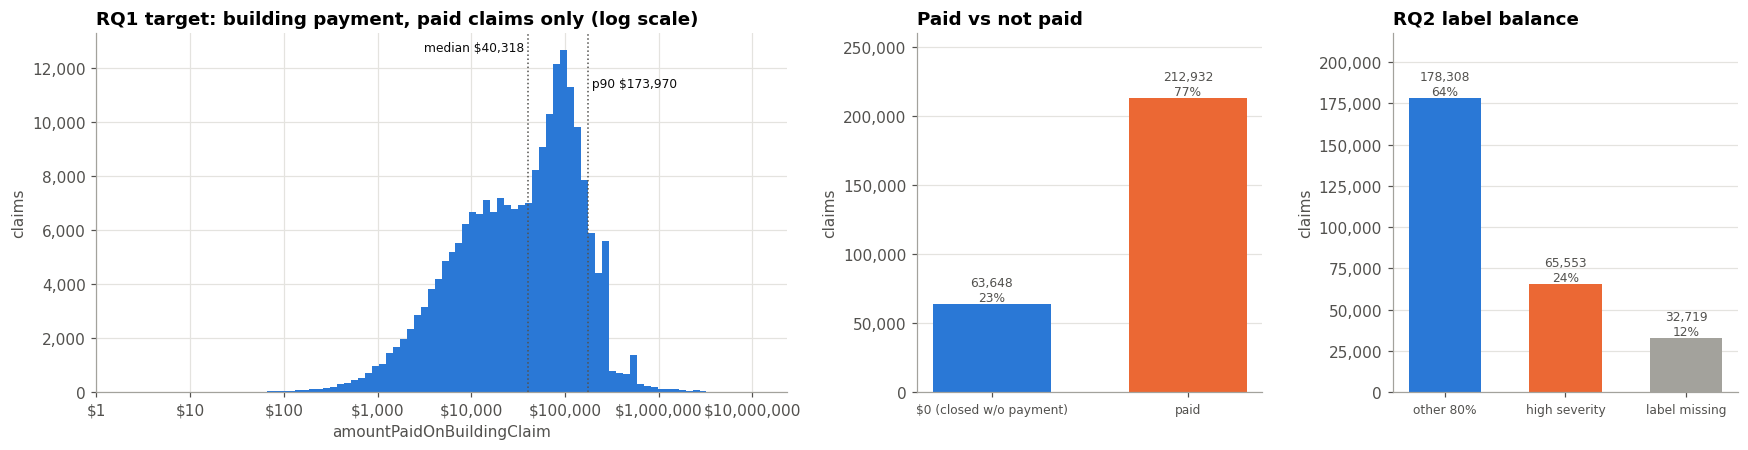

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.6, 0.8, 0.8]})
pos = clean.loc[clean["amountPaidOnBuildingClaim"] > 0, "amountPaidOnBuildingClaim"]
ax[0].hist(np.log10(pos), bins=90, color=C[0])
for q, lab, yf, ha in [(0.5, "median", 0.95, "right"), (0.9, "p90", 0.85, "left")]:
    v = pos.quantile(q); ax[0].axvline(np.log10(v), color=INK2, ls=":", lw=1)
    ax[0].text(np.log10(v), ax[0].get_ylim()[1] * yf, f" {lab} ${v:,.0f} ", fontsize=8, color=INK, ha=ha)
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${10**v:,.0f}"))
ax[0].set(title="RQ1 target: building payment, paid claims only (log scale)", xlabel="amountPaidOnBuildingClaim", ylabel="claims")
ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

for a, col, labs, title in [(ax[1], "is_paid", ["$0 (closed w/o payment)", "paid"], "Paid vs not paid"),
                             (ax[2], "high_severity", ["other 80%", "high severity"], "RQ2 label balance")]:
    vc = clean[col].value_counts(dropna=False).sort_index()
    names = [labs[0], labs[1]] + (["label missing"] if vc.index.isna().any() else [])
    vals = [vc.get(0, 0), vc.get(1, 0)] + ([vc[vc.index.isna()].sum()] if vc.index.isna().any() else [])
    a.bar(names, vals, color=[C[0], C[1], GRAY][:len(vals)], width=0.6)
    for i, v in enumerate(vals): a.text(i, v, f"{v:,}\n{v/sum(vals):.0%}", ha="center", va="bottom", fontsize=8, color=INK2)
    a.set(title=title, ylabel="claims"); a.set_ylim(0, max(vals) * 1.22); a.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}")); a.tick_params(axis="x", labelsize=8); a.grid(axis="x", visible=False)
plt.tight_layout(); savefig("10_targets_balance"); plt.show()

* Paid building claims span **five orders of magnitude**, from about $100 to over $1M. Model `log1p(payment)` and evaluate in dollars.
* About 1 in 4 claims closes with **$0**. RQ1 is therefore a "zero-inflated" problem: a two-part (paid? → how much?) model or a Tweedie loss is worth trying.
* RQ2 is **imbalanced by construction**: 20/80 in the training years, where the threshold is set. In the 2024–25 test years 36% of labelled claims clear the same threshold (the right panel pools both periods). Use stratified splits, class weights, and PR-AUC/F1 read against each period's base rate, not accuracy. About 12% of claims have no usable damage figure (blank or a $1 placeholder) and drop out of RQ2.

### 10.2 When do claims happen? (interval: time)

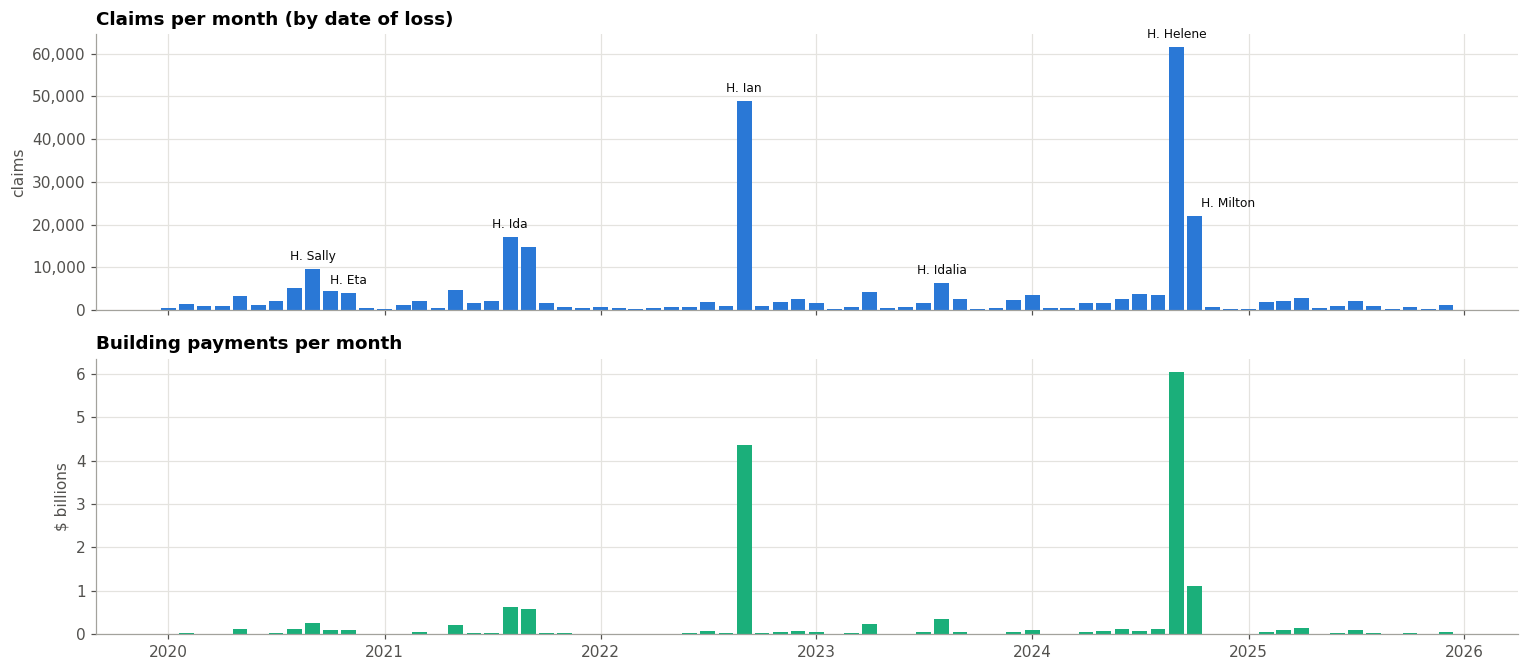

named catastrophe events: 80% of claims, 92% of building dollars paid


In [31]:
m = clean.set_index("dateOfLoss").resample("MS").agg(claims=("id", "size"), paid=("amountPaidOnBuildingClaim", "sum"))
fig, ax = plt.subplots(2, 1, figsize=(14, 6.2), sharex=True)
ax[0].bar(m.index, m["claims"], width=25, color=C[0])
ax[1].bar(m.index, m["paid"] / 1e9, width=25, color=C[2])
top_ev = (clean[clean["is_named_event"] == 1].groupby("floodEvent")
          .agg(claims=("id", "size"), d=("dateOfLoss", "median")).sort_values("claims", ascending=False).head(7))
for name, r in top_ev.iterrows():
    mm = r["d"].to_period("M").to_timestamp()
    lab = name.replace("Hurricane ", "H. ").replace("Tropical Storm ", "TS ")
    ax[0].annotate(lab, xy=(mm, m.loc[mm, "claims"]), xytext=(22 if lab == "H. Milton" else 0, 6), textcoords="offset points",
                   ha="center", fontsize=8, color=INK)
ax[0].set(title="Claims per month (by date of loss)", ylabel="claims")
ax[1].set(title="Building payments per month", ylabel="$ billions")
ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); savefig("10_claims_over_time"); plt.show()

share = clean.groupby("is_named_event")["amountPaidOnBuildingClaim"].sum() / clean["amountPaidOnBuildingClaim"].sum()
print(f"named catastrophe events: {clean['is_named_event'].mean():.0%} of claims, {share.get(1, 0):.0%} of building dollars paid")

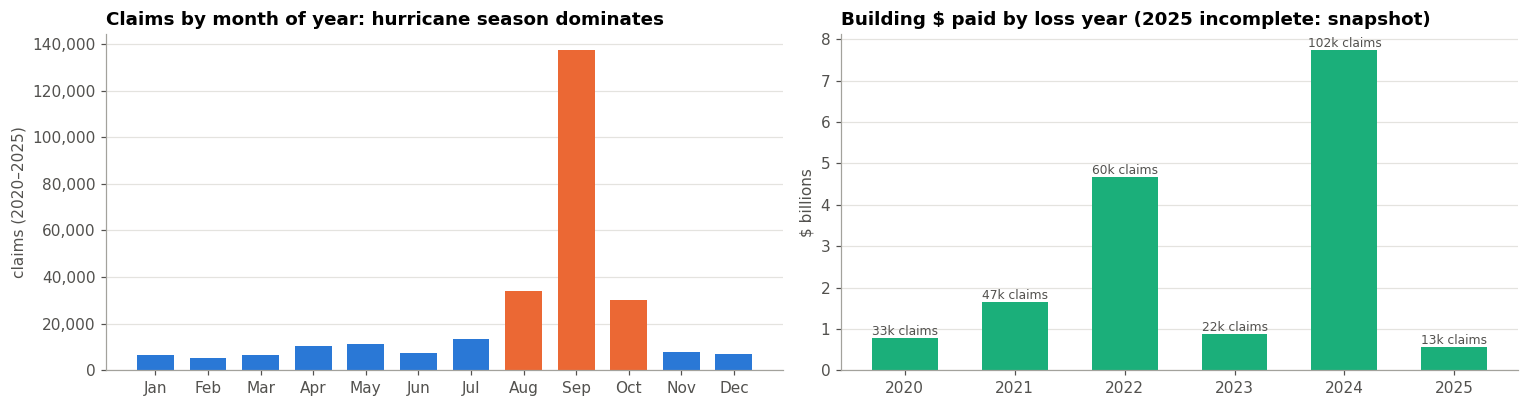

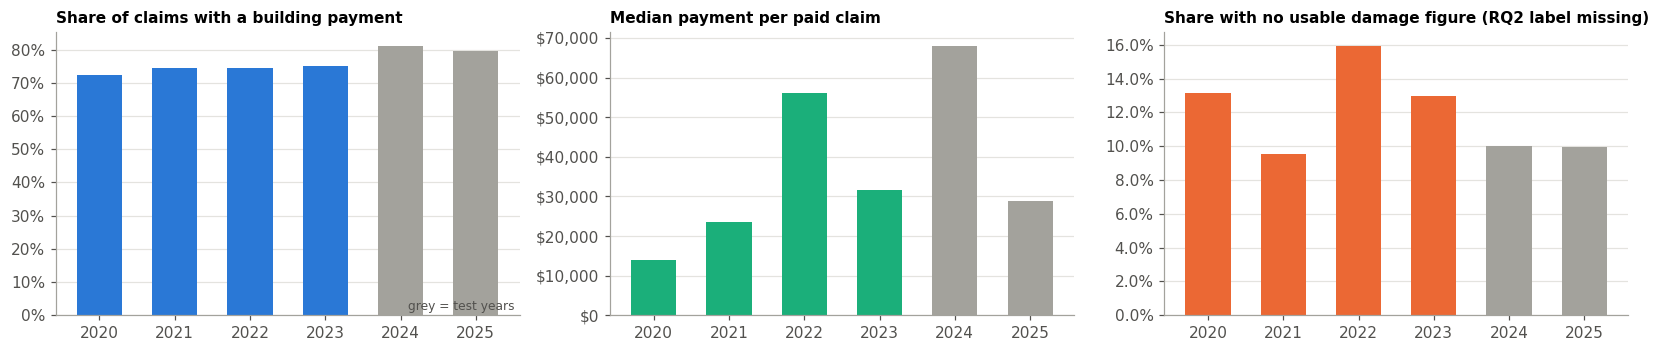

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
mon = clean.groupby("loss_month").agg(claims=("id", "size"), med=("amountPaidOnBuildingClaim", lambda s: s[s > 0].median()))
mn = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax[0].bar(mn, mon["claims"], color=[C[1] if i in (8, 9, 10) else C[0] for i in mon.index], width=0.7)
ax[0].set(title="Claims by month of year: hurricane season dominates", ylabel="claims (2020–2025)"); ax[0].grid(axis="x", visible=False)
ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
yr = clean.groupby("yearOfLoss").agg(claims=("id", "size"), paid=("amountPaidOnBuildingClaim", "sum"))
ax[1].bar(yr.index.astype(str), yr["paid"] / 1e9, color=C[2], width=0.6)
for i, (cl, p) in enumerate(zip(yr["claims"], yr["paid"])): ax[1].text(i, p / 1e9, f"{cl/1e3:.0f}k claims", ha="center", va="bottom", fontsize=8, color=INK2)
ax[1].set(title="Building $ paid by loss year (2025 incomplete: snapshot)", ylabel="$ billions"); ax[1].grid(axis="x", visible=False)
plt.tight_layout(); savefig("10_seasonality_years"); plt.show()

py = clean.groupby("yearOfLoss").agg(paid_share=("is_paid", "mean"), med=("amountPaidOnBuildingClaim", lambda s: s[s > 0].median()),
                                     dmg_missing=("buildingDamageAmount", lambda s: s.isna().mean()))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.3))
for a, col, colr, title, fmt in [(ax[0], "paid_share", C[0], "Share of claims with a building payment", mtick.PercentFormatter(1)),
                                 (ax[1], "med", C[2], "Median payment per paid claim", mtick.StrMethodFormatter("${x:,.0f}")),
                                 (ax[2], "dmg_missing", C[1], "Share with no usable damage figure (RQ2 label missing)", mtick.PercentFormatter(1))]:
    a.bar(py.index.astype(str), py[col], color=[colr if y <= TRAIN_MAX_YEAR else GRAY for y in py.index], width=0.6)
    a.yaxis.set_major_formatter(fmt); a.set_title(title, fontsize=10); a.grid(axis="x", visible=False)
ax[0].text(0.99, 0.02, "grey = test years", transform=ax[0].transAxes, ha="right", fontsize=8, color=INK2)
plt.tight_layout(); savefig("10_paid_by_year"); plt.show()

Claims are **event-driven**: a few hurricanes (Ida 2021, Ian 2022, Helene and Milton 2024) produce most of the volume and the dollars. Two consequences follow for modeling. (1) A random train/test split puts claims from the *same storm* on both sides, which inflates scores. A **grouped (by event) or time-based split** is more honest. (2) Year-to-year totals mostly reflect *which storms hit*, not a trend.

### 10.3 Where do claims happen? (nominal geography + interval coordinates)

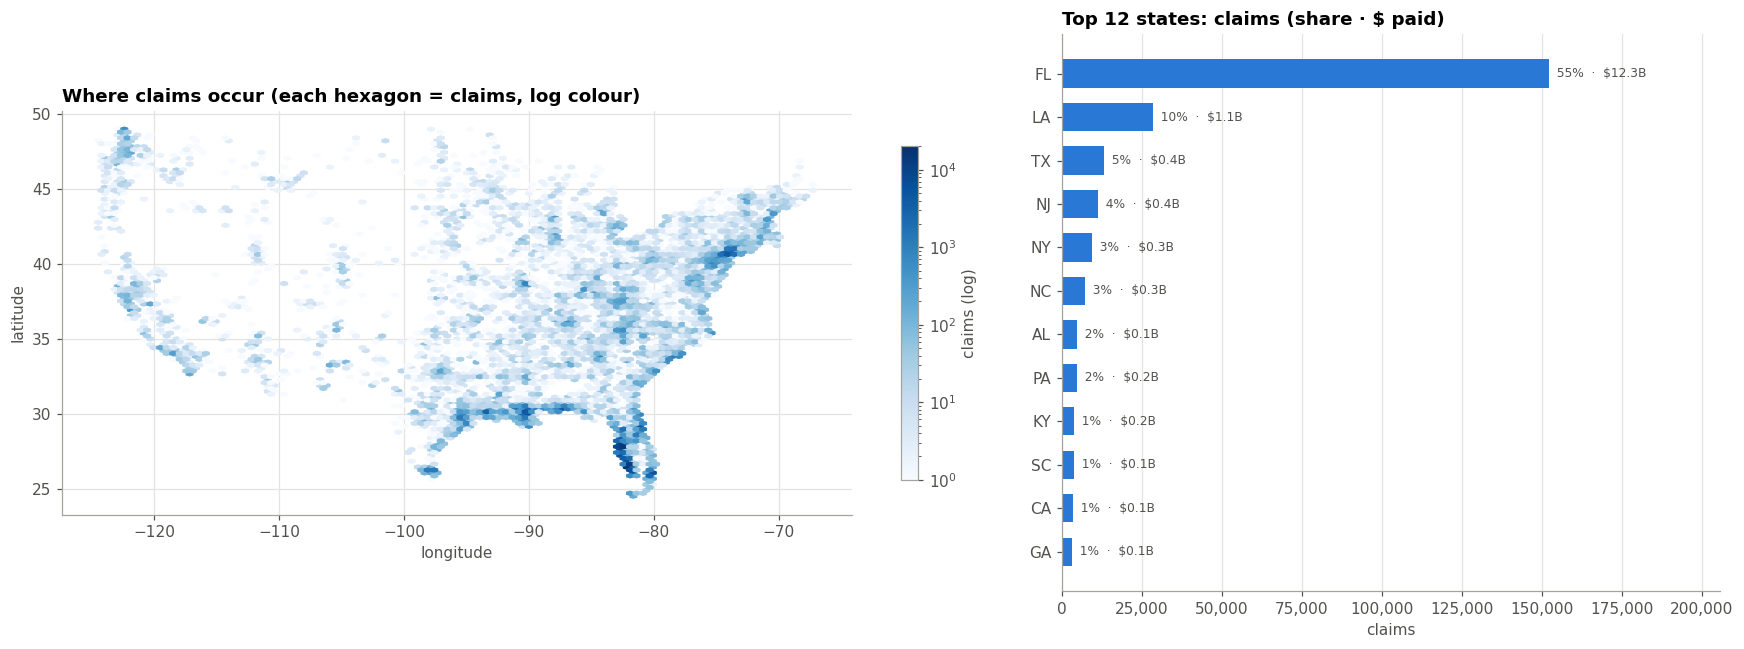

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})
g = clean[clean["longitude"].between(-125, -65) & clean["latitude"].between(24, 50)]
hb = ax[0].hexbin(g["longitude"], g["latitude"], gridsize=110, bins="log", cmap="Blues", mincnt=1)
ax[0].set(title="Where claims occur (each hexagon = claims, log colour)", xlabel="longitude", ylabel="latitude"); ax[0].set_aspect(1.2)
plt.colorbar(hb, ax=ax[0], shrink=0.6, label="claims (log)")
st = clean.groupby("state").agg(claims=("id", "size"), paid=("amountPaidOnBuildingClaim", "sum")).sort_values("claims", ascending=False).head(12)
y = np.arange(len(st))[::-1]
ax[1].barh(y, st["claims"], color=C[0], height=0.65)
for yi, (cl, p) in zip(y, zip(st["claims"], st["paid"])):
    ax[1].text(cl, yi, f"  {cl/len(clean):.0%}  ·  ${p/1e9:.1f}B", va="center", fontsize=8, color=INK2)
ax[1].set_yticks(y); ax[1].set_yticklabels(st.index); ax[1].set_xlim(0, st["claims"].max() * 1.35)
ax[1].set(title="Top 12 states: claims (share · $ paid)", xlabel="claims"); ax[1].grid(axis="y", visible=False)
ax[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); savefig("10_geography"); plt.show()

**Florida alone is over half the claims.** The other states with large shares are the Gulf and Atlantic coasts (LA, TX, NJ, NY, NC). For encoding, `state` keeps the top 15 levels and groups the rest as "OTHER" (Section 11). Any national model is, in practice, mostly a Florida model, which is a limitation to report.

### 10.4 Which named events cost the most? (nominal)

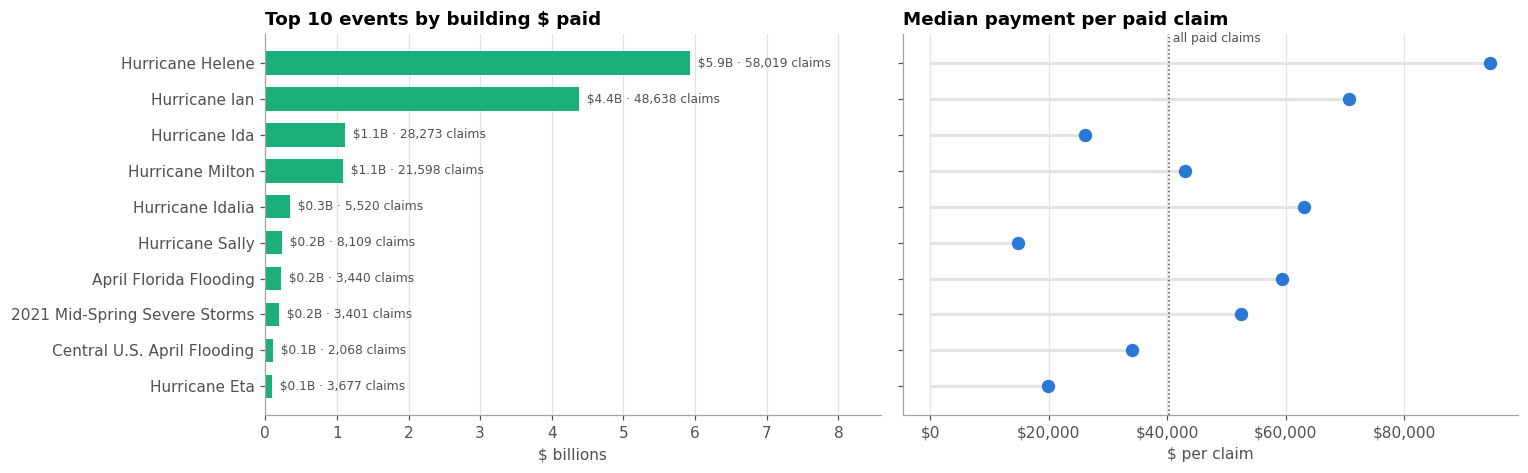

In [34]:
ev = (clean[clean["is_named_event"] == 1].groupby("floodEvent")
        .agg(claims=("id", "size"), paid=("amountPaidOnBuildingClaim", "sum"),
             med=("amountPaidOnBuildingClaim", lambda s: s[s > 0].median()))
        .sort_values("paid", ascending=False).head(10))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
y = np.arange(len(ev))[::-1]
ax[0].barh(y, ev["paid"] / 1e9, color=C[2], height=0.65)
for yi, (p, cl) in zip(y, zip(ev["paid"], ev["claims"])): ax[0].text(p / 1e9, yi, f"  ${p/1e9:.1f}B · {cl:,} claims", va="center", fontsize=8, color=INK2)
ax[0].set_yticks(y); ax[0].set_yticklabels(ev.index); ax[0].set_xlim(0, ev["paid"].max() / 1e9 * 1.45)
ax[0].set(title="Top 10 events by building $ paid", xlabel="$ billions"); ax[0].grid(axis="y", visible=False)
ax[1].scatter(ev["med"], y, color=C[0], s=60, zorder=3); ax[1].hlines(y, 0, ev["med"], color=GRID, lw=2)
ax[1].axvline(pos.median(), color=INK2, ls=":", lw=1); ax[1].text(pos.median(), len(ev) - 0.4, " all paid claims", fontsize=8, color=INK2)
ax[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[1].set(title="Median payment per paid claim", xlabel="$ per claim"); ax[1].grid(axis="y", visible=False)
plt.tight_layout(); savefig("10_events"); plt.show()

### 10.5 Flood zone, foundation and occupancy vs payment (nominal → ratio)
Box plots use a log axis, and each box is annotated with its paid rate. Severity is the median (inside the box) and frequency is the paid rate.

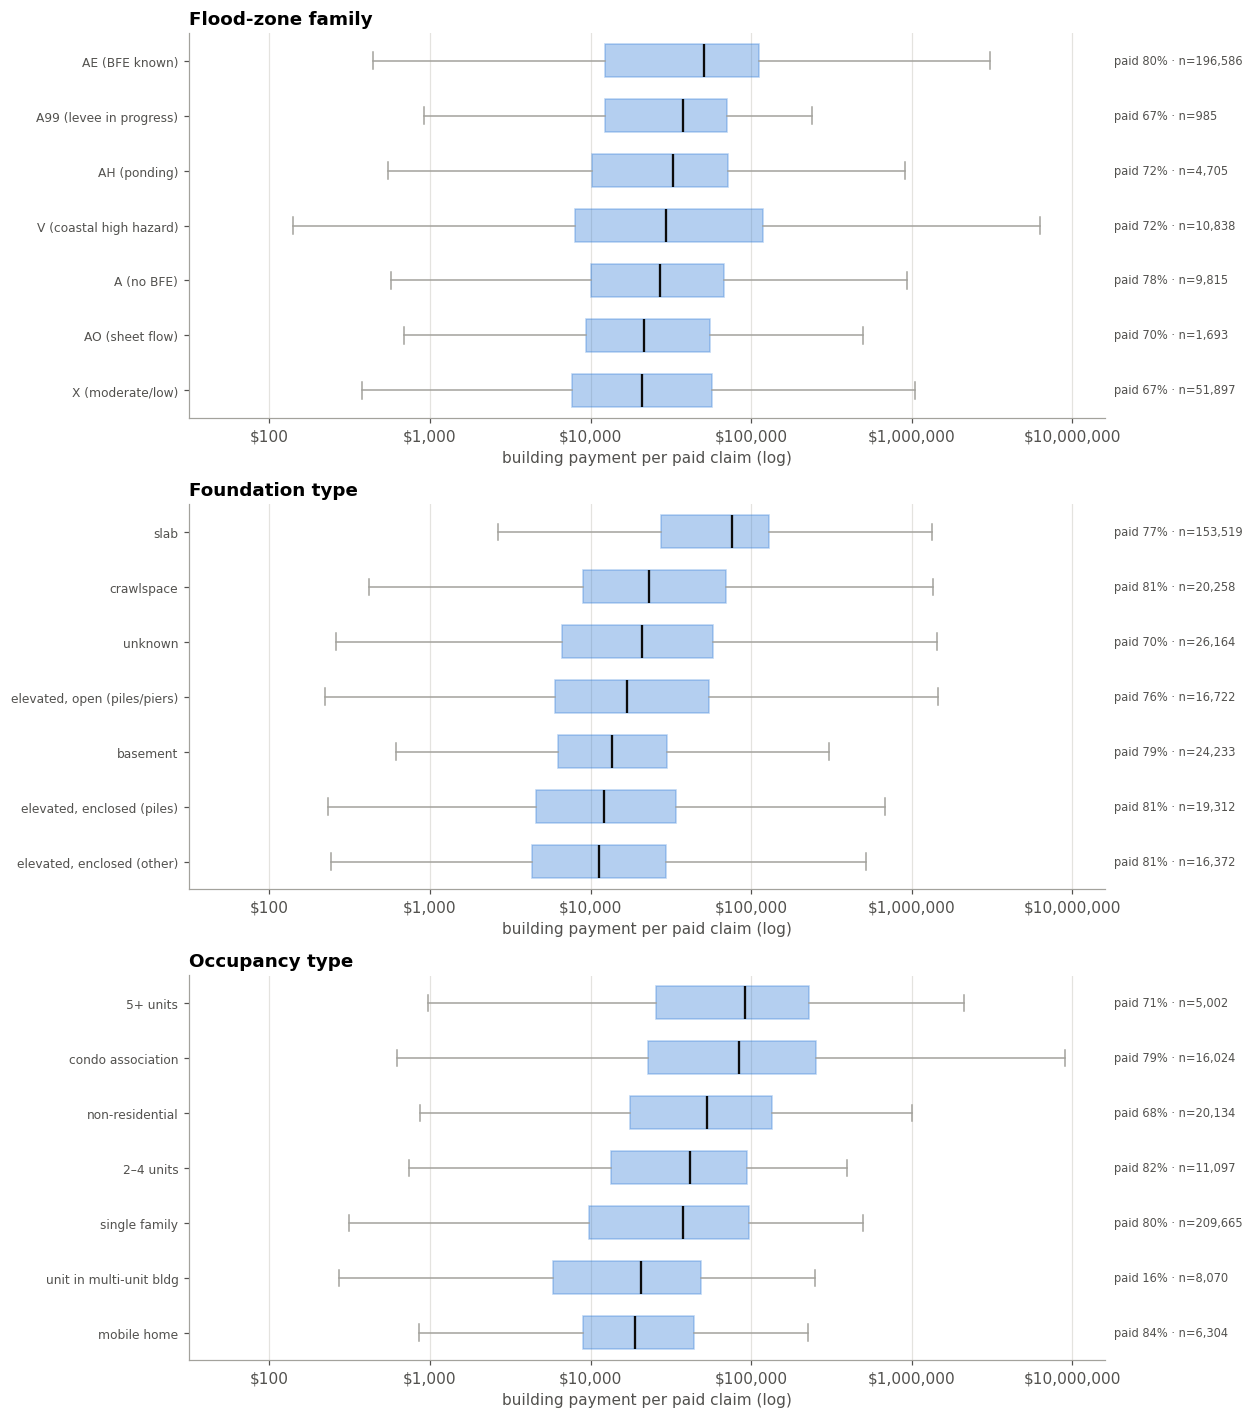

In [35]:
def box_by(ax, col, order=None, min_n=500, title=""):
    d = clean[clean["amountPaidOnBuildingClaim"] > 0]
    counts = clean[col].value_counts()
    keep = counts[counts >= min_n].index
    if order is None:
        order = d[d[col].isin(keep)].groupby(col)["amountPaidOnBuildingClaim"].median().sort_values(ascending=False).index.tolist()
    data = [np.log10(d.loc[d[col] == k, "amountPaidOnBuildingClaim"]) for k in order]
    bp = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY))
    for b in bp["boxes"]: b.set(facecolor=C[0], alpha=0.35, edgecolor=C[0])
    ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order, fontsize=8)
    pr = clean.groupby(col)["is_paid"].mean()
    for i, k in enumerate(order, 1):
        ax.text(1.01, i, f"paid {pr[k]:.0%} · n={counts[k]:,}", va="center", fontsize=7.5, color=INK2, transform=ax.get_yaxis_transform())
    ax.set_xlim(1.5, 7.2); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${10**v:,.0f}"))
    ax.invert_yaxis(); ax.set(title=title, xlabel="building payment per paid claim (log)"); ax.grid(axis="y", visible=False)

fig, ax = plt.subplots(3, 1, figsize=(11.5, 13))
box_by(ax[0], "flood_zone_family", title="Flood-zone family")
box_by(ax[1], "foundation", title="Foundation type")
box_by(ax[2], "occupancy", title="Occupancy type")
plt.tight_layout(); savefig("10_nominal_vs_payment"); plt.show()

* **Flood zone.** AE claims have the highest median payment. V-zone (coastal high hazard) claims have the **widest** spread, with the largest extremes. X-zone claims (outside the mapped 100-year floodplain) are about 19% of claims, have the lowest paid rate (67%), and still reach six-figure payments. The map label shifts severity but does not decide it.
* **Foundation.** **Slab** buildings take by far the largest median payment: water enters the living area at grade. Elevated buildings take less, as expected. **Basement** buildings are low too, because NFIP building coverage in basements is limited to a short list of items, so the policy rules cap the payment. "unknown" (code 0, legacy-rated policies) sits in the middle, which supports keeping it as its own level.
* **Occupancy.** Buildings with 5+ units, condo associations and non-residential buildings carry the largest payments, because their coverage limits are larger (Section 8: payment ≤ coverage). **Units in multi-unit buildings** are paid only 16% of the time: the building itself is normally insured by the association's policy, so the unit-owner's building claim is usually $0.

### 10.6 Ordinal features: CRS class and number of floors

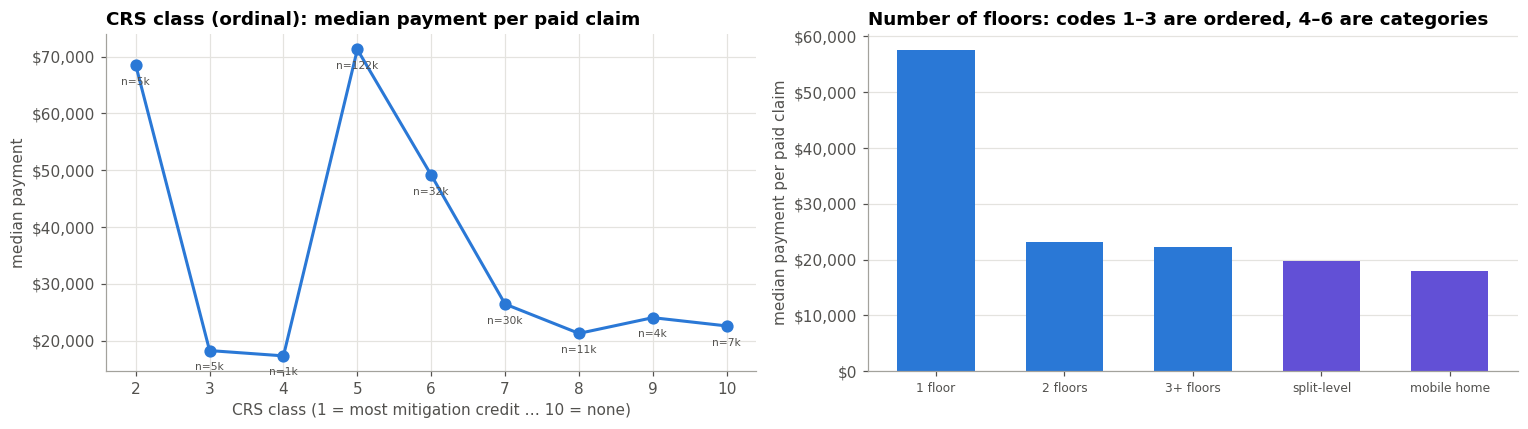

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
d = clean[clean["crs_unknown"] == 0]
crs = d.groupby(d["crsClassCode"].round()).agg(n=("id", "size"), med=("amountPaidOnBuildingClaim", lambda s: s[s > 0].median()),
                                               paid=("is_paid", "mean"))
crs = crs[crs["n"] >= 300]
ax[0].plot(crs.index, crs["med"], "-o", color=C[0], lw=2, ms=7)
for x, (v, n) in zip(crs.index, zip(crs["med"], crs["n"])): ax[0].text(x, v, f"\nn={n/1e3:.0f}k", ha="center", va="top", fontsize=7, color=INK2)
ax[0].set_xticks(crs.index); ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[0].set(title="CRS class (ordinal): median payment per paid claim", xlabel="CRS class (1 = most mitigation credit … 10 = none)", ylabel="median payment")
fl = {1: "1 floor", 2: "2 floors", 3: "3+ floors", 4: "split-level", 5: "mobile home", 6: "townhouse/rowhouse"}
f = clean.groupby("numberOfFloorsInTheInsuredBuilding").agg(n=("id", "size"), med=("amountPaidOnBuildingClaim", lambda s: s[s > 0].median()))
f = f[f["n"] >= 300]; f.index = [fl.get(int(i), str(i)) for i in f.index]
ax[1].bar(f.index, f["med"], color=[C[0]] * 3 + [C[6]] * (len(f) - 3), width=0.6)
ax[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}")); ax[1].grid(axis="x", visible=False)
ax[1].set(title="Number of floors: codes 1–3 are ordered, 4–6 are categories", ylabel="median payment per paid claim"); ax[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); savefig("10_ordinal"); plt.show()

**CRS class.** The relationship is not monotonic. Class 5–6 communities (class 5 alone is about 120k claims, many in Florida) see far larger median payments than class 8–10. CRS credit reflects community mitigation activity, and the communities that earn credit are often the *most exposed* ones. CRS class is therefore confounded with location: it is a risk *signal*, not evidence that mitigation increases losses. Encode it as **ordinal** (1–10) plus the `crs_unknown` flag.

**Number of floors.** One-floor buildings take more than twice the median payment of two-floor buildings, because the whole living area floods. The field mixes an ordered part (1 < 2 < 3+) with unordered building types (split-level, mobile home, townhouse), so it is encoded as **nominal** (one-hot), not as a number.

### 10.7 Ratio vs ratio: does deeper water mean bigger damage?

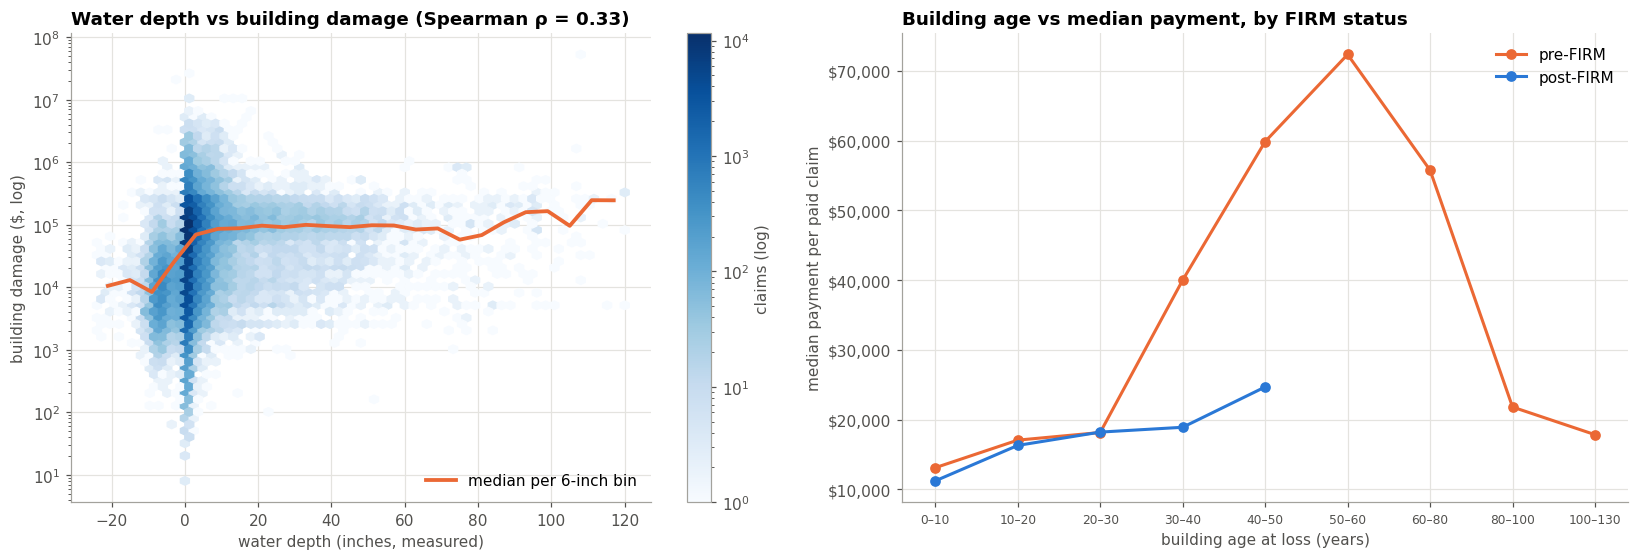

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
d = clean[(clean["waterDepth_missing"] == 0) & (clean["buildingDamageAmount"] > 0) & clean["waterDepth"].between(-24, 120)]
hb = ax[0].hexbin(d["waterDepth"], d["buildingDamageAmount"], gridsize=60, yscale="log", bins="log", cmap="Blues", mincnt=1)
bm = d.groupby(pd.cut(d["waterDepth"], np.arange(-24, 124, 6)), observed=True)["buildingDamageAmount"].median()
ax[0].plot([i.mid for i in bm.index], bm.values, color=C[1], lw=2.5, label="median per 6-inch bin")
rho = stats.spearmanr(d["waterDepth"], d["buildingDamageAmount"]).statistic
ax[0].set(title=f"Water depth vs building damage (Spearman ρ = {rho:.2f})", xlabel="water depth (inches, measured)", ylabel="building damage ($, log)")
ax[0].legend(loc="lower right"); plt.colorbar(hb, ax=ax[0], label="claims (log)")

d2 = clean[(clean["amountPaidOnBuildingClaim"] > 0)]
bins = [0, 10, 20, 30, 40, 50, 60, 80, 100, 130]
d2 = d2.assign(age_bin=pd.cut(d2["building_age"], bins), firm=np.where(d2["postFIRMConstructionIndicator"], "post-FIRM", "pre-FIRM"))
a = d2.groupby(["age_bin", "firm"], observed=True)["amountPaidOnBuildingClaim"].median().unstack()
n = d2.groupby(["age_bin", "firm"], observed=True).size().unstack()
a = a.where(n >= 300)
x = np.arange(len(a))
for k, colr in [("pre-FIRM", C[1]), ("post-FIRM", C[0])]:
    ax[1].plot(x, a[k], "-o", color=colr, lw=2, ms=6, label=k)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{int(i.left)}–{int(i.right)}" for i in a.index], fontsize=8)
ax[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[1].set(title="Building age vs median payment, by FIRM status", xlabel="building age at loss (years)", ylabel="median payment per paid claim")
ax[1].legend(); plt.tight_layout(); savefig("10_depth_age"); plt.show()

* The relationship is a **step, then a plateau**. Median damage jumps from about $10k at or below the lowest floor (depth ≤ 0) to about $80k once water is inside, and then barely rises between 6 and 50 inches. Overall Spearman ρ is only about 0.3. That non-linear shape is why tree models are preferred over linear ones. The noisy tail past 60 inches is consistent with FEMA's note that **some depths were entered in feet instead of inches**, a known unit-noise issue that the RQ3 anomaly check should revisit. Depth is post-loss, so it is used for RQ3 profiling, not RQ1/RQ2 prediction.
* Post-FIRM buildings are by definition younger (FIRMs date from the 1970s), so the comparison is only fair where ages overlap. In the 30–50-year range, **pre-FIRM** buildings (built before the community's first flood map) take clearly larger payments. That is a pre-loss signal RQ1 can use. The pre-FIRM peak at 50–60 years is also a location effect (older coastal stock in FL and LA), not age alone.

### 10.8 Associations: numeric (Spearman) and nominal (Cramér's V)

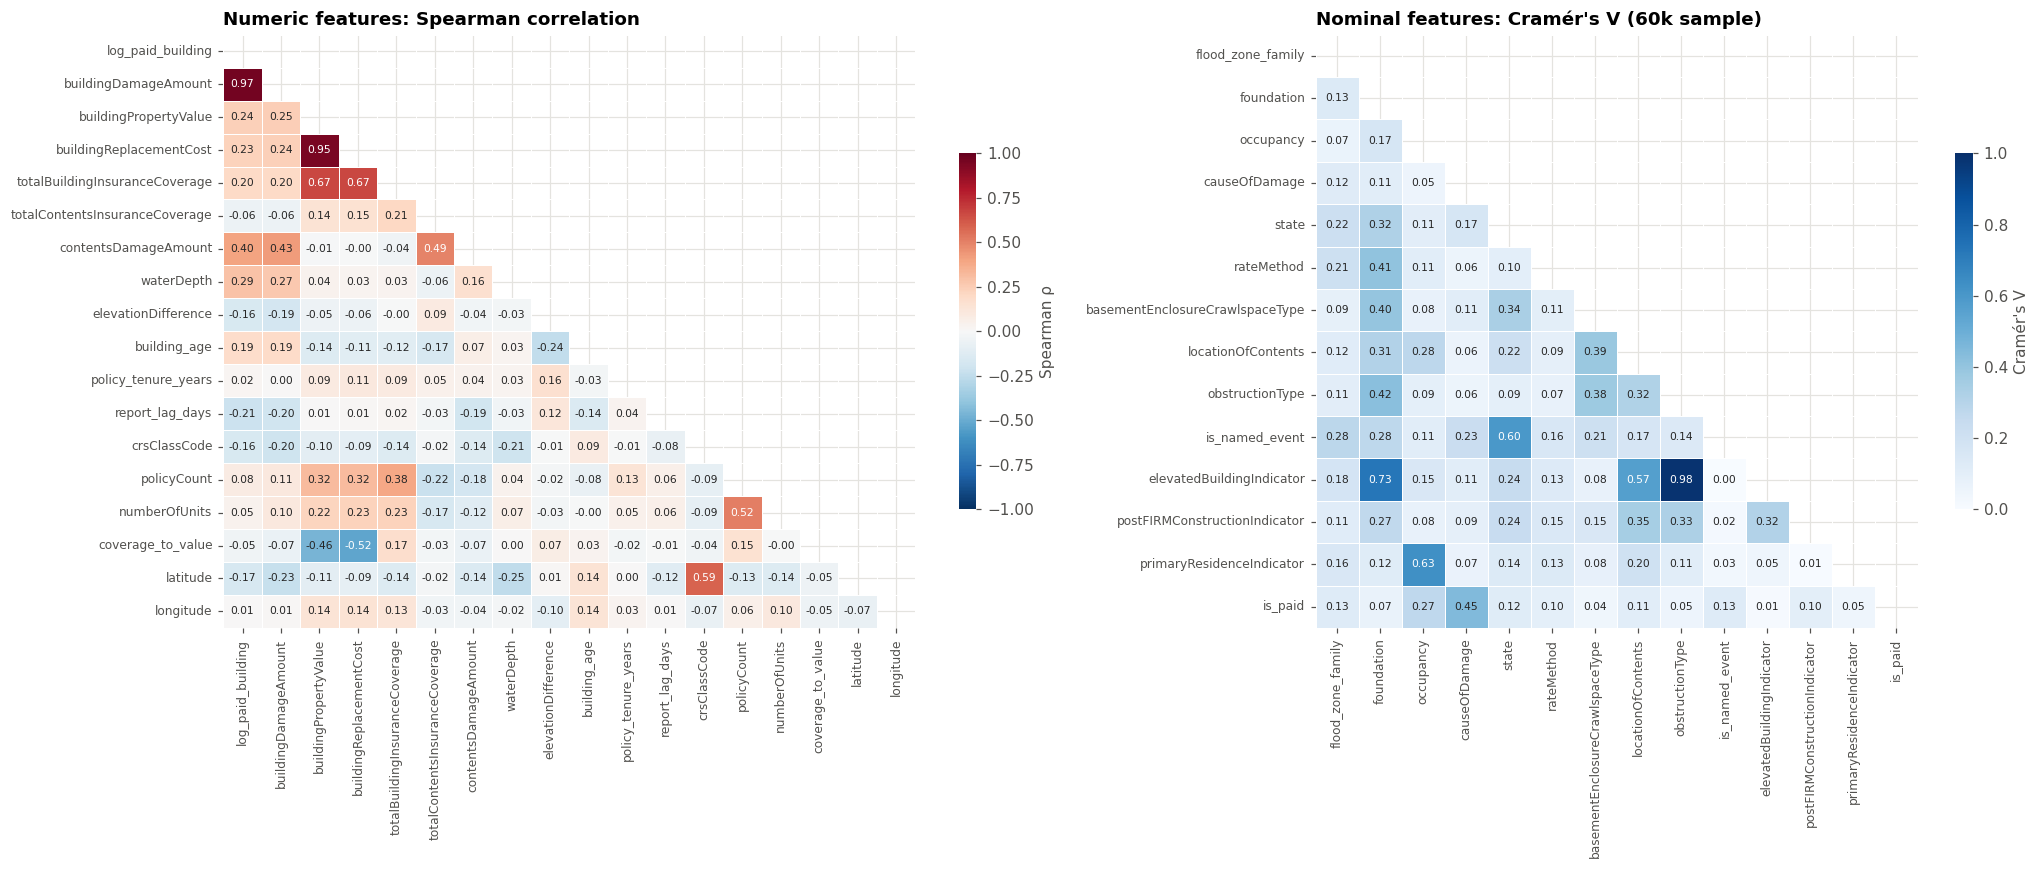

numeric pairs with |ρ| > 0.8 (redundancy candidates):
log_paid_building      buildingDamageAmount       0.969
buildingPropertyValue  buildingReplacementCost    0.951


In [38]:
num = ["log_paid_building", "buildingDamageAmount", "buildingPropertyValue", "buildingReplacementCost", "totalBuildingInsuranceCoverage",
       "totalContentsInsuranceCoverage", "contentsDamageAmount", "waterDepth", "elevationDifference", "building_age", "policy_tenure_years",
       "report_lag_days", "crsClassCode", "policyCount", "numberOfUnits", "coverage_to_value", "latitude", "longitude"]
corr = clean[num].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw={"width_ratios": [1.15, 1]})
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.6, "label": "Spearman ρ"}, ax=ax[0])
ax[0].set_title("Numeric features: Spearman correlation"); ax[0].tick_params(labelsize=8)

nom = ["flood_zone_family", "foundation", "occupancy", "causeOfDamage", "state", "rateMethod", "basementEnclosureCrawlspaceType",
       "locationOfContents", "obstructionType", "is_named_event", "elevatedBuildingIndicator", "postFIRMConstructionIndicator",
       "primaryResidenceIndicator", "is_paid"]
sub = clean[nom].sample(60000, random_state=SEED).astype(str)
cv = pd.DataFrame(np.eye(len(nom)), index=nom, columns=nom)
for i in range(len(nom)):
    for j in range(i + 1, len(nom)):
        cv.iloc[i, j] = cv.iloc[j, i] = cramers_v(sub[nom[i]], sub[nom[j]])[0]
sns.heatmap(cv, mask=np.triu(np.ones_like(cv, dtype=bool)), cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.6, "label": "Cramér's V"}, ax=ax[1])
ax[1].set_title("Nominal features: Cramér's V (60k sample)"); ax[1].tick_params(labelsize=8)
plt.tight_layout(); savefig("10_associations"); plt.show()

high = corr.where(np.triu(np.ones_like(corr, dtype=bool), 1)).stack().loc[lambda s: s.abs() > 0.8]
print("numeric pairs with |ρ| > 0.8 (redundancy candidates):"); print(high.round(3).to_string())

* **Leakage check.** `buildingDamageAmount` vs log building payment has ρ ≈ 0.97. The adjuster's damage figure is essentially the payment before deductible and limits, so it **must not be an RQ1 predictor**. It is also the definition of the RQ2 label.
* `buildingPropertyValue` and `buildingReplacementCost` are almost the same variable (ρ ≈ 0.94). Keep **one** of them for linear models and PCA, or PCA will weight that idea twice.
* Building coverage correlates only **weakly** with payment (ρ ≈ 0.2). Coverage sets the *ceiling* (Section 8) but does not drive the typical claim, which sits well below its limit. No single pre-loss numeric feature is strongly correlated with payment, so RQ1 should expect modest R² from pre-loss features alone and must report that honestly.
* `crsClassCode` vs latitude has ρ ≈ 0.6. CRS class is largely a **location proxy** (Florida communities hold classes 5–6), which supports the confounding note in 10.6.
* `elevatedBuildingIndicator` ↔ `obstructionType` (V ≈ 0.98) ↔ `foundation` (V ≈ 0.73) are redundant by design: obstruction type only exists for elevated buildings. One of them is enough for clustering.
* `causeOfDamage` ↔ `is_paid` (V ≈ 0.45) and `occupancy` ↔ `is_paid` (V ≈ 0.27) are the strongest categorical links to the outcome. `rateMethod` ↔ `foundation` (V ≈ 0.41) is the code-0 legacy effect from Section 4.

## 11. Encoding and scaling

### 11.1 Encoding: nominal and ordinal are handled differently
* **Nominal** (no order): **one-hot** encoding for low-cardinality columns. Rare levels (< 0.5% of rows) are grouped into "other" so the matrix does not explode. `state` keeps the top 15 + "OTHER". High-cardinality keys (county, ZIP) are **frequency-encoded** if used at all. Target encoding would leak unless it is fit inside CV folds.
* **Ordinal** (ordered): **integer codes that respect the order**. CRS class 1…10 stays numeric. Building *and contents* deductible codes are mapped to their **dollar amounts** ($0 where that coverage does not exist) (code "E" = $50,000 > "5" = $5,000). The raw code order would be wrong: alphabetical "A" < "9" puts $10,000 below $750.
* **Binary** flags → 0/1.

In [39]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer

NOMINAL = ["flood_zone_family", "foundation", "occupancy", "state_grp", "basementEnclosureCrawlspaceType", "locationOfContents",
           "obstructionType", "buildingDescriptionCode", "condominiumCoverageTypeCode", "rating_group", "numberOfFloorsInTheInsuredBuilding"]
ORDINAL = ["crsClassCode", "bldg_deductible_usd", "cont_deductible_usd"]
BINARY = ["elevatedBuildingIndicator", "postFIRMConstructionIndicator", "primaryResidenceIndicator", "rentalPropertyIndicator",
          "smallBusinessIndicatorBuilding", "nonProfitIndicator", "is_named_event", "is_rr2", "crs_unknown", "has_elevation_data",
          "bldg_deductible_unknown", "cont_deductible_unknown", "no_building_cov", "no_contents_cov", "construction_date_jan1",
          "bldg_age_invalid_or_missing", "tenure_invalid_or_missing"]
NUMERIC = ["totalBuildingInsuranceCoverage", "totalContentsInsuranceCoverage", "policyCount", "numberOfUnits", "building_age",
           "policy_tenure_years", "report_lag_days", "loss_month_sin", "loss_month_cos", "loss_dow", "latitude", "longitude", "county_freq"]
for col in NOMINAL: clean[col] = clean[col].astype(str)
for col in BINARY: clean[col] = clean[col].astype("int8")

enc = ColumnTransformer([
    ("nominal_onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), NOMINAL),
    ("ordinal_keep_order", "passthrough", ORDINAL),
    ("binary", "passthrough", BINARY),
    ("numeric", "passthrough", NUMERIC),
], verbose_feature_names_out=True)
enc.fit(clean.loc[TRAIN, NOMINAL + ORDINAL + BINARY + NUMERIC])          # categories learned from train years only
X_enc = enc.transform(clean[NOMINAL + ORDINAL + BINARY + NUMERIC])
print(f"pre-loss feature table: {len(NOMINAL + ORDINAL + BINARY + NUMERIC)} columns → {X_enc.shape[1]} after encoding")
pd.Series({k: sum(n.startswith(k) for n in enc.get_feature_names_out()) for k in ["nominal_onehot", "ordinal_keep_order", "binary", "numeric"]}).to_frame("encoded columns")

pre-loss feature table: 44 columns → 116 after encoding


,encoded columns
nominal_onehot,83
ordinal_keep_order,3
binary,17
numeric,13


### 11.2 Scaling: which scaler, and why
Scaling matters for **distance-based and variance-based methods** (k-means, KNN, PCA, regularised linear models). It does not matter for trees. Three scalers are compared on building coverage, a heavy-tailed column:

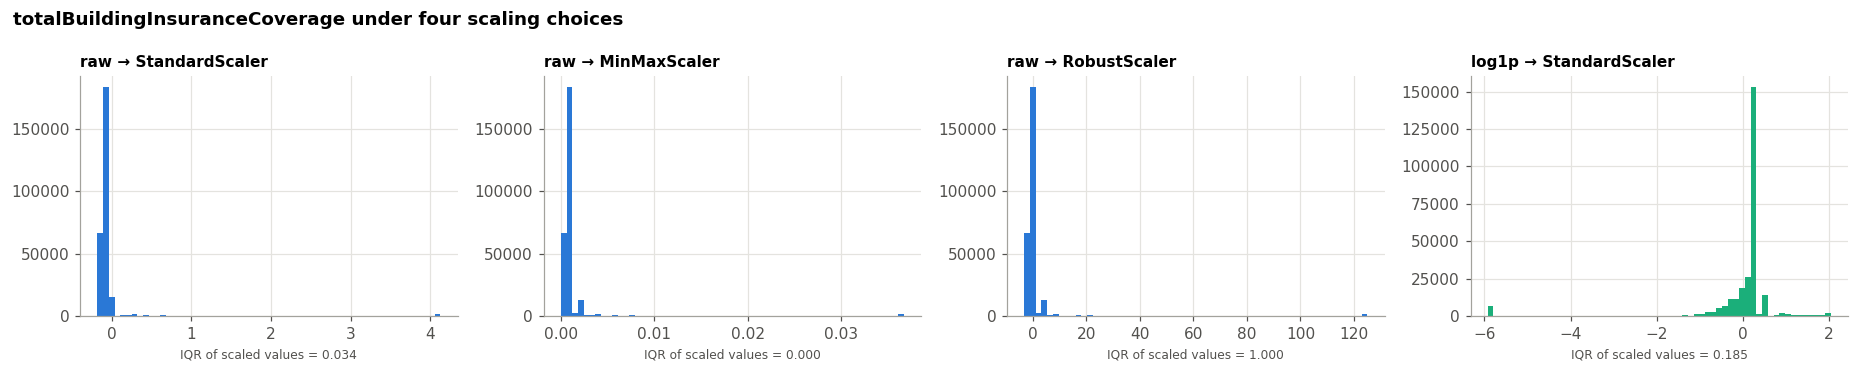

In [40]:
v = clean[["totalBuildingInsuranceCoverage"]].values
lv = np.log1p(v)
variants = {"raw → StandardScaler": StandardScaler().fit_transform(v), "raw → MinMaxScaler": MinMaxScaler().fit_transform(v),
            "raw → RobustScaler": RobustScaler().fit_transform(v), "log1p → StandardScaler": StandardScaler().fit_transform(lv)}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, (k, z) in zip(axes, variants.items()):
    z = z.ravel(); lo, hi = np.percentile(z, [0.5, 99.5])
    ax.hist(np.clip(z, lo, hi), bins=60, color=C[2] if k.startswith("log") else C[0])
    ax.set_title(k, fontsize=10); ax.set_xlabel(f"IQR of scaled values = {np.subtract(*np.percentile(z, [75, 25])):.3f}", fontsize=8)
fig.suptitle("totalBuildingInsuranceCoverage under four scaling choices", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); savefig("11_scalers"); plt.show()

(The spike at −6 in the last panel is the contents-only policies with $0 building coverage, which the `no_building_cov` level already identifies. The spike near 0 is the $250k limit.)

* **MinMaxScaler** is dominated by the maximum (a $28M commercial policy). It squeezes 99% of claims into a sliver near 0, so distances become meaningless.
* **StandardScaler on raw dollars** has the same problem through the mean and SD, which the tail drags.
* **RobustScaler** (median/IQR) resists the tail, but leaves the skew in place.
* **Chosen: `log1p` → `StandardScaler`** for all dollar and count columns. The log removes the skew (Section 8) and standardising gives each feature unit variance, which **PCA and k-means need** so that no feature dominates by its units. **RobustScaler** is the fallback for unlogged columns with residual outliers (water depth, report lag). Tree models (RQ1/RQ2 gradient boosting, random forest) use **unscaled** features. As with imputation, scalers are **fit on the training split only**.

In [41]:
LOG_COLS = ["totalBuildingInsuranceCoverage", "totalContentsInsuranceCoverage", "policyCount", "numberOfUnits"]
scaled = clean[NUMERIC + ORDINAL].copy()
scaled[LOG_COLS] = clean[["log_bldg_coverage", "log_cont_coverage", "log_policy_count", "log_num_units"]].values   # winsorised log1p
scaler = StandardScaler().fit(scaled[TRAIN])                                   # fit on train years only
scaled_std = pd.DataFrame(scaler.transform(scaled), columns=scaled.columns)
print("mean / SD of scaled TEST rows (not exactly 0 / 1, because the scaler never saw them):")
scaled_std[~TRAIN].describe().T[["mean", "std", "min", "max"]].round(2)

mean / SD of scaled TEST rows (not exactly 0 / 1, because the scaler never saw them):


,mean,std,min,max
totalBuildingInsuranceCoverage,0.03,1.01,-5.94,2.61
totalContentsInsuranceCoverage,-0.12,1.04,-1.61,1.05
policyCount,0.06,1.14,-0.17,10.74
numberOfUnits,0.15,0.98,-1.32,7.74
building_age,0.25,0.89,-1.96,5.66
policy_tenure_years,0.01,1.13,-1.19,7.09
report_lag_days,-0.07,0.83,-0.35,8.99
loss_month_sin,-0.12,0.96,-0.64,2.57
loss_month_cos,0.27,0.89,-1.82,2.24
loss_dow,0.10,0.72,-1.58,1.91


## 12. Shape before and after, decision log, and saved outputs

In [42]:
clean["leak_log_net_bldg_payment"] = np.log1p(clean["netBuildingPaymentAmount"].clip(lower=0))
clean["leak_log_net_cont_payment"] = np.log1p(clean["netContentsPaymentAmount"].clip(lower=0))
clean["leak_nonpay_reason_building_present"] = df["nonPaymentReasonBuilding"].notna().astype("int8").values
clean["leak_nonpay_reason_contents_present"] = df["nonPaymentReasonContents"].notna().astype("int8").values
clean["leak_has_payment_date"] = df["mostRecentPaymentDate"].notna().astype("int8").values

FEATURES_PRELOSS = NOMINAL + ORDINAL + BINARY + NUMERIC
LOG_FEATURES = ["log_bldg_coverage", "log_cont_coverage", "log_policy_count", "log_num_units"]
TARGETS = ["amountPaidOnBuildingClaim", "log_paid_building", "is_paid", "buildingDamageAmount", "high_severity"]
POSTLOSS_EDA = ["waterDepth", "interiorWaterDepth", "exteriorWaterDepth", "waterDepth_w", "interiorWaterDepth_w", "exteriorWaterDepth_w",
                "buildingPropertyValue", "buildingReplacementCost", "contentsDamageAmount", "contentsPropertyValue",
                "log_bldg_value", "log_repl_cost", "log_bldg_damage", "log_cont_damage",
                "causeOfDamage", "cause_group", "replacementCostBasis", "elevationDifference", "coverage_to_value", "damage_to_value_ratio",
                "waterDepth_missing", "interiorWaterDepth_missing", "exteriorWaterDepth_missing", "buildingPropertyValue_missing",
                "buildingReplacementCost_missing", "contentsDamageAmount_missing", "paid_exceeds_coverage", "damage_exceeds_value",
                "net_payment_exceeds_damage"]
LEAKAGE = ["leak_log_net_bldg_payment", "leak_log_net_cont_payment", "leak_nonpay_reason_building_present",
           "leak_nonpay_reason_contents_present", "leak_has_payment_date"]
KEYS = ["id", "dateOfLoss", "yearOfLoss", "is_train", "floodEvent", "flood_event_grp", "state", "countyCode", "nfipRatedCommunityNumber"]
final = clean[KEYS + FEATURES_PRELOSS + LOG_FEATURES + POSTLOSS_EDA + LEAKAGE + TARGETS].copy()
feature_lists = {"keys": KEYS, "nominal": NOMINAL, "ordinal": ORDINAL, "binary": BINARY, "numeric": NUMERIC, "log_features": LOG_FEATURES,
                 "postloss": POSTLOSS_EDA, "leakage": LEAKAGE, "targets": TARGETS, "train_max_year": TRAIN_MAX_YEAR,
                 "high_severity_threshold_usd": float(thr)}
(OUT_DIR / "feature_lists.json").write_text(json.dumps(feature_lists, indent=2))

shape_tbl = pd.DataFrame({
    "rows": [f"{len(raw):,}", f"{len(df):,}", f"{len(final):,}", f"{len(final):,}"],
    "columns": [raw.shape[1], df.shape[1], final.shape[1], X_enc.shape[1]],
    "note": ["raw 2020–2025 extract", "after sentinel recoding + de-duplication", "cleaned table (keys + pre-loss features + post-loss + leakage demo + targets)",
             "pre-loss feature matrix after one-hot encoding"]},
    index=["1. raw", "2. recoded + de-duplicated", "3. cleaned table", "4. encoded features"])
display(shape_tbl)
miss_left = final[FEATURES_PRELOSS].isna().sum().sum()
print(f"missing cells left in pre-loss features: {miss_left}  |  RQ2 rows with a label: {final['high_severity'].notna().sum():,}")

,rows,columns,note
1. raw,"277,033",84,raw 2020–2025 extract
2. recoded + de-duplicated,"276,580",84,after sentinel recoding + de-duplication
3. cleaned table,"276,580",96,cleaned table (keys + pre-loss features + post-loss + leakage demo + targets)
4. encoded features,"276,580",116,pre-loss feature matrix after one-hot encoding


missing cells left in pre-loss features: 0  |  RQ2 rows with a label: 243,861


In [43]:
decisions = pd.DataFrame([
    ("Time split", "all rows", "train = 2020–2023, test = 2024–2025; every fill, cap, threshold, encoder and scaler fit on train", "no test-year information in training features", "2024–25 storms never inform the fills"),
    ("Disguised missing", "waterDepth=99, depths≥999, elevations≥9000 (elev. difference ≥500), $0 building value with coverage, $1 damage, -1 contents value, placeholder dates", "→ NaN", "they are codes, not measurements", "none (they were never real values)"),
    ("Duplicates", "453 rows identical on all 83 non-key fields", "drop extra copies", "same claim keyed twice; avoids train/test leakage", "≤ 453 possibly real claims"),
    ("Drop", "41 columns (empty, constant, sparse, IDs, redundant, leakage, location proxies)", "remove from features", "rules R1–R7, Section 6", "absolute elevations for a subset"),
    ("Structural zero", "amountPaidOn*, contents damage/value without contents cover", "fill 0", "blank means $0 by definition", "nothing"),
    ("Explicit level", "obstruction, basement, contents location, building description, cause, deductibles, floodEvent", "'not_applicable' / 'unknown'", "MCAR rejected; missingness is informative", "extra dummy columns"),
    ("Lookup", "crsClassCode", "same community's CRS class", "CRS class is a community attribute", "nothing (true value)"),
    ("Mode / median", "condo type, cost basis, floors, zone; numberOfUnits", "mode / median", "<1% missing, MCAR-plausible", "negligible"),
    ("Spatial fill", "latitude, longitude", "county mean → state mean", "location ≈ its county", "~0.1° precision"),
    ("Adjuster block + flag", "water depths, building value / replacement cost", "method per column chosen by joint masking (7.3)", "columns go missing together", "imputed spread narrower than observed"),
    ("Not imputed", "buildingDamageAmount (RQ2 label), elevationDifference", "leave NaN + flag", "never impute a label; 66% too sparse", "11% of rows leave RQ2"),
    ("Noise", "negative payments, construction after loss / before 1850, NB date after loss / before 1968, open before loss", "clip / → NaN (+ flags)", "impossible by definition", "a few thousand rows' dates"),
    ("Outliers", "dollar fields, depths", "keep; log1p winsorised at train p99.9 (log_*); depths clipped at train p1/p99.5 (*_w)", "extremes are real and important", "linear-scale interpretability"),
    ("Encoding", "nominal vs ordinal", "one-hot (rare→other) vs ordered ints / $ amounts", "order exists only for ordinal", "rare-level detail"),
    ("Scaling", "dollar & count columns", "log1p → StandardScaler (Robust fallback)", "PCA/k-means need comparable variance", "none for trees (unscaled)"),
], columns=["step", "applied to", "action", "why", "what we give up"])
decisions.to_csv(OUT_DIR / "preprocessing_decisions.csv", index=False)
mech.to_csv(OUT_DIR / "missingness_by_column.csv"); imp_log.to_csv(OUT_DIR / "imputation_log.csv", index=False)
drop_tbl.to_csv(OUT_DIR / "dropped_columns.csv", index=False); attr.to_csv(OUT_DIR / "attribute_types.csv")
noise.to_csv(OUT_DIR / "noise_checks.csv"); joint.to_csv(OUT_DIR / "imputation_joint_masking.csv")
final.to_parquet(OUT_DIR / "nfip_claims_2020_2025_eda_clean.parquet", index=False)
print("saved to", OUT_DIR)
decisions

saved to /Users/home/workspace/School/DataMining/nfip_claims_project/notebooks/outputs


,step,applied to,action,why,what we give up
0,Time split,all rows,"train = 2020–2023, test = 2024–2025; every fill, cap, threshold, encoder and scaler fit on train",no test-year information in training features,2024–25 storms never inform the fills
1,Disguised missing,"waterDepth=99, depths≥999, elevations≥9000 (elev. difference ≥500), $0 building value with coverage, $1 damage, -1 c...",→ NaN,"they are codes, not measurements",none (they were never real values)
2,Duplicates,453 rows identical on all 83 non-key fields,drop extra copies,same claim keyed twice; avoids train/test leakage,≤ 453 possibly real claims
3,Drop,"41 columns (empty, constant, sparse, IDs, redundant, leakage, location proxies)",remove from features,"rules R1–R7, Section 6",absolute elevations for a subset
4,Structural zero,"amountPaidOn*, contents damage/value without contents cover",fill 0,blank means $0 by definition,nothing
5,Explicit level,"obstruction, basement, contents location, building description, cause, deductibles, floodEvent",'not_applicable' / 'unknown',MCAR rejected; missingness is informative,extra dummy columns
6,Lookup,crsClassCode,same community's CRS class,CRS class is a community attribute,nothing (true value)
7,Mode / median,"condo type, cost basis, floors, zone; numberOfUnits",mode / median,"<1% missing, MCAR-plausible",negligible
8,Spatial fill,"latitude, longitude",county mean → state mean,location ≈ its county,~0.1° precision
9,Adjuster block + flag,"water depths, building value / replacement cost",method per column chosen by joint masking (7.3),columns go missing together,imputed spread narrower than observed


## 13. Key findings

**Data.** 277,033 claims with loss dates in 2020–2025 (of 2,725,989 nationally, matching FEMA's published count), 84 columns, snapshot as of 2026-09-08. After de-duplication there are 276,580 claims. The **time split** is train = 2020–2023 (161,546 claims) and test = 2024–2025 (115,034). Every fill, cap, threshold, encoder and scaler is fit on the training years only.

**Data quality**
1. **Disguised missing values matter as much as blanks.** `waterDepth = 99` (12.5k rows), "$0" building values on insured buildings (27k), "$1" damage amounts (2.4k, median payment ≈ $47k), 9990/9999 elevations, elevation differences ≥ 500 ft, a `-1` contents value, and placeholder or impossible dates are all recoded to missing before counting.
2. **No row is complete; 26% of all cells are missing.** Listwise deletion is impossible, so every column is handled on its own evidence.
3. **Most high-missing columns are structural, not "missing".** Blank payments are closed-without-payment claims (100%). Blank contents fields are mostly policies without contents coverage. Blank obstruction types are non-elevated buildings (99%). Blank building deductibles, and blank building values on contents-only policies, have no insured building. Blank recoveries mean nothing was recovered.
4. **MCAR is rejected for every column with meaningful missingness.** Adjuster fields are blank on claims that were rarely paid (likely MNAR), so they get missing-indicator flags. Foundation, CRS class and several building fields depend on the rating system (MAR). Only a few < 1% columns are MCAR-plausible.
5. **Duplicates.** There are no duplicate `id`s. 453 rows (0.16%) are identical to another row on all 83 other fields. The extra copies are dropped.
6. **41 of 84 columns leave the feature set** under rules R1–R7: empty or redacted, constant, sparse, identifiers, redundant, leakage, location proxies. Leakage columns are kept only for the leakage demonstration and as targets.
7. **Noise checks** (15 rules): payments above coverage (665, including 68 with *no* building coverage), policy start after the loss or before 1968, construction after the loss, and more. Each one is fixed or flagged. Negative water depths are kept: those claims are paid 87% of the time vs 66% at depth 0.

**Imputation.** Strategies are matched to the mechanism: structural 0, explicit `not_applicable` / `unknown` levels, a CRS lookup from the same community, train mode, train median, hierarchical spatial median, and, for the adjuster block, the method chosen by a **joint-masking experiment** that hides all five block columns together. That experiment shows building value and replacement cost are predictable from pre-loss facts (KNN error ≈ 0.58 of the SD), while water depths are not (≈ 0.9–1.0). Imputed depths are therefore placeholders: keep the `_missing` flags, and cluster on measured depths only. The RQ2 label and `elevationDifference` are not imputed.

**What the charts say for the research questions**
* **RQ1 (payment).** The target is zero-inflated (23% are $0) and spans five orders of magnitude. Use log1p and consider a two-part model. Payment is capped by coverage, with a pile-up at the $250k residential limit. `buildingDamageAmount` (ρ = 0.97 with payment) must not be a predictor.
* **RQ2 (high severity).** Threshold is $84,724 (train 80th percentile of damage). Positives are 20% in train but **36% in 2024–25** (Helene and Milton), a strong distribution shift. Use stratified CV, class weights and PR-AUC read against each period's base rate.
* **RQ3 (risk profiles).** Foundation, elevation and obstruction type are redundant by design. CRS class tracks latitude. Water depth acts as a step, then a plateau. Use winsorised logs → StandardScaler before PCA and k-means.
* **For every RQ.** 80% of claims and 92% of dollars come from named storms, and 55% of claims are in Florida. The time split already tests on unseen storms. Grouped-by-event CV is the natural check inside the training years.

**Pipeline shape.** 277,033 × 84 raw → 276,580 × 84 after recoding and de-duplication → 276,580 × 96 cleaned table (keys, `is_train`, 44 pre-loss features, log features, post-loss EDA fields, leakage-demo columns, targets) → 116 columns after encoding. Saved in `notebooks/outputs/`, together with `feature_lists.json`, which `02_feature_selection.ipynb` reads.